# **CIS 5450 Final Project - US Wildfire Prediction**
*Haoda Dai, Yuheng Song, Shengwei Zhang*

# **Project Presentation Video**
Video link: https://drive.google.com/file/d/1nibea_2PB4un_X9QIQqJsUHyjufn7cJR/view?usp=drive_link

# Part 1: Introduction

This project aims to build a prediction framework based on multi-source large-scale data, predicting the risk of wildfires by integrating meteorological data, historical wildfire records, and vegetation fuel characteristics in the continental US. We not only hope to establish effective prediction models but also to gain in-depth understanding of how various factors jointly influence wildfire risk.

This study conducts analysis based on two highly complementary datasets. Firstly, the US Wildfire Dataset is sourced from the ([Kaggle platform](https://www.kaggle.com/datasets/firecastrl/us-wildfire-dataset)). This dataset integrates meteorological variables from GRIDMET([Gridded Surface Meteorological Dataset](https://www.drought.gov/data-maps-tools/gridded-surface-meteorological-gridmet-dataset)) and official fire records from IRWIN ([Integrated Reporting of Wildland-Fire Information](https://www.wildfire.gov/application/irwin-integrated-reporting-wildfire-information)), covering multiple meteorological dimensions (temperature, humidity, precipitation, wind speed, etc.) as well as 75 days of temporal environmental information before and after the occurrence of wildfires.This dataset contains **eight million observations**, representing a typical Big Data Analytics scenario that can support the construction of machine learning and deep learning models.

Secondly, the [FBFM40 Vegetation Fuel Model raster dataset](https://landfire.gov/fuel/fbfm40) provides combustible vegetation classification information at a 250-meter resolution, enabling us to incorporate ecosystem fuel types into the prediction process. Combining these two data sources allows us to study wildfire risk from both the perspectives of meteorological drivers and ecosystem fuel conditions.

We built a complete Machine Learning process, including data preprocessing, feature engineering, handling extreme class imbalance issues through downsampling. We also investigated the impact of using Principal Component Analysis (PCA) for dimensionality reduction on model performance and compared model effectiveness under conditions with and without dimensionality reduction.

In the Notebook, near each visualization, data analysis step, and model result, we explained the motivation behind the analysis, key takeaways, and how these findings help us better understand wildfire-related patterns. The final results provide deeper insights into potential risk drivers for future wildfire early warning systems and related research.

# Part 2: Data Loading & Preprocessing

In [ ]:
import kagglehub
import numpy as np
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
import glob
import folium
from folium.plugins import HeatMap
import math
from google.colab import drive
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.neighbors import KDTree
from matplotlib.colors import ListedColormap
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

## 2.1 Loading + Preprocessing Wildfire Data

### 2.1.1 Loading Data & Converting to Dataframe

In [ ]:
# loading the data via kaggle
path = kagglehub.dataset_download("firecastrl/us-wildfire-dataset")
file_name = 'Wildfire_Dataset.csv'
full_file_path = os.path.join(path, file_name)
wildfire = pd.read_csv(full_file_path)


Using Colab cache for faster access to the 'us-wildfire-dataset' dataset.


### 2.1.2 Analyzing Data Structure

In [ ]:
wildfire.columns.to_list()

['latitude',
 'longitude',
 'datetime',
 'Wildfire',
 'pr',
 'rmax',
 'rmin',
 'sph',
 'srad',
 'tmmn',
 'tmmx',
 'vs',
 'bi',
 'fm100',
 'fm1000',
 'erc',
 'etr',
 'pet',
 'vpd']

The `latitude` and `longitude` columns record the geographic coordinates (in WGS84 format) representing the north–south and east–west positions of each observation, respectively. The `datetime` variable indicates the specific date on which the environmental measurements were taken. The `Wildfire` column serves as a binary ignition label, marking whether a wildfire occurred on that date and at that location (“Yes” for ignition and “No” otherwise).

The `pr` variable represents the total daily precipitation measured in millimeters, which quantifies the amount of rainfall or snowfall. The `rmax` and `rmin` variables denote the maximum and minimum daily relative humidity (in percentage), capturing the range of atmospheric moisture throughout the day. The `sph` variable measures specific humidity, defined as the mass of water vapor per unit mass of moist air, typically expressed in kilograms of water vapor per kilogram of air.

The `srad` variable stands for solar radiation, indicating the amount of solar energy received at the surface. The `tmmn` and `tmmx` variables record the minimum and maximum daily temperature, respectively, measured in Kelvin. The `vs` variable denotes wind speed, representing the average wind velocity during the day, while `bi` refers to the Burning Index, an indicator of potential fire intensity based on weather conditions.

The `fm100` and `fm1000` variables measure 100-hour and 1000-hour dead fuel moisture, respectively, which describe the moisture content of dead vegetation and are critical indicators of fire potential. The `erc` variable, or Energy Release Component, estimates the potential energy per unit area that would be released in the flaming front of a fire. The `etr` variable represents actual evapotranspiration, the total amount of water transferred from the land to the atmosphere through evaporation and plant transpiration, whereas `pet` denotes potential evapotranspiration, the amount of water that could be evaporated and transpired under ideal conditions. Finally, the `vpd` variable measures the vapor pressure deficit, indicating the difference between the amount of moisture in the air and how much moisture the air can hold when it is saturated—an important factor influencing plant stress and fire risk.

In [ ]:
wildfire.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9509925 entries, 0 to 9509924
Data columns (total 19 columns):
 #   Column     Dtype  
---  ------     -----  
 0   latitude   float64
 1   longitude  float64
 2   datetime   object 
 3   Wildfire   object 
 4   pr         float64
 5   rmax       float64
 6   rmin       float64
 7   sph        float64
 8   srad       float64
 9   tmmn       float64
 10  tmmx       float64
 11  vs         float64
 12  bi         float64
 13  fm100      float64
 14  fm1000     float64
 15  erc        float64
 16  etr        float64
 17  pet        float64
 18  vpd        float64
dtypes: float64(17), object(2)
memory usage: 1.3+ GB


By examining the output from `wildfire.info()`, we can see that the dataset contains 9,509,925 entries and 19 variables. Moreover, only the variables `datetime` and `Wildfire` are of the object data type, while all the remaining variables are of the float64 type.

In [ ]:
wildfire.describe()

,latitude,longitude,pr,rmax,rmin,sph,srad,tmmn,tmmx,vs,bi,fm100,fm1000,erc,etr,pet,vpd
count,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06
mean,3.914362e+01,-1.064347e+02,9.036891e+01,1.645754e+02,1.220707e+02,8.864304e+01,3.091587e+02,3.682137e+02,3.821415e+02,9.239142e+01,1.221668e+02,1.013892e+02,1.030986e+02,1.320922e+02,9.425599e+01,9.275527e+01,8.976546e+01
std,5.267332e+00,1.456924e+01,1.701836e+03,1.698086e+03,1.700272e+03,1.701914e+03,1.692717e+03,1.687376e+03,1.686659e+03,1.701719e+03,1.700336e+03,1.701257e+03,1.701169e+03,1.699822e+03,1.701624e+03,1.701701e+03,1.701856e+03
min,2.526027e+01,-1.244370e+02,0.000000e+00,5.000000e+00,1.000000e+00,1.300000e-04,0.000000e+00,2.309000e+02,2.419000e+02,3.000000e-01,0.000000e+00,1.100000e+00,2.100000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.468867e+01,-1.183439e+02,0.000000e+00,6.180000e+01,1.930000e+01,3.600000e-03,1.472000e+02,2.749000e+02,2.879000e+02,2.600000e+00,1.900000e+01,8.700000e+00,1.030000e+01,2.500000e+01,3.200000e+00,2.300000e+00,4.700000e-01
50%,3.853161e+01,-1.109258e+02,0.000000e+00,8.000000e+01,3.080000e+01,5.520000e-03,2.277000e+02,2.811000e+02,2.955000e+02,3.400000e+00,3.400000e+01,1.290000e+01,1.480000e+01,3.900000e+01,5.400000e+00,4.100000e+00,9.200000e-01
75%,4.367004e+01,-9.541990e+01,0.000000e+00,9.520000e+01,4.550000e+01,7.790000e-03,3.001000e+02,2.864000e+02,3.019000e+02,4.600000e+00,5.000000e+01,1.660000e+01,1.840000e+01,6.100000e+01,7.700000e+00,5.800000e+00,1.580000e+00
max,4.899873e+01,-6.701250e+01,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04


Key Insights from Descriptive Statistics:

*   Geographic scope: The `latitude` values range from 25.26° to 48.99°, and `longitude` values range from –124.44° to –67.01°, which indicates coverage of the continental United States from west to east and north to south.

* Precipitation and humidity: Average precipitation (`pr`) is around 9 mm, while the maximum value (~32,767 mm) indicates the presence of outliers or invalid entries in the data. Additionally, the specific humidity (`sph`) ranges from 0.00013 to 0.00779, which aligns with typical atmospheric water vapor ratios. However, its unusually high maximum value of approximately 32,767 indicates the presence of outliers or placeholder codes that should be cleaned. Moreover, relative humidity (`rmax`, `rmin`) varies between 5% and 100%, which is suggesting a broad range of environmental moisture conditions.

*   Temperature and radiation: Minimum (`tmmn`) and maximum (`tmmx`) temperatures range from 241 K to 319 K (≈ –32°C to 46°C), which aligns with realistic climate conditions across the U.S. Moreover, solar radiation (`srad`) averages approximately 309 W/m², which is consistent with typical daily solar exposure levels.

*   Wind and fire indices:
Wind speed (`vs`) shows a median of 3.4 m/s, indicating moderate daily wind activity. Fire-related indices such as the Burning Index (`bi`) and Energy Release Component (`erc`) exhibit average values near 120–130, while the maximum value (~32,767) indicates the presence of outliers or invalid entries in the data.

*   Moisture and evapotranspiration: The fuel moisture contents (`fm100`, `fm1000`) have median values close to 12%, reflecting relatively dry vegetation conditions that could support wildfire spread.
Furthermore, evapotranspiration variables (`etr`, `pet`) display moderate central tendencies, consistent with natural land–atmosphere exchange rates.

*   Vapor pressure deficit: The median `vpd` value (~0.9) indicates moderate atmospheric dryness, an important factor in assessing fire risk.

*   Data quality observation: Several variables show extreme upper limits (~32,767), implying the presence of outliers or invalid entries in the data that should be cleaned or filtered before further analysis.

### 2.1.3 Analyze Outliers

Before examining the plots in the EDA section, we first check how many rows contain this maximum placeholder value and compute its proportion relative to the full dataset. This helps verify whether these entries occur frequently or are only rare anomalies. In addition, we evaluate whether rows containing this maximum value share the same pattern across multiple columns, which may indicate invalid placeholder codes rather than true observations.

In [ ]:
placeholder_value = 32767
numeric_cols = wildfire.select_dtypes(include=['float64', 'int64']).columns
# count how many rows hit this max in each numeric column
max_counts = {col: (wildfire[col] == placeholder_value).sum() for col in numeric_cols}
max_counts_df = pd.DataFrame.from_dict(max_counts, orient='index', columns=['count'])
max_counts_df['proportion (%)'] = (max_counts_df['count'] / len(wildfire)) * 100
display(max_counts_df.sort_values(by="count", ascending=False))

# count how many rows contain the placeholder value in any column
rows_with_placeholder = wildfire[numeric_cols].eq(placeholder_value).any(axis=1)
total_rows_with_placeholder = rows_with_placeholder.sum()
proportion_overall = (total_rows_with_placeholder / len(wildfire)) * 100
print(f"Total rows with placeholder in any numeric column: {total_rows_with_placeholder}")
print(f"Proportion of dataset affected: {proportion_overall:.4f}%")

# check if the same rows have the placeholder value across many columns
placeholder_matrix = wildfire[numeric_cols].eq(placeholder_value)
 # number of columns with placeholder value for each row
placeholder_pattern = placeholder_matrix.sum(axis=1)
print("\nDistribution of number of placeholder columns per row:")
print(placeholder_pattern.value_counts().sort_index())

,count,proportion (%)
pr,25725,0.270507
erc,25725,0.270507
rmax,25725,0.270507
rmin,25725,0.270507
sph,25725,0.270507
tmmn,25725,0.270507
srad,25725,0.270507
tmmx,25725,0.270507
vs,25725,0.270507
pet,25725,0.270507


Total rows with placeholder in any numeric column: 25725
Proportion of dataset affected: 0.2705%

Distribution of number of placeholder columns per row:
0     9484200
15      25725
Name: count, dtype: int64


Based on the placeholder analysis, we found that exactly 25,725 rows in the dataset contain the value 32767 across every numeric environmental variable at the same time, while the remaining 9.48 million rows do not contain this value in any numeric column. This very consistent pattern, in which the placeholder appears in all fifteen numeric variables only within the same group of rows, clearly suggests that these records are not real observations but artificially generated placeholder entries that were introduced during data processing or data integration. The absence of partial or isolated occurrences further confirms that these rows represent invalid or missing information rather than true meteorological extremes. Since these affected records account for only 0.27 percent of the entire dataset, removing them will not have a meaningful impact on data size and is a necessary step to preserve the quality and reliability of the subsequent analysis.

### 2.1.5 Clean the Dataset

Because the value 32,767 represents missing or invalid measurements rather than real observations, we replace these entries with NaN and impute the missing values using the median. This choice avoids distortion from extreme values and produces a more reliable cleaned dataset.

In [ ]:
# make a copy for cleaning
wildfire_clean = wildfire.copy()

# replace 32767 with NaN only in numeric columns
wildfire_clean[numeric_cols] = wildfire_clean[numeric_cols].replace(32767, np.nan)

# fill numeric NaN values with column medians
wildfire_clean[numeric_cols] = wildfire_clean[numeric_cols].fillna(
    wildfire_clean[numeric_cols].median()
)


wildfire_clean.describe()


,latitude,longitude,pr,rmax,rmin,sph,srad,tmmn,tmmx,vs,bi,fm100,fm1000,erc,etr,pet,vpd
count,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06,9.509925e+06
mean,3.914362e+01,-1.064347e+02,1.731927e+00,7.615457e+01,3.351671e+01,6.069538e-03,2.211366e+02,2.803371e+02,2.943039e+02,3.763628e+00,3.362177e+01,1.278712e+01,1.450161e+01,4.356075e+01,5.633608e+00,4.129102e+00,1.130966e+00
std,5.267332e+00,1.456924e+01,6.322116e+00,2.075339e+01,1.833730e+01,3.340404e-03,8.796861e+01,8.737336e+00,1.022484e+01,1.675881e+00,2.391373e+01,4.942526e+00,5.210369e+00,2.412217e+01,3.082112e+00,2.233434e+00,8.810254e-01
min,2.526027e+01,-1.244370e+02,0.000000e+00,5.000000e+00,1.000000e+00,1.300000e-04,0.000000e+00,2.309000e+02,2.419000e+02,3.000000e-01,0.000000e+00,1.100000e+00,2.100000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.468867e+01,-1.183439e+02,0.000000e+00,6.180000e+01,1.930000e+01,3.600000e-03,1.472000e+02,2.749000e+02,2.879000e+02,2.600000e+00,1.900000e+01,8.700000e+00,1.030000e+01,2.500000e+01,3.200000e+00,2.300000e+00,4.700000e-01
50%,3.853161e+01,-1.109258e+02,0.000000e+00,7.990000e+01,3.070000e+01,5.510000e-03,2.273000e+02,2.811000e+02,2.955000e+02,3.400000e+00,3.400000e+01,1.290000e+01,1.480000e+01,3.900000e+01,5.400000e+00,4.000000e+00,9.200000e-01
75%,4.367004e+01,-9.541990e+01,0.000000e+00,9.500000e+01,4.530000e+01,7.760000e-03,2.995000e+02,2.863000e+02,3.019000e+02,4.600000e+00,4.900000e+01,1.650000e+01,1.840000e+01,6.100000e+01,7.700000e+00,5.800000e+00,1.570000e+00
max,4.899873e+01,-6.701250e+01,5.280000e+02,1.000000e+02,1.000000e+02,2.413000e-02,4.406000e+02,3.100000e+02,3.243000e+02,1.960000e+01,1.890000e+02,3.260000e+01,4.280000e+01,1.210000e+02,2.650000e+01,1.690000e+01,8.100000e+00


Key Insights from Descriptive Statistics (After Cleaning):

* Geographic scope: The `latitude` values range from 25.26° to 48.99°, and `longitude` values range from –124.44° to –67.01°, confirming that the dataset still covers the full extent of the continental United States from west to east.

* Precipitation and humidity: After cleaning, average precipitation (`pr`) is approximately 1.7 mm, with a maximum of 528 mm, which reflects realistic precipitation levels and confirms that extreme placeholder values have been successfully removed. Moreover, specific humidity (`sph`) now ranges from 0.00013 to 0.024, consistent with typical atmospheric water vapor concentrations. And relative humidity (`rmax`, `rmin`) continues to span from 5% to 100%, indicating a wide range of moisture conditions across different locations and seasons.

* Temperature and radiation: Minimum (`tmmn`) and maximum (`tmmx`) temperatures fall within 230–324 K (approximately –43°C to 51°C), which is reasonable for U.S. climate variation. Furthermore, solar radiation (`srad`) now has a maximum of 440.6 W/m², aligning with expected daily solar exposure values.

* Wind and fire indices: Wind speed (`vs`) shows a mean around 3.8 m/s, with values ranging from 0.3 to 19.6 m/s, indicating wind patterns that vary from gentle to moderately strong. Moreover, fire behavior indices such as the Burning Index (`bi`) and Energy Release Component (`erc`) have maximum values of 189 and 121, respectively—both plausible and much lower than the earlier invalid placeholder values.

* Moisture and evapotranspiration: Fuel moisture variables (`fm100`, `fm1000`) show median values around 13–15%, reflecting dry to moderately moist vegetation conditions important for wildfire assessment. Also evapotranspiration measures (`etr`, `pet`) display moderate levels, aligning with expected land–atmosphere water exchange patterns.

* Vapor pressure deficit: The `vpd` range (0 to 16.9) and mean (~1.1) now reflect realistic atmospheric dryness conditions, which are important for assessing wildfire risk.

* Data quality improvements: All earlier extreme values near 32,767, which were identified as invalid placeholders, have now been removed. As a result, the cleaned dataset shows stable and coherent statistical patterns, making it suitable for further analysis.

### 2.1.6 Convert the Datetime

In order to create clearer visualizations in the next section of the EDA, we convert the `datetime` column into separate `year`, `month`, and `season` components.

In [ ]:
wildfire_clean['datetime'] = pd.to_datetime(wildfire_clean['datetime'])
wildfire_clean['year'] = wildfire_clean['datetime'].dt.year
wildfire_clean['month'] = wildfire_clean['datetime'].dt.month
wildfire_clean['day'] = wildfire_clean['datetime'].dt.day


In [ ]:
wildfire_clean.head(10)

,latitude,longitude,datetime,Wildfire,pr,rmax,rmin,sph,srad,tmmn,...,bi,fm100,fm1000,erc,etr,pet,vpd,year,month,day
0,48.128431,-97.276685,2018-08-15,No,0.0,78.6,14.9,0.00582,272.6,282.0,...,40.0,10.2,12.2,54.0,7.5,5.5,1.59,2018,8,15
1,48.128431,-97.276685,2018-08-16,No,0.0,80.4,13.9,0.00676,264.0,283.9,...,40.0,9.7,12.0,56.0,8.2,5.9,1.93,2018,8,16
2,48.128431,-97.276685,2018-08-17,No,0.0,70.9,20.4,0.00672,265.6,285.8,...,40.0,9.2,11.9,56.0,7.2,5.3,1.51,2018,8,17
3,48.128431,-97.276685,2018-08-18,No,5.0,65.2,19.4,0.00756,261.4,289.0,...,0.0,9.9,12.0,40.0,10.0,6.9,1.85,2018,8,18
4,48.128431,-97.276685,2018-08-19,No,0.0,100.0,42.2,0.00895,166.8,283.8,...,41.0,11.8,12.1,47.0,4.6,3.4,0.66,2018,8,19
5,48.128431,-97.276685,2018-08-20,No,0.0,72.1,22.2,0.00588,264.8,283.5,...,44.0,10.7,12.0,53.0,7.2,5.2,1.22,2018,8,20
6,48.128431,-97.276685,2018-08-21,No,0.0,70.3,17.4,0.00539,259.8,282.6,...,37.0,9.8,11.8,56.0,6.2,4.6,1.38,2018,8,21
7,48.128431,-97.276685,2018-08-22,No,0.0,56.2,11.9,0.00526,261.1,285.8,...,51.0,8.7,11.6,59.0,9.9,6.7,1.90,2018,8,22
8,48.128431,-97.276685,2018-08-23,No,0.0,89.3,34.8,0.00959,249.5,287.6,...,46.0,9.6,11.6,54.0,6.8,5.0,1.09,2018,8,23
9,48.128431,-97.276685,2018-08-24,No,0.0,100.0,47.4,0.01186,197.7,286.7,...,36.0,11.7,11.8,48.0,4.3,3.4,0.62,2018,8,24


After inspecting the first 10 rows of the dataset, we can see that each row corresponds to a daily weather observation recorded at a specific latitude and longitude. The dataset includes meteorological features such as precipitation, temperature, humidity, and various fire indices, all of which are numerically formatted.

The `datetime` column provides daily temporal information, which has been further decomposed into separate `year`, `month`, and `day` columns to facilitate time-based analysis in later sections of the EDA. The `Wildfire` column serves as a categorical indicator of fire occurrence. At this stage, it is a good practice to check for missing or inconsistent values to ensure data quality before proceeding to descriptive or inferential analysis

### 2.1.7 Missing Data

In [ ]:
wildfire_null_vals = wildfire_clean.isna()
wildfire_null_vals.sum()

,0
latitude,0
longitude,0
datetime,0
Wildfire,0
pr,0
rmax,0
rmin,0
sph,0
srad,0
tmmn,0


we can confirm that the dataset does not contain any missing values.

## 2.2 FBFM40 Raster Data Description

The combustible vegetation data used in this project comes from the LANDFIRE 2024 Fire Behavior Fuel Model (FBFM40) dataset. The data is provided as a GeoTIFF raster (.tif), where the CONUS region is divided into a regular grid at 250-meter resolution. Each cell represents the dominant surface fuel type within that area. In other words, this is not a conventional image, but a georeferenced spatial data layer that encodes vegetation and fuel information rather than visual color values.

Each cell in the raster contains an integer classification code (0–255), indicating the type of combustible vegetation present, such as short grass, shrub fuels, conifer litter, or heavy dead woody material. Because different fuel models exhibit distinct burning rates, flame lengths, and energy release characteristics, this dataset forms a core input for constructing our baseline combustibility index (C-base) and analyzing the spatial distribution of wildfire risk.

For interpretation and visualization, the project also incorporates:

* **Fuel Model Color Table (color_path):** assigns a consistent color scheme for mapping different fuel categories.

* **Fuel Model Description Table (desc_path)**: translates model codes into readable vegetation class names, aiding ecological interpretation and fire behavior analysis. The official dataset does not directly provide this table in CSV format; however, detailed fuel model descriptions are available in the documentation PDF provided on the LANDFIRE website. We extracted and organized the relevant information from the PDF to create the CSV used in this project:
https://landfire.gov/sites/default/files/DataDictionary/LF2023/LF23_F40ADD_240.pdf

In summary, the FBFM40 raster serves as the foundational spatial layer in this study, supporting subsequent tasks such as:

*   Calculation of wildfire combustibility indices
*   Classification of fuel hazard levels
*   Overlay analysis with historical wildfire records
*   Identification and visualization of high-risk regions

Because the accuracy of this layer directly affects the reliability of wildfire risk modeling, proper data loading, projection alignment, and categorical interpretation are essential preparatory steps in the workflow.



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install rasterio geopandas matplotlib pandas seaborn pyproj folium

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.3/22.3 MB 91.6 MB/s eta 0:00:00


In [ ]:
# Search for the project directory that contains project.ipynb
matches = glob.glob("/content/drive/**/project.ipynb", recursive=True)
if len(matches) == 0:
    raise FileNotFoundError("project.ipynb not found. Make sure the project is in Google Drive.")

# Use the folder where project.ipynb is located as the project root
base = os.path.dirname(matches[0])
print(base)

# Build file paths automatically (no manual editing needed)
tif_path       = os.path.join(base, "LF2024_FBFM40_250_CONUS", "Tif", "LC24_F40_250.tif")
color_path     = os.path.join(base, "LF2024_FBFM40_250_CONUS", "CSV_Data", "LF24_F40_250.csv")
desc_path      = os.path.join(base, "LF2024_FBFM40_250_CONUS", "CSV_Data", "FBFM40_short_descriptions.csv")
wild_fire_clean = os.path.join(base, "wildfire_clean.csv")
# Check that all required files exist
for p in [tif_path, color_path, desc_path,wild_fire_clean]:
    print(os.path.exists(p), p)


/content/drive/MyDrive/cis 5450/5450_Project
True /content/drive/MyDrive/cis 5450/5450_Project/LF2024_FBFM40_250_CONUS/Tif/LC24_F40_250.tif
True /content/drive/MyDrive/cis 5450/5450_Project/LF2024_FBFM40_250_CONUS/CSV_Data/LF24_F40_250.csv
True /content/drive/MyDrive/cis 5450/5450_Project/LF2024_FBFM40_250_CONUS/CSV_Data/FBFM40_short_descriptions.csv
True /content/drive/MyDrive/cis 5450/5450_Project/wildfire_clean.csv


## 2.3 Reading and Merging Fuel Model Information (Colors + Descriptions → LUT)

The purpose of this section is to combine two auxiliary tables and build a Lookup Table (LUT) for later visualization and analysis.
The LUT allows us to quickly retrieve, based on each FBFM40 classification value:

*   the fuel model code (FBFM40),
*   a readable vegetation/fuel type description (Short_Description),
*   and the standardized RGB color used in mapping.

In other words, this step converts the raw numeric class values into interpretable semantic labels and consistent color assignments for display.

In [ ]:
# Load color table: VALUE → FBFM40 + RGB
df_color = pd.read_csv(color_path)
df_color["FBFM40"] = df_color["FBFM40"].astype(str).str.strip()

# Load short descriptions for each FBFM code
df_desc = pd.read_csv(desc_path)
df_desc["FBFM"] = df_desc["FBFM"].astype(str).str.strip()
df_desc["Short_Description"] = df_desc["Short_Description"].astype(str).str.strip()

# Merge color and description info
df_merge = df_color.merge(df_desc, left_on="FBFM40", right_on="FBFM", how="left")

# Normalize RGB to 0–1 if needed
if df_merge[["R","G","B"]].to_numpy().max() > 1.0:
    df_merge[["R","G","B"]] = df_merge[["R","G","B"]] / 255.0

# Build lookup table: VALUE → (code, description, RGB)
lut = {
    int(v): (str(code), desc if pd.notna(desc) else "Unknown", (float(r), float(g), float(b)))
    for v, code, desc, r, g, b in zip(
        df_merge["VALUE"], df_merge["FBFM40"], df_merge["Short_Description"],
        df_merge["R"], df_merge["G"], df_merge["B"]
    )
}

# Check missing descriptions
missing = df_merge[df_merge["Short_Description"].isna()][["VALUE","FBFM40"]]
print("Missing descriptions:", len(missing))
if len(missing):
    display(missing.head(20))


Missing descriptions: 1


,VALUE,FBFM40
0,-9999,Fill-NoData


-9999 indicates NoData, meaning invalid cells that are excluded from the combustibility index calculations and will be handled in later processing.

In [ ]:
df_merge.head(5)

,VALUE,FBFM40,R,G,B,RED,GREEN,BLUE,FBFM,Short_Description
0,-9999,Fill-NoData,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,NaN
1,91,NB1,0.407843,0.407843,0.407843,0.407843,0.407843,0.407843,NB1,Urban Developed
2,92,NB2,0.882353,0.882353,0.882353,0.882353,0.882353,0.882353,NB2,Snow Ice
3,93,NB3,1.000000,0.929412,0.929412,1.000000,0.929412,0.929412,NB3,Agricultural Land
4,98,NB8,0.000000,0.054902,0.839216,0.000000,0.054902,0.839216,NB8,Open Water


## 2.4 Raster Data Loading and Downsampling

The original FBFM40 raster is provided at a resolution of 250m × 250m, which can be computationally expensive to process directly. To improve performance and reduce memory usage, we downsample the raster before analysis, scaling it down to 1/16 of its original size.

In [ ]:
import rasterio
from affine import Affine
from rasterio.enums import Resampling

scale = 16
with rasterio.open(tif_path) as src:
    T_orig = src.transform
    T_down = T_orig * Affine.scale(scale)
    out_h, out_w = src.height//scale, src.width//scale
    small = src.read(
        1,
        out_shape=(out_h, out_w),
        resampling=getattr(Resampling, "mode", Resampling.nearest)
    )
    nodata = src.nodata
    if nodata is not None:
        small = np.where(small==nodata, np.nan, small)


## 2.5 Fuel Type Area Statistics and Visualization

In the downsampled raster small, each pixel represents a fuel model category.
We can compute the proportion of each fuel type across the study area, and then visualize the top N fuel types with the largest area coverage.

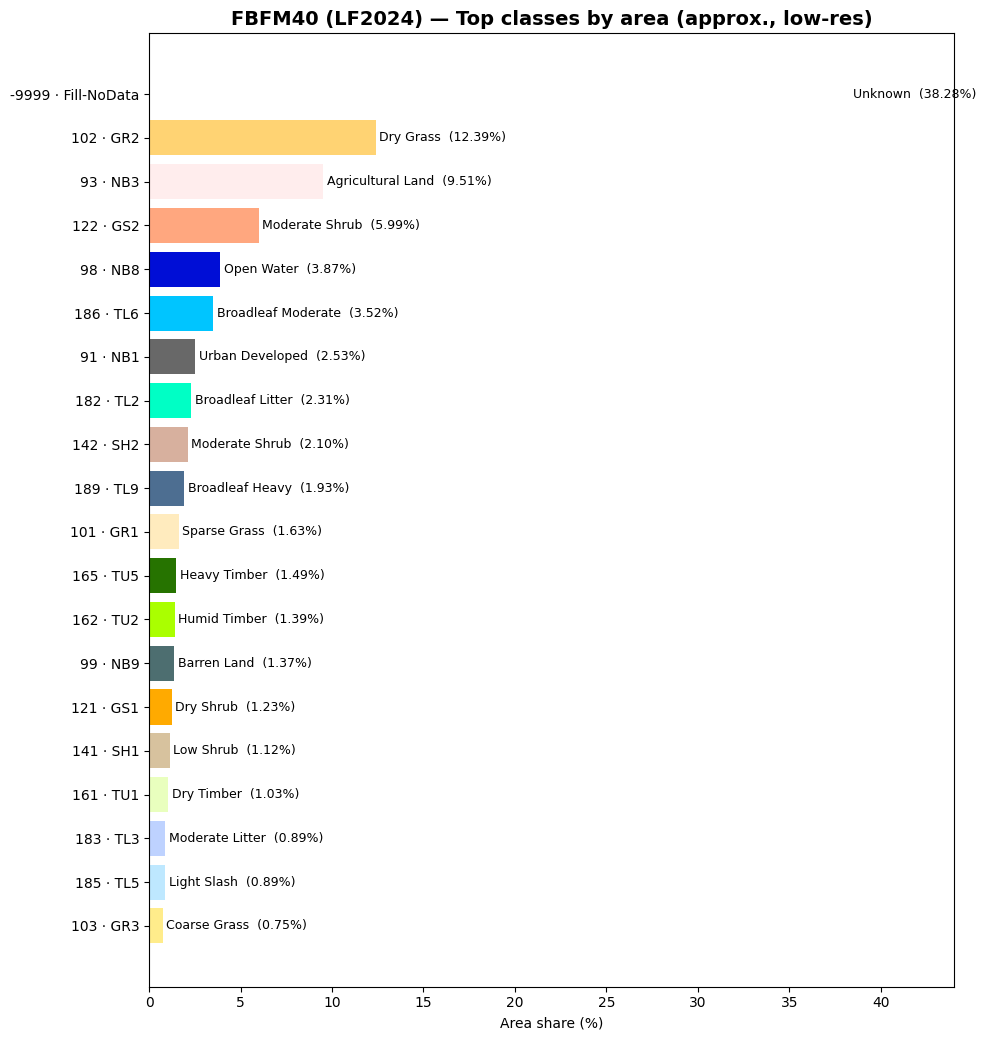

In [ ]:
# Count frequency of each class (using the downsampled raster for speed)
uniq, cnts = np.unique(small, return_counts=True)
freq = (pd.DataFrame({"val": uniq, "count": cnts})
          .sort_values("count", ascending=False))
freq["percent"] = 100 * freq["count"] / freq["count"].sum()

# Map class value → code, description, and color from LUT
freq["code"]  = freq["val"].map(lambda v: lut.get(int(v), ("UNK", "", ""))[0])
freq["desc"]  = freq["val"].map(lambda v: lut.get(int(v), ("", "Unknown", ""))[1])
freq["color"] = freq["val"].map(lambda v: lut.get(int(v), ("", "", "#666"))[2])

# Plot top N classes
N = 20
sub = freq.head(N).iloc[::-1]  # reverse so largest is at the top visually
plt.figure(figsize=(10, 0.45*N + 1.5))
bars = plt.barh(
    y=[f"{int(v)} · {c}" for v, c in zip(sub["val"], sub["code"])],
    width=sub["percent"],
    color=list(sub["color"])
)

plt.xlabel("Area share (%)")
plt.title("FBFM40 (LF2024) — Top classes by area (approx., low-res)", fontsize=14, weight="bold")

# Add text labels with description and percentage
for bar, desc, pct in zip(bars, sub["desc"], sub["percent"]):
    plt.text(bar.get_width() + 0.2,
             bar.get_y() + bar.get_height()/2,
             f"{desc}  ({pct:.2f}%)",
             va="center", fontsize=9)

plt.xlim(0, max(sub["percent"].max()*1.15, 5))
plt.tight_layout()
plt.show()



## 2.6 Fuel Vegetation Classification Map Visualization

After completing the downsampling of the FBFM40 dataset and building the fuel model lookup table (LUT), this step converts the classification results into a color-coded map to show the spatial distribution of different combustible vegetation types across the study area.

Each raster cell's fuel model code is mapped to its corresponding RGB color (from the LUT), producing an intuitive classified color map. Areas marked as NoData or invalid values are displayed in transparent. For clarity, we also select the fuel types with the highest area proportions (based on frequency statistics) to include in the legend, showing their code, description, and color.

This visualization highlights the surface fuel structure across the region and helps identify areas where:


*   Grasslands or shrubs dominate, indicating faster fire spread potential;

*   Forest litter or dead woody fuels dominate, indicating higher fire intensity;
*   Water bodies or bare ground are present, indicating non-burnable zones.


This step establishes the spatial foundation for subsequent wildfire risk assessment and supports understanding of potential fire spread pathways and high-risk areas.

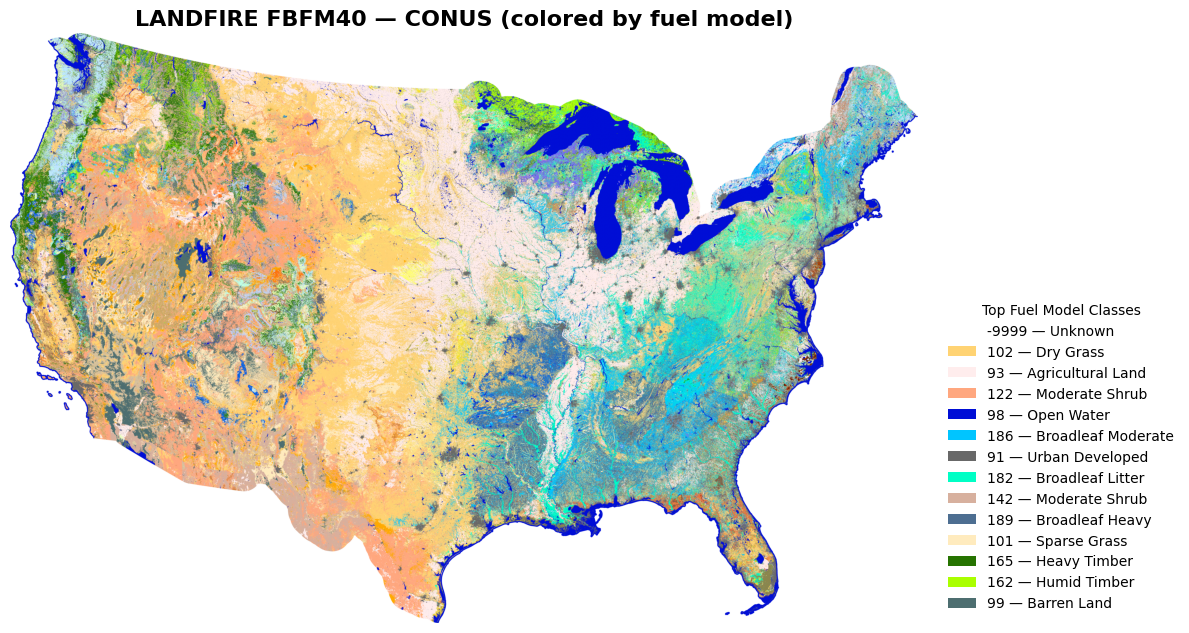

In [ ]:
# small: the downsampled raster
h, w = small.shape

# Mask of valid pixels
valid = np.isfinite(small)

# Initialize RGB and alpha (default to gray for unmapped areas)
rgb = np.zeros((h, w, 3), dtype=float)
rgb[:] = to_rgb("#666666")
alpha = np.ones((h, w), dtype=float)
alpha[~valid] = 0.0

# Color pixels based on LUT (fuel model → RGB)
for v in np.unique(small[valid].astype(int)):
    if v in lut:
        rgb[small == v] = lut[v][2]

# Show top K classes in the legend
K = 14
legend_items = freq.head(K)

plt.figure(figsize=(12, 8))
plt.imshow(rgb, alpha=alpha)
plt.axis("off")
plt.title("LANDFIRE FBFM40 — CONUS (colored by fuel model)", fontsize=16, weight="bold")

# Build legend entries
handles = [
    Patch(facecolor=row["color"], edgecolor="none",
          label=f"{int(row['val'])} — {row['desc']}")
    for _, row in legend_items.iterrows()
]

plt.legend(
    handles=handles,
    loc="lower left",
    bbox_to_anchor=(1.02, 0),
    frameon=False,
    title="Top Fuel Model Classes"
)

plt.tight_layout()
plt.show()


## 2.7 Flammability Level Description

Different fuel models exhibit varying levels of combustibility during wildfires. To facilitate analysis, we categorize the fuel models into five flammability levels and the classification is based on the existing classification criteria in the original PDF (https://landfire.gov/sites/default/files/DataDictionary/LF2023/LF23_F40ADD_240.pdf)

* 1 = Very Low: nearly non-burnable or exhibits very weak fire behavior

* 2 = Low: low combustibility, slow fire spread

* 3 = Moderate: moderate combustibility with noticeable burning and spread potential

* 4 = High: high combustibility, strong fire behavior and rapid spread

* 5 = Extreme: extremely high combustibility, intense fire behavior and very rapid spread

After assigning each fuel model to one of these levels, we obtain a new column, flammability_level.
This metric simplifies the original complex fuel model classification into a form that is more intuitive for comparison and spatial visualization of wildfire risk intensity.

In [ ]:
flammability_levels = {
    # Very Low (1)
    "NB1":1,"NB2":1,"NB3":1,"NB8":1,"NB9":1,
    "TL1":1,"TL2":1,"TL3":1,"TL7":1,

    # Low (2)
    "GR3":2,"GR5":2,"SH3":2,"SH4":2,"TU2":2,"TL4":2,"TL5":2,

    # Moderate (3)
    "GR2":3,"GS1":3,"GS2":3,"GS3":3,"SH2":3,"TU3":3,"TU4":3,
    "TL6":3,"TL8":3,"SB1":3,"SB2":3,

    # High (4)
    "GR4":4,"GR6":4,"SH5":4,"SH6":4,"GS4":4,"TU1":4,"TL9":4,"SB3":4,

    # Extreme (5)
    "GR7":5,"GR8":5,"GR9":5,"SH7":5,"SH8":5,"SH9":5,"TU5":5,"SB4":5,
}


In [ ]:
df_merge["flammability_level"] = df_merge["FBFM40"].map(flammability_levels).fillna(1).astype(int)

## 2.8 Distribution of Flammability Levels

Based on the flammability classification results, we calculated the area proportions of each level across the study region and visualized them with a bar chart. The distribution shows that no single flammability level dominates the landscape; instead, the different levels are relatively balanced in coverage.

This balanced spatial distribution implies that subsequent wildfire spread analysis must account for multiple fire behavior mechanisms, rather than assuming that fire dynamics are driven by a single predominant fuel type.

In [ ]:
# Map pixel VALUE → flammability level (from df_merge info)
value_to_level = {
    int(v): int(flammability_levels.get(code, 1))   # default to level 1 if not defined
    for v, code in zip(df_merge["VALUE"], df_merge["FBFM40"])
}

# Create a level map for the downsampled raster
flam_map = np.zeros_like(small, dtype=np.uint8)

# Keep track of NoData pixels
nodata_mask = ~np.isfinite(small)

# Assign flammability levels
for v in np.unique(small):
    flam_map[small == v] = value_to_level.get(int(v), 0)   # 0 = unknown / fallback

# Restore NoData as 0 explicitly
flam_map[nodata_mask] = 0


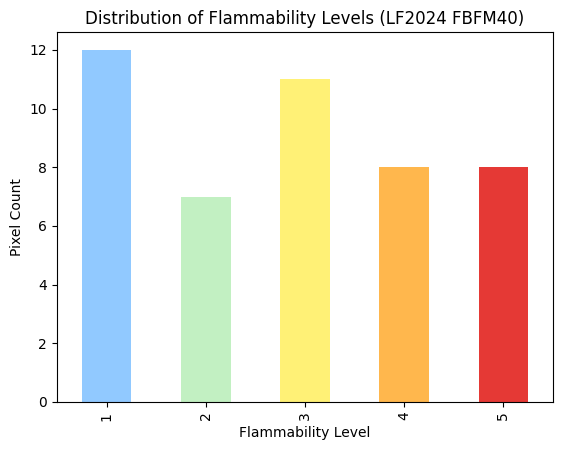

In [ ]:
df_merge["flammability_level"].value_counts().sort_index().plot.bar(
    color=["#91c9ff","#c2f0c2","#fff176","#ffb74d","#e53935"]
)
plt.xlabel("Flammability Level")
plt.ylabel("Pixel Count")
plt.title("Distribution of Flammability Levels (LF2024 FBFM40)")
plt.show()

## 2.9 Flammability Level Spatial Map

This map converts each raster cell’s fuel model into a flammability level (1–5) and applies color rendering to visualize the potential fire intensity across the region. From the spatial patterns, we can clearly observe distinct geographic differences among the flammability levels:

Western areas and certain mountainous regions show a higher concentration of high to extreme flammability fuels (levels 4–5), while central and parts of the eastern region are dominated by low to moderate flammability fuels.

These patterns indicate that vegetation structure and ecological conditions exert a strong spatial influence on wildfire risk.

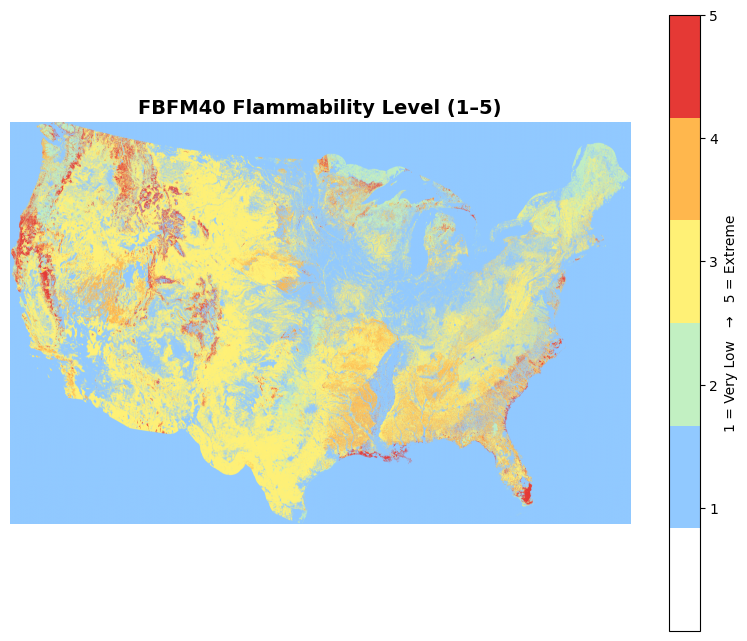

In [ ]:
# Colormap: 0 = transparent (NoData), 1–5 = flammability levels
cmap = ListedColormap(["#00000000", "#91c9ff", "#c2f0c2", "#fff176", "#ffb74d", "#e53935"])

plt.figure(figsize=(10, 8))
plt.imshow(flam_map, cmap=cmap, vmin=0, vmax=5)
plt.title("FBFM40 Flammability Level (1–5)", fontsize=14, weight="bold")
cb = plt.colorbar(ticks=[1, 2, 3, 4, 5], label="1 = Very Low   →   5 = Extreme")
plt.axis("off")
plt.show()


## 2.10 C_index (Composite Flammability Index) Explanation

After computing the proportion \( p_k \) of each fuel type within a grid cell, we weight these proportions by their corresponding flammability levels to obtain the composite flammability index \( C_index):
$$
C_{\text{index}}= \sum_k p_k(\text{cell}) \cdot \text{flammability}(k)
$$
Where:

- C_index represents the area proportion of fuel type \( k \) within the cell.
- flammability(k) is the flammability level assigned to fuel type \( k \) (ranging from 1 to 5).
- k  indexes all fuel types.

This means that if a grid cell contains a larger proportion of high-flammability fuels, the value of C_index will be higher. Conversely, if the cell is dominated by low-flammability or non-burnable fuels, the index will be lower.

Therefore, the C_index essentially reflects the **overall potential fire intensity** of each grid cell.


## 2.11 Calculating the Proportion \(p_k\) for Each Fuel Type

In the downsampled raster, we first extract the fuel model values from all valid cells and count the occurrences of each fuel type across the region. By dividing the number of cells of a given fuel type by the total number of valid cells, we obtain its area proportion \(p_k\) within the study area.

A total proportion close to 100% indicates that the data distribution is consistent and reliable.


In [ ]:
# Get valid pixels and flatten to 1D
valid = np.isfinite(small)
vals_small = small[valid].astype(np.int32)

# Count class occurrences and compute proportions
uniq, cnts = np.unique(vals_small, return_counts=True)
p_df = pd.DataFrame({"FBFM40_class": uniq, "count": cnts})
p_df["p_k"] = p_df["count"] / p_df["count"].sum()

print("Σ p_k =", p_df["p_k"].sum())
p_df = p_df.sort_values("FBFM40_class")


Σ p_k = 0.9999999999999998


## 2.12 Generate Fishnet Grid
Generate a 10 km fishnet grid and compute grid-level pₖ. Aggregate the high-resolution fuel raster to a uniform cell size to obtain each cell’s fuel composition.

This provides the spatial unit foundation for computing the composite flammability index C_index.


In [ ]:
# small: low-res raster (H, W) with values -9999 or 91..204
# scale: downsample factor (e.g., 8 or 4)
base_pixel_m = 250
cell_size_m  = 10000     # 10 km cells
nodata_val   = -9999

# Precompute tiling and grid shape
pixel_m = base_pixel_m * scale
tile    = max(1, int(round(cell_size_m / pixel_m)))
H, W    = small.shape
ncols   = (W + tile - 1) // tile

print(f"tile={tile}, ncols={ncols}, cells≈{((H+tile-1)//tile)*ncols}")

# Build masks and cell ids (fully vectorized)
valid = np.isfinite(small) & (small != nodata_val)
vals  = small[valid].astype(int)

# Keep only 91..204 to be safe
keep  = (vals >= 91) & (vals <= 204)
vals  = vals[keep]
if vals.size == 0:
    raise ValueError("No valid pixels. Check nodata, AOI, or cell_size_m/scale.")

rr, cc = np.nonzero(valid)
rr = rr[keep];  cc = cc[keep]
cell_r = rr // tile
cell_c = cc // tile
cid    = (cell_r * ncols + cell_c).astype(np.int64)

#  Aggregate with pandas: pixel counts per (cell_id, class)
df = pd.DataFrame({"cell_id": cid, "code": vals})
counts = (
    df.value_counts(["cell_id", "code"])
      .rename("cnt")
      .reset_index()
)

# Wide table: rows = cells, cols = classes
wide = counts.pivot(index="cell_id", columns="code", values="cnt").fillna(0).astype(np.uint32)

# Class proportions p_k per cell
den = wide.sum(axis=1).replace(0, 1)   # avoid div-by-zero
pk  = (wide.T / den).T                 # (cells × C)

# Recover grid row/col
row = (pk.index.values // ncols).astype(int)
col = (pk.index.values %  ncols).astype(int)

grid_pk_df = (
    pk.reset_index()
      .rename_axis(None, axis=1)
      .assign(row=row, col=col, total_pix=den.values.astype(int))
      .reindex(columns=["cell_id", "row", "col", "total_pix"] + [c for c in pk.columns])
      .sort_values(["row","col"])
      .reset_index(drop=True)
)

# Sanity check: sum_k p_k ≈ 1
max_dev = (grid_pk_df[pk.columns].sum(axis=1) - 1).abs().max()
print(f"Max |Σp_k-1| = {float(max_dev):.6f},  out_cells = {len(grid_pk_df)}")

# Feature matrix only (p_k by class)
feature_df = grid_pk_df[["cell_id"] + list(pk.columns)]


tile=2, ncols=4885, cells≈15500105
Max |Σp_k-1| = 0.000000,  out_cells = 9573511


In [ ]:
chunk = 500_000
n = len(grid_pk_df)
for i in range(0, n, chunk):
    grid_pk_df.iloc[i:i+chunk].to_parquet(
        f"/content/pk_5km_part_{i//chunk:03d}.parquet",
        index=False, compression="zstd"
    )

## 2.13 Compute and visualize C_index for each grid cell

With the fuel proportions 𝑝_𝑘 and their flammability levels in hand, we take a weighted sum per cell to obtain its C_index, which reflects the cell’s overall burn potential.

We then map C_index back to the grid and render it as a heat map:


*   Lower C_index (blues): weaker flammability.
*   Higher C_index (reds): higher potential intensity and faster spread.

In [ ]:
# Map class VALUE → flammability level
flamm_map = dict(zip(df_merge["VALUE"].astype(int),
                     df_merge["flammability_level"].astype(float)))

# Identify the p_k columns (fuel class proportions per grid cell)
pk_cols = [c for c in grid_pk_df.columns if isinstance(c, int)]

# Create the coefficient vector c_k matching the same column order
ck = np.array([flamm_map.get(c, np.nan) for c in pk_cols], dtype=float)

# Extract p_k matrix
P = grid_pk_df[pk_cols].to_numpy(dtype=float)

# Weighted sum to compute c_index for each grid cell
grid_pk_df["c_index"] = (P * ck).sum(axis=1)
grid_pk_df["c_index"] = grid_pk_df["c_index"].fillna(0.0)


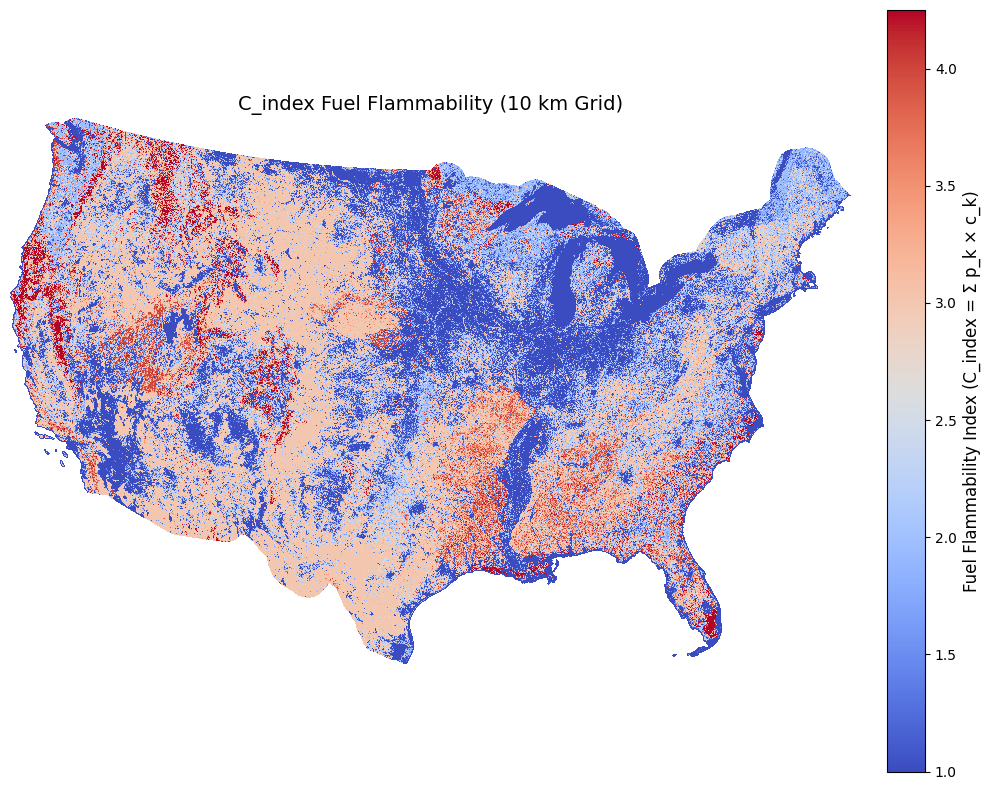

In [ ]:
# 1) rebuild grid (if not already done)
nrows = grid_pk_df["row"].max() + 1
ncols = grid_pk_df["col"].max() + 1

Z = np.full((nrows, ncols), np.nan, dtype=float)
Z[grid_pk_df["row"], grid_pk_df["col"]] = grid_pk_df["c_index"].values

# 2) display range control (to avoid extreme stretching)
vmin = np.nanpercentile(Z, 2)
vmax = np.nanpercentile(Z, 98)

# 3) plot
plt.figure(figsize=(10, 8))

# colormap: Blue → White → Red
im = plt.imshow(
    Z,
    origin="upper",
    interpolation="nearest",
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax
)

# colorbar
cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.set_label("Fuel Flammability Index (C_index = Σ p_k × c_k)", fontsize=12)

# title
plt.title("C_index Fuel Flammability (10 km Grid)", fontsize=14)

# remove axes
plt.axis("off")

plt.tight_layout()
plt.show()


## 2.14 Import Wildfire Data and Join with C_index

We now bring in the observed wildfire dataset, which records each fire’s location (latitude/longitude) and time. The goal is to spatially link these points to the 10 km grid–level flammability index (C_index) computed earlier, so that every wildfire record carries the flammability level of the grid where it occurred.

Concretely, we map each fire point to its corresponding grid cell using its coordinates, then attach that cell’s C_index value to the record. As a result, each wildfire event is described not only by where and when it happened, but also by a quantitative summary of the local surface fuel conditions.

In [ ]:
grid_pk_df.head()

,cell_id,row,col,total_pix,91,92,93,98,99,101,...,185,186,187,188,189,201,202,203,204,c_index
0,371,0,371,1,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
1,372,0,372,2,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
2,373,0,373,2,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
3,374,0,374,2,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
4,375,0,375,2,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0


In [ ]:
wildfire.head()

,latitude,longitude,datetime,Wildfire,pr,rmax,rmin,sph,srad,tmmn,...,bi,fm100,fm1000,erc,etr,pet,vpd,year,month,day
0,48.128431,-97.276685,2018-08-15,No,0.0,78.6,14.9,0.00582,272.6,282.0,...,40.0,10.2,12.2,54.0,7.5,5.5,1.59,2018,8,15
1,48.128431,-97.276685,2018-08-16,No,0.0,80.4,13.9,0.00676,264.0,283.9,...,40.0,9.7,12.0,56.0,8.2,5.9,1.93,2018,8,16
2,48.128431,-97.276685,2018-08-17,No,0.0,70.9,20.4,0.00672,265.6,285.8,...,40.0,9.2,11.9,56.0,7.2,5.3,1.51,2018,8,17
3,48.128431,-97.276685,2018-08-18,No,5.0,65.2,19.4,0.00756,261.4,289.0,...,0.0,9.9,12.0,40.0,10.0,6.9,1.85,2018,8,18
4,48.128431,-97.276685,2018-08-19,No,0.0,100.0,42.2,0.00895,166.8,283.8,...,41.0,11.8,12.1,47.0,4.6,3.4,0.66,2018,8,19


## 2.15 Spatial Association Between Wildfire Events and C_index(Example: 2018)

After joining the wildfire dataset with the grid-level **C_index**, we select a specific year (e.g., 2018) and visualize only the records where wildfires actually occurred. Black points represent the observed wildfire locations for that year, while the background map shows the corresponding **C_index** of each grid cell (with colors ranging from blue = low to red = high flammability).

From the map, we can clearly observe that:

- Wildfire events are predominantly concentrated in areas with **higher C_index** (medium to extremely high flammability).
- In low-flammability blue regions, wildfire occurrences are noticeably sparse.
- Western and mountainous regions with drier vegetation show a pattern of **high fuel intensity → higher wildfire concentration**.
- Central and eastern regions tend to show **lower flammability** and fewer wildfire points.

These observations indicate that:

**The spatial fuel structure (as captured by C_index) is strongly correlated with wildfire occurrence.**

In other words, areas with concentrated high-flammability fuels are more likely to experience wildfire events, and once ignited, fires in these areas tend to have greater spread potential. This supports the effectiveness and practical relevance of the **C_index** metric in reflecting real-world wildfire risk.


In [ ]:
import geopandas as gpd
from shapely.geometry import Point
import rasterio
from rasterio.enums import Resampling
from rasterio.transform import array_bounds
from affine import Affine
from rasterio.transform import rowcol

In [ ]:
# Tunable params
year = 2018                  # target year
base_pixel_m = 250           # native Landfire resolution (m)
cell_size_m  = 10000         # 10km grid
scale        = 16            # keep consistent with earlier
nodata_val   = -9999

# A) Read downsampled raster + compute transform
with rasterio.open(tif_path) as src:
    H0, W0 = src.height, src.width
    out_h, out_w = H0 // scale, W0 // scale

    small = src.read(
        1,
        out_shape=(out_h, out_w),
        resampling=getattr(Resampling, "mode", Resampling.nearest)
    )
    # Clean with file nodata
    if src.nodata is not None:
        small = np.where(small == src.nodata, np.nan, small)

    # Downsampled transform (pixel size ×= scale)
    T_down = src.transform * Affine.scale(scale)
    raster_crs = src.crs  # EPSG:5070

# B) 10km grid transform (matches grid_pk_df row/col)
pixel_m = base_pixel_m * scale
tile    = max(1, int(round(cell_size_m / pixel_m)))
T_cell  = T_down * Affine.scale(tile)

# C) Fold c_index back to 2D
nrows = grid_pk_df["row"].max() + 1
ncols = grid_pk_df["col"].max() + 1
Z = np.full((nrows, ncols), np.nan, dtype=float)
Z[grid_pk_df["row"], grid_pk_df["col"]] = grid_pk_df["c_index"].to_numpy()

xmin, ymin, xmax, ymax = array_bounds(nrows, ncols, T_cell)


[DEBUG] Wildfire = Yes, points: 42195
[DEBUG] Wildfire = No, points: 928306


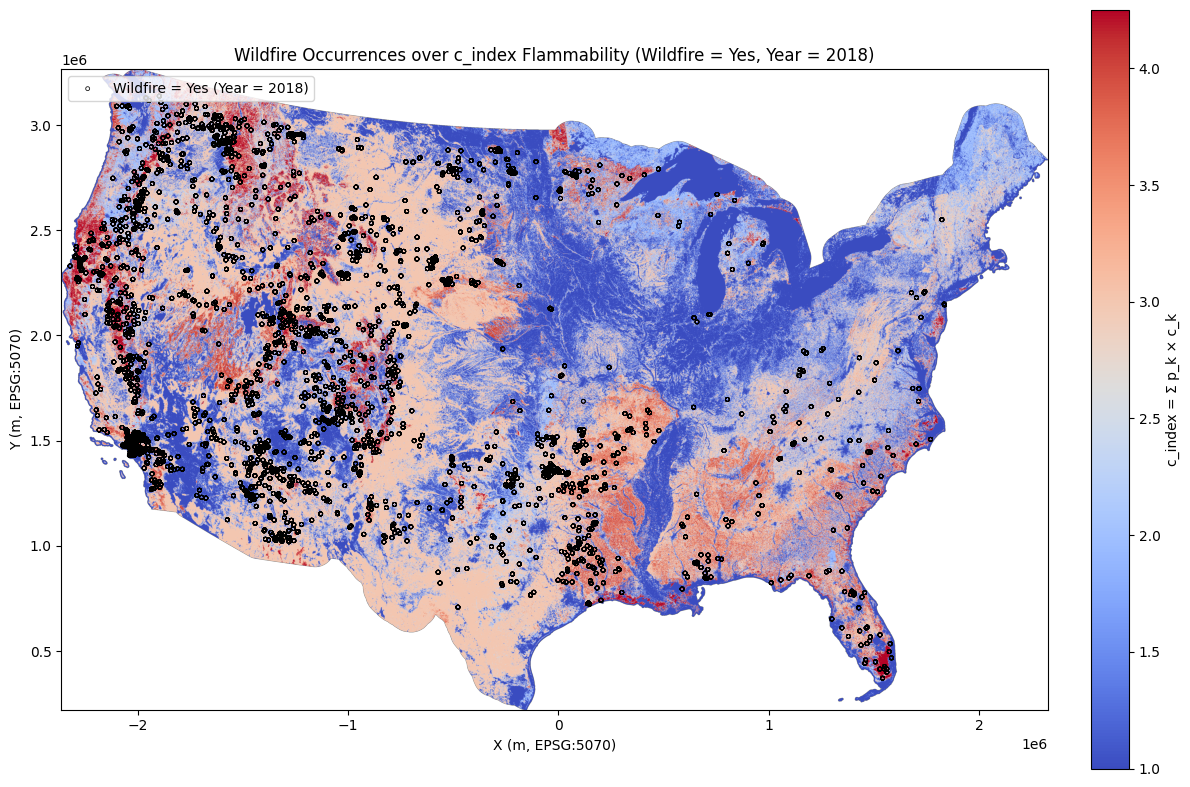

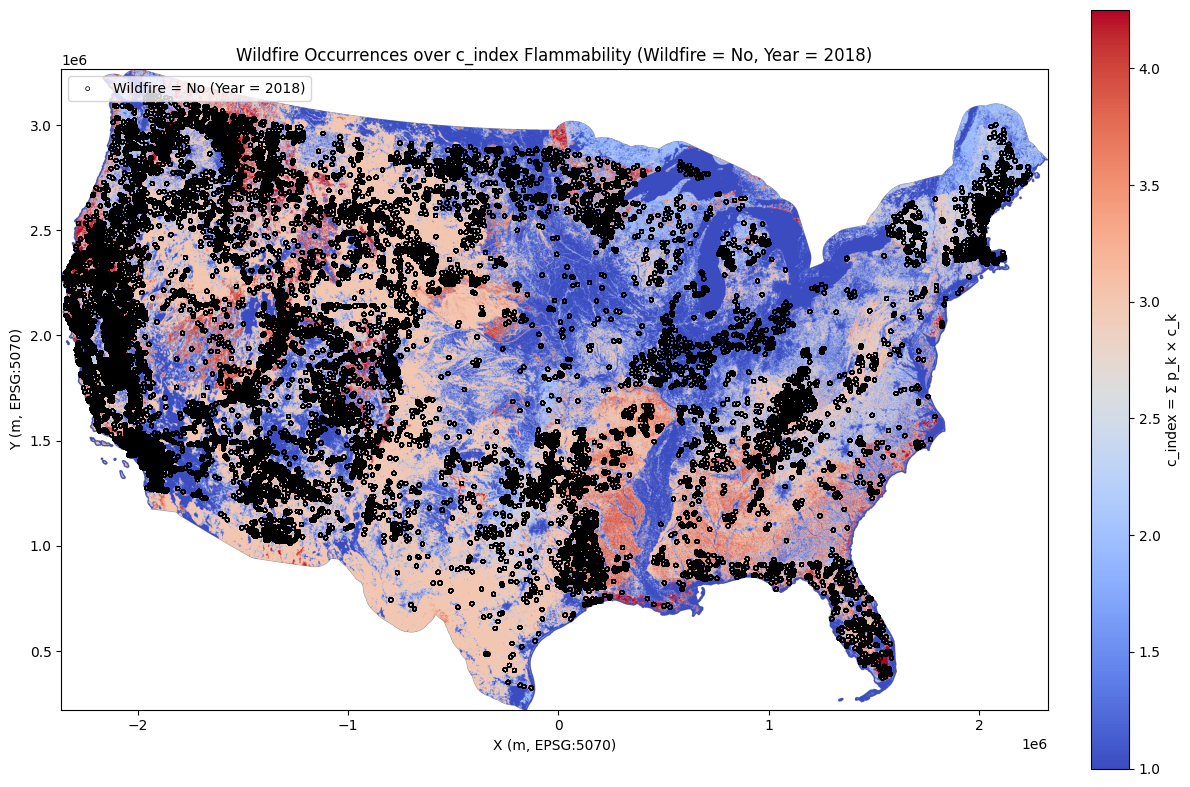

In [ ]:
# D) Prepare wildfire points: filter by year & Wildfire flag
# Expect wildfire DataFrame with longitude/latitude/datetime/Wildfire
if not isinstance(wildfire, pd.DataFrame):
    raise ValueError("Need a `wildfire` DataFrame (longitude/latitude/datetime/Wildfire).")

# 1) To GeoDataFrame (lon/lat)
wildfire_gdf = gpd.GeoDataFrame(
    wildfire.copy(),
    geometry=gpd.points_from_xy(wildfire["longitude"], wildfire["latitude"]),
    crs="EPSG:4326"
)

# 2) Normalize Wildfire flag → bool: Yes / not-Yes
wildfire_gdf["_wildfire_yes"] = (
    wildfire_gdf["Wildfire"].astype(str).str.strip().str.lower().isin(["yes"])
)

# 3) Common year mask
mask_year = wildfire_gdf["year"].eq(year)

gdfs = {}
for label, is_yes in [("Yes", True), ("No", False)]:
    mask_flag = wildfire_gdf["_wildfire_yes"].eq(is_yes)
    pts = wildfire_gdf.loc[
        mask_year & mask_flag & wildfire_gdf.geometry.notna(),
        ["longitude", "latitude", "geometry"]
    ].copy()
    # Reproject to raster CRS
    gdfs[label] = pts.to_crs(raster_crs)
    print(f"[DEBUG] Wildfire = {label}, points: {len(gdfs[label])}")

# E) Plot overlay (two separate figures)
vmin = np.nanpercentile(Z, 2)
vmax = np.nanpercentile(Z, 98)

def plot_wildfire_map(pts5070, label, year, Z, xmin, xmax, ymin, ymax,
                      vmin, vmax):
    fig, ax = plt.subplots(figsize=(12, 8))
    im = ax.imshow(
        Z,
        origin="upper",
        extent=(xmin, xmax, ymin, ymax),
        cmap="coolwarm",
        vmin=vmin, vmax=vmax
    )

    ax.scatter(
        pts5070.geometry.x.values,
        pts5070.geometry.y.values,
        s=8, facecolors="none", edgecolors="k",
        linewidths=0.6, alpha=0.9,
        label=f"Wildfire = {label} (Year = {year})"
    )

    ax.set_aspect("equal")
    ax.set_xlabel("X (m, EPSG:5070)")
    ax.set_ylabel("Y (m, EPSG:5070)")
    ax.set_title(f"Wildfire Occurrences over c_index Flammability "
                 f"(Wildfire = {label}, Year = {year})")

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("c_index = Σ p_k × c_k")

    ax.legend(loc="upper left", frameon=True)
    plt.tight_layout()
    plt.show()

plot_wildfire_map(gdfs["Yes"], "Yes", year, Z, xmin, xmax, ymin, ymax, vmin, vmax)
plot_wildfire_map(gdfs["No"],  "No",  year, Z, xmin, xmax, ymin, ymax, vmin, vmax)


 **Wildfire vs. Non-Wildfire Data Overlap Analysis**

By comparing the geospatial distribution of Wildfire = Yes and Wildfire = No occurrences across the United States (example shown using Year = 2018 samples), we observe a high degree of spatial overlap between the two classes. Both positive and negative samples are densely mixed throughout most major regions. This indicates the following issues:

1. Strong Spatial Homogeneity in Sampling



*  Wildfire occurrence points and non-occurrence points share similar or nearly identical environmental backgrounds.
*  There is a lack of clear spatial separation boundaries, reducing the ability for spatial features to differentiate between classes.

2. Low Discriminative Power of Environmental Features


*   Since most Yes and No samples exist under similar vegetation fuel conditions, climate settings, and terrain characteristics,the environmental features used as model inputs (e.g., c_index) show limited class-specific variability.
*   As a result, the model may struggle to learn meaningful distinctions related to wildfire drivers.

## 2.16 Map Wildfire Records to the C_index Grid

After computing the C_index for each grid cell, we align the observed wildfire records to this spatial grid. Since the wildfire dataset includes the latitude–longitude of each event, we snap each point to its corresponding grid cell (row, col) and then attach that cell’s C_index value to the wildfire record.

In [ ]:
base_pixel_m = 250
cell_size_m  = 10000
scale        = 16

# 1) Get the transform after downsampling
with rasterio.open(tif_path) as src:
    T_down = src.transform * Affine.scale(scale)

# One pixel in the downsampled image = base_pixel_m * scale meters
pixel_m = base_pixel_m * scale

# How many of those pixels make one 10km grid cell
tile    = max(1, int(round(cell_size_m / pixel_m)))

# Transform for the grid-level cells
T_cell  = T_down * Affine.scale(tile)

# Grid size (number of rows/cols in c_index grid)
nrows = int(grid_pk_df["row"].max()) + 1
ncols = int(grid_pk_df["col"].max()) + 1

grid_key = grid_pk_df[["row", "col", "c_index"]].copy()

# 2) Convert wildfire points to GeoDataFrame and reproject to match raster
wildfire_gdf = gpd.GeoDataFrame(
    wildfire,
    geometry=gpd.points_from_xy(wildfire["longitude"], wildfire["latitude"]),
    crs="EPSG:4326"
).to_crs("EPSG:5070")

# 3) For each point, find which grid cell (row, col) it falls into
x = wildfire_gdf.geometry.x.values
y = wildfire_gdf.geometry.y.values

cols, rows = rowcol(T_cell, x, y, op=np.floor)
rows = rows.astype(int)
cols = cols.astype(int)

# Keep only points that fall inside the grid extent
inside = (rows >= 0) & (rows < nrows) & (cols >= 0) & (cols < ncols)

# Points outside the grid get (-1, -1) so merge won't break
rowcol_df = pd.DataFrame({"row": rows, "col": cols}, index=wildfire_gdf.index)
rowcol_df.loc[~inside, ["row","col"]] = -1

# 4) Attach c_index based on grid cell
merged = rowcol_df.merge(grid_key, how="left", on=["row","col"]).set_index(wildfire_gdf.index)
wildfire_gdf["c_index"] = merged["c_index"].values

# wildfire_gdf now has a c_index column for each point


## 2.17 Checking Missing C_index Matches in Wildfire Data

This step is used to identify wildfire records where the matched C_index value is missing (NaN) and analyze the possible reasons. Since wildfire points are spatially joined with the 10 km grid, there are two main causes for missing values:

**1. Points Outside the Grid**

The original FBFM40 raster does not fully cover the entire U.S. mainland. Areas near borders, lakes, or regions with steep terrain (e.g., along the Hudson River, the Great Lakes, or the northeastern corner of New York) may contain no valid fuel model pixels.
During the grid mapping process, such points are flagged with row or col = -1, indicating that they fall outside any 10 km grid cell.

**2. Points Inside the Grid but Without Valid Fuel Values**

As previously noted in the fuel-type statistics, many FBFM40 pixels have a value of -9999, representing NoData.
If a wildfire point falls into a grid cell dominated by these NoData pixels, it still cannot obtain a valid C_index after merging.
In this case, the point lies within the grid extent but the corresponding cell lacks flammability information—hence the C_index remains missing.

In [ ]:
# attach the (row, col) back to wildfire_gdf so it's easier to debug later
wildfire_gdf[["row", "col"]] = rowcol_df

# 1) find all wildfire points that didn’t get a c_index
missing_mask = wildfire_gdf["c_index"].isna()
missing_points = wildfire_gdf[missing_mask]

print(f"Total points: {len(wildfire_gdf)}")
print(f"Points with missing c_index: {len(missing_points)}")

# 2) check whether they fall outside the 10km grid
outside_mask = (missing_points["row"] == -1) | (missing_points["col"] == -1)

outside_points = missing_points[outside_mask]
inside_no_cindex = missing_points[~outside_mask]

print(f"-points outside the grid (row/col = -1): {len(outside_points)}")
print(f"-points inside the grid but no c_index: {len(inside_no_cindex)}")

# 3) show a few examples to see roughly where they are
print("\n[Example] points outside the grid:")
print(outside_points[["longitude", "latitude", "row", "col"]].head())

print("\n[Example] points inside the grid but no c_index:")
print(inside_no_cindex[["longitude", "latitude", "row", "col"]].head())


Total points: 9509925
Points with missing c_index: 2779950
-points outside the grid (row/col = -1): 1383825
-points inside the grid but no c_index: 1396125

[Example] points outside the grid:
     longitude  latitude  row  col
900   -74.8772   41.3897   -1   -1
901   -74.8772   41.3897   -1   -1
902   -74.8772   41.3897   -1   -1
903   -74.8772   41.3897   -1   -1
904   -74.8772   41.3897   -1   -1

[Example] points inside the grid but no c_index:
   longitude   latitude   row  col
0 -97.276685  48.128431  2360  494
1 -97.276685  48.128431  2360  494
2 -97.276685  48.128431  2360  494
3 -97.276685  48.128431  2360  494
4 -97.276685  48.128431  2360  494


## 2.18 Handling Missing C_index Values

We follow two simple rules for wildfire records with missing C_index:

**A. Inside the Grid but Missing Valid Fuel Data → Fill Using KDTree**

Some points fall inside the 10 km grid but correspond to -9999 pixels in the original FBFM40 raster (e.g., water bodies, bare ground, or non-burnable surfaces).
Instead of assigning these locations a value of 0, we interpolate their c_index values using a KDTree, which finds the nearest grid cell with valid fuel data and transfers its flammability value.

**B. Outside the Grid → Remove**

A small number of wildfire points fall outside the FBFM40 coverage (border regions, large lakes, unmodeled gaps).
They cannot be matched to any valid grid cell, so we remove them from the dataset.

In [ ]:
mask_inside_grid = (wildfire_gdf["row"] >= 0) & (wildfire_gdf["col"] >= 0)
wildfire_gdf = wildfire_gdf.loc[mask_inside_grid].copy()

In [ ]:
valid_cells = grid_pk_df[["row", "col", "c_index"]].copy()
valid_coords = valid_cells[["row", "col"]].to_numpy(dtype=float)
valid_ci     = valid_cells["c_index"].to_numpy(dtype=float)

tree = KDTree(valid_coords)


missing_mask   = wildfire_gdf["c_index"].isna()
missing_coords = wildfire_gdf.loc[missing_mask, ["row", "col"]].to_numpy(dtype=float)

print("Need KDTree interpolation for points:", missing_coords.shape[0])

if missing_coords.size > 0:
    dist, idx = tree.query(missing_coords, k=1)
    wildfire_gdf.loc[missing_mask, "c_index"] = valid_ci[idx[:, 0]]

print("Missing c_index after KDTree:", wildfire_gdf["c_index"].isna().sum())


Need KDTree interpolation for points: 1396125
Missing c_index after KDTree: 0


## 2.19 Analysis of c_index Distribution in Wildfire vs. Non-Wildfire Samples

To assess whether the flammability index (c_index) can effectively differentiate wildfire occurrence, we examined three types of distribution comparisons:
1.   Histogram + KDE by wildfire label
2.   Overlapped KDE curves (Yes vs. No)
3.   Boxplot comparison

Across all these perspectives, we find consistently high similarity between the two classes.

**Key Findings:**
1. Substantial Overlap in KDE Density Curves
  *    Both wildfire Yes and No samples show identical modal peaks at ~1.0, 2.0, and 3.0
  *   No distinguishable threshold or class-specific distribution shape
  *   Indicates low discriminative power of c_index

2. Boxplot Shows Nearly Identical Summary Statistics

**Conclusion:**
Despite being a core flammability feature, c_index lacks the ability to differentiate wildfire vs. non-wildfire outcomes in its current form, necessitating stronger causal and environmental features.













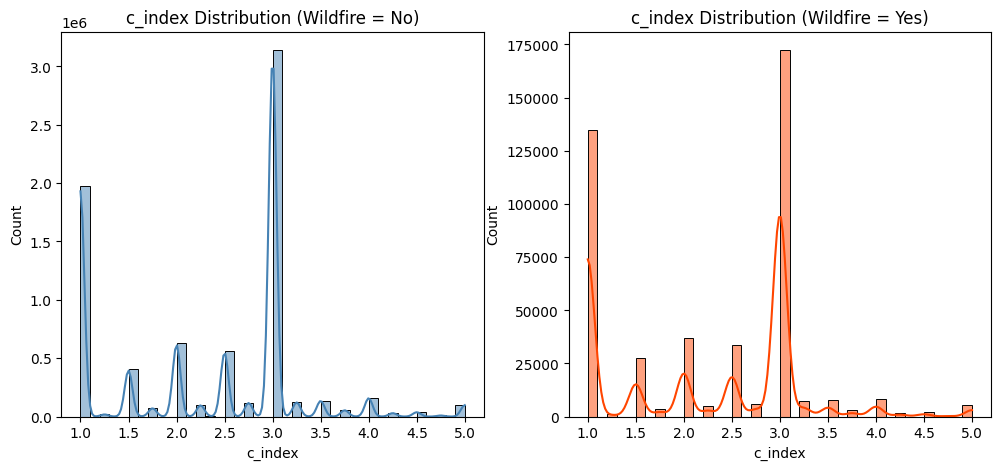

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(
    wildfire_gdf[wildfire_gdf["Wildfire"]=="No"]["c_index"],
    bins=40, kde=True, color="steelblue"
)
plt.title("c_index Distribution (Wildfire = No)")

plt.subplot(1,2,2)
sns.histplot(
    wildfire_gdf[wildfire_gdf["Wildfire"]=="Yes"]["c_index"],
    bins=40, kde=True, color="orangered"
)
plt.title("c_index Distribution (Wildfire = Yes)")

plt.show()


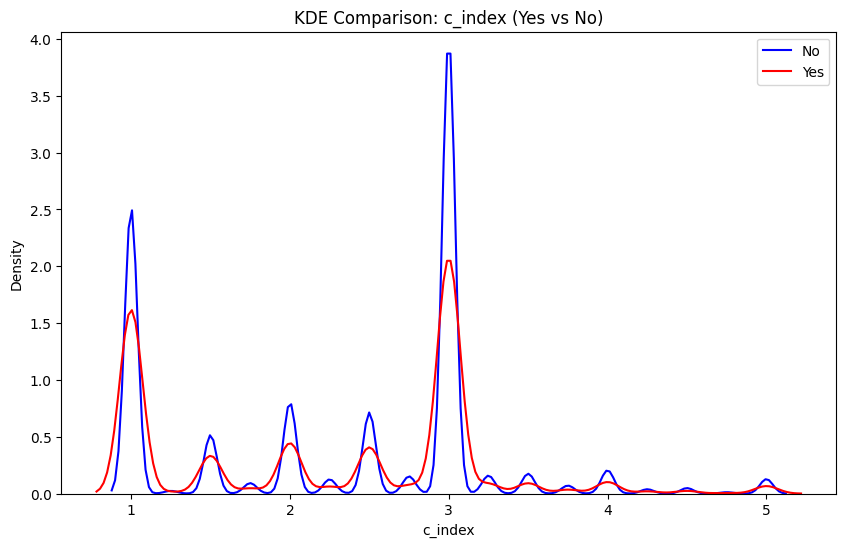

In [ ]:
plt.figure(figsize=(10,6))
sns.kdeplot(
    wildfire_gdf[wildfire_gdf["Wildfire"]=="No"]["c_index"],
    fill=False, color="blue", label="No"
)
sns.kdeplot(
    wildfire_gdf[wildfire_gdf["Wildfire"]=="Yes"]["c_index"],
    fill=False, color="red", label="Yes"
)
plt.legend()
plt.title("KDE Comparison: c_index (Yes vs No)")
plt.show()


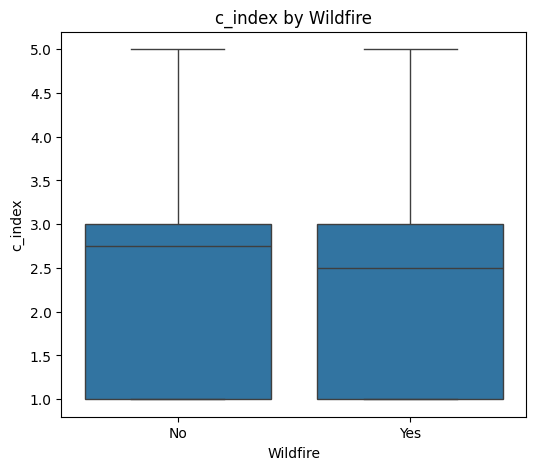

In [ ]:
plt.figure(figsize=(6,5))

sns.boxplot(
    data=wildfire_gdf,
    x="Wildfire",
    y="c_index"
)

plt.title("c_index by Wildfire")
plt.xlabel("Wildfire")
plt.ylabel("c_index")

plt.show()


In [ ]:
# Save new dataframe
wildfire_clean_Cindex = pd.DataFrame(wildfire_gdf.drop(columns=["geometry"]))
wildfire_clean_Cindex.head()


,latitude,longitude,datetime,Wildfire,pr,rmax,rmin,sph,srad,tmmn,...,erc,etr,pet,vpd,year,month,day,c_index,row,col
0,48.128431,-97.276685,2018-08-15,No,0.0,78.6,14.9,0.00582,272.6,282.0,...,54.0,7.5,5.5,1.59,2018,8,15,3.0,2360,494
1,48.128431,-97.276685,2018-08-16,No,0.0,80.4,13.9,0.00676,264.0,283.9,...,56.0,8.2,5.9,1.93,2018,8,16,3.0,2360,494
2,48.128431,-97.276685,2018-08-17,No,0.0,70.9,20.4,0.00672,265.6,285.8,...,56.0,7.2,5.3,1.51,2018,8,17,3.0,2360,494
3,48.128431,-97.276685,2018-08-18,No,5.0,65.2,19.4,0.00756,261.4,289.0,...,40.0,10.0,6.9,1.85,2018,8,18,3.0,2360,494
4,48.128431,-97.276685,2018-08-19,No,0.0,100.0,42.2,0.00895,166.8,283.8,...,47.0,4.6,3.4,0.66,2018,8,19,3.0,2360,494


## 2.20 Dealing Multicollinearity

In [ ]:
wildfire_clean = wildfire_clean_Cindex.drop(columns=['row', 'col']).copy()
wildfire_clean.head()

,latitude,longitude,datetime,Wildfire,pr,rmax,rmin,sph,srad,tmmn,...,fm100,fm1000,erc,etr,pet,vpd,year,month,day,c_index
0,48.128431,-97.276685,2018-08-15,No,0.0,78.6,14.9,0.00582,272.6,282.0,...,10.2,12.2,54.0,7.5,5.5,1.59,2018,8,15,3.0
1,48.128431,-97.276685,2018-08-16,No,0.0,80.4,13.9,0.00676,264.0,283.9,...,9.7,12.0,56.0,8.2,5.9,1.93,2018,8,16,3.0
2,48.128431,-97.276685,2018-08-17,No,0.0,70.9,20.4,0.00672,265.6,285.8,...,9.2,11.9,56.0,7.2,5.3,1.51,2018,8,17,3.0
3,48.128431,-97.276685,2018-08-18,No,5.0,65.2,19.4,0.00756,261.4,289.0,...,9.9,12.0,40.0,10.0,6.9,1.85,2018,8,18,3.0
4,48.128431,-97.276685,2018-08-19,No,0.0,100.0,42.2,0.00895,166.8,283.8,...,11.8,12.1,47.0,4.6,3.4,0.66,2018,8,19,3.0


From the perspective of redundancy, we should remove `row` and `col` because they introduce significant multicollinearity by encoding the exact same spatial information as `latitude` and `longitude`. Since the dataset already possesses these continuous, universal geographic coordinates to pinpoint location, the discrete grid indices (`row` and `col`) provide no additional predictive signal or unique variance for the model to learn from. Retaining these duplicate spatial representations would merely clutter the feature space. Moreover, the c_index, which represents the composite flammability of local vegetation, shows a multi modal distribution with several peaks that reflect distinct vegetation compositions across regions.

# Part 3: Exploratory Data Analysis

## 3.1 Univariate Analysis

In [ ]:
numeric_cols = wildfire_clean.select_dtypes(include=['float64', 'int64']).columns.tolist()
numeric_cols

['latitude',
 'longitude',
 'pr',
 'rmax',
 'rmin',
 'sph',
 'srad',
 'tmmn',
 'tmmx',
 'vs',
 'bi',
 'fm100',
 'fm1000',
 'erc',
 'etr',
 'pet',
 'vpd',
 'year',
 'month',
 'day',
 'c_index']

### 3.1.1 Histogram (Numerical Variables)

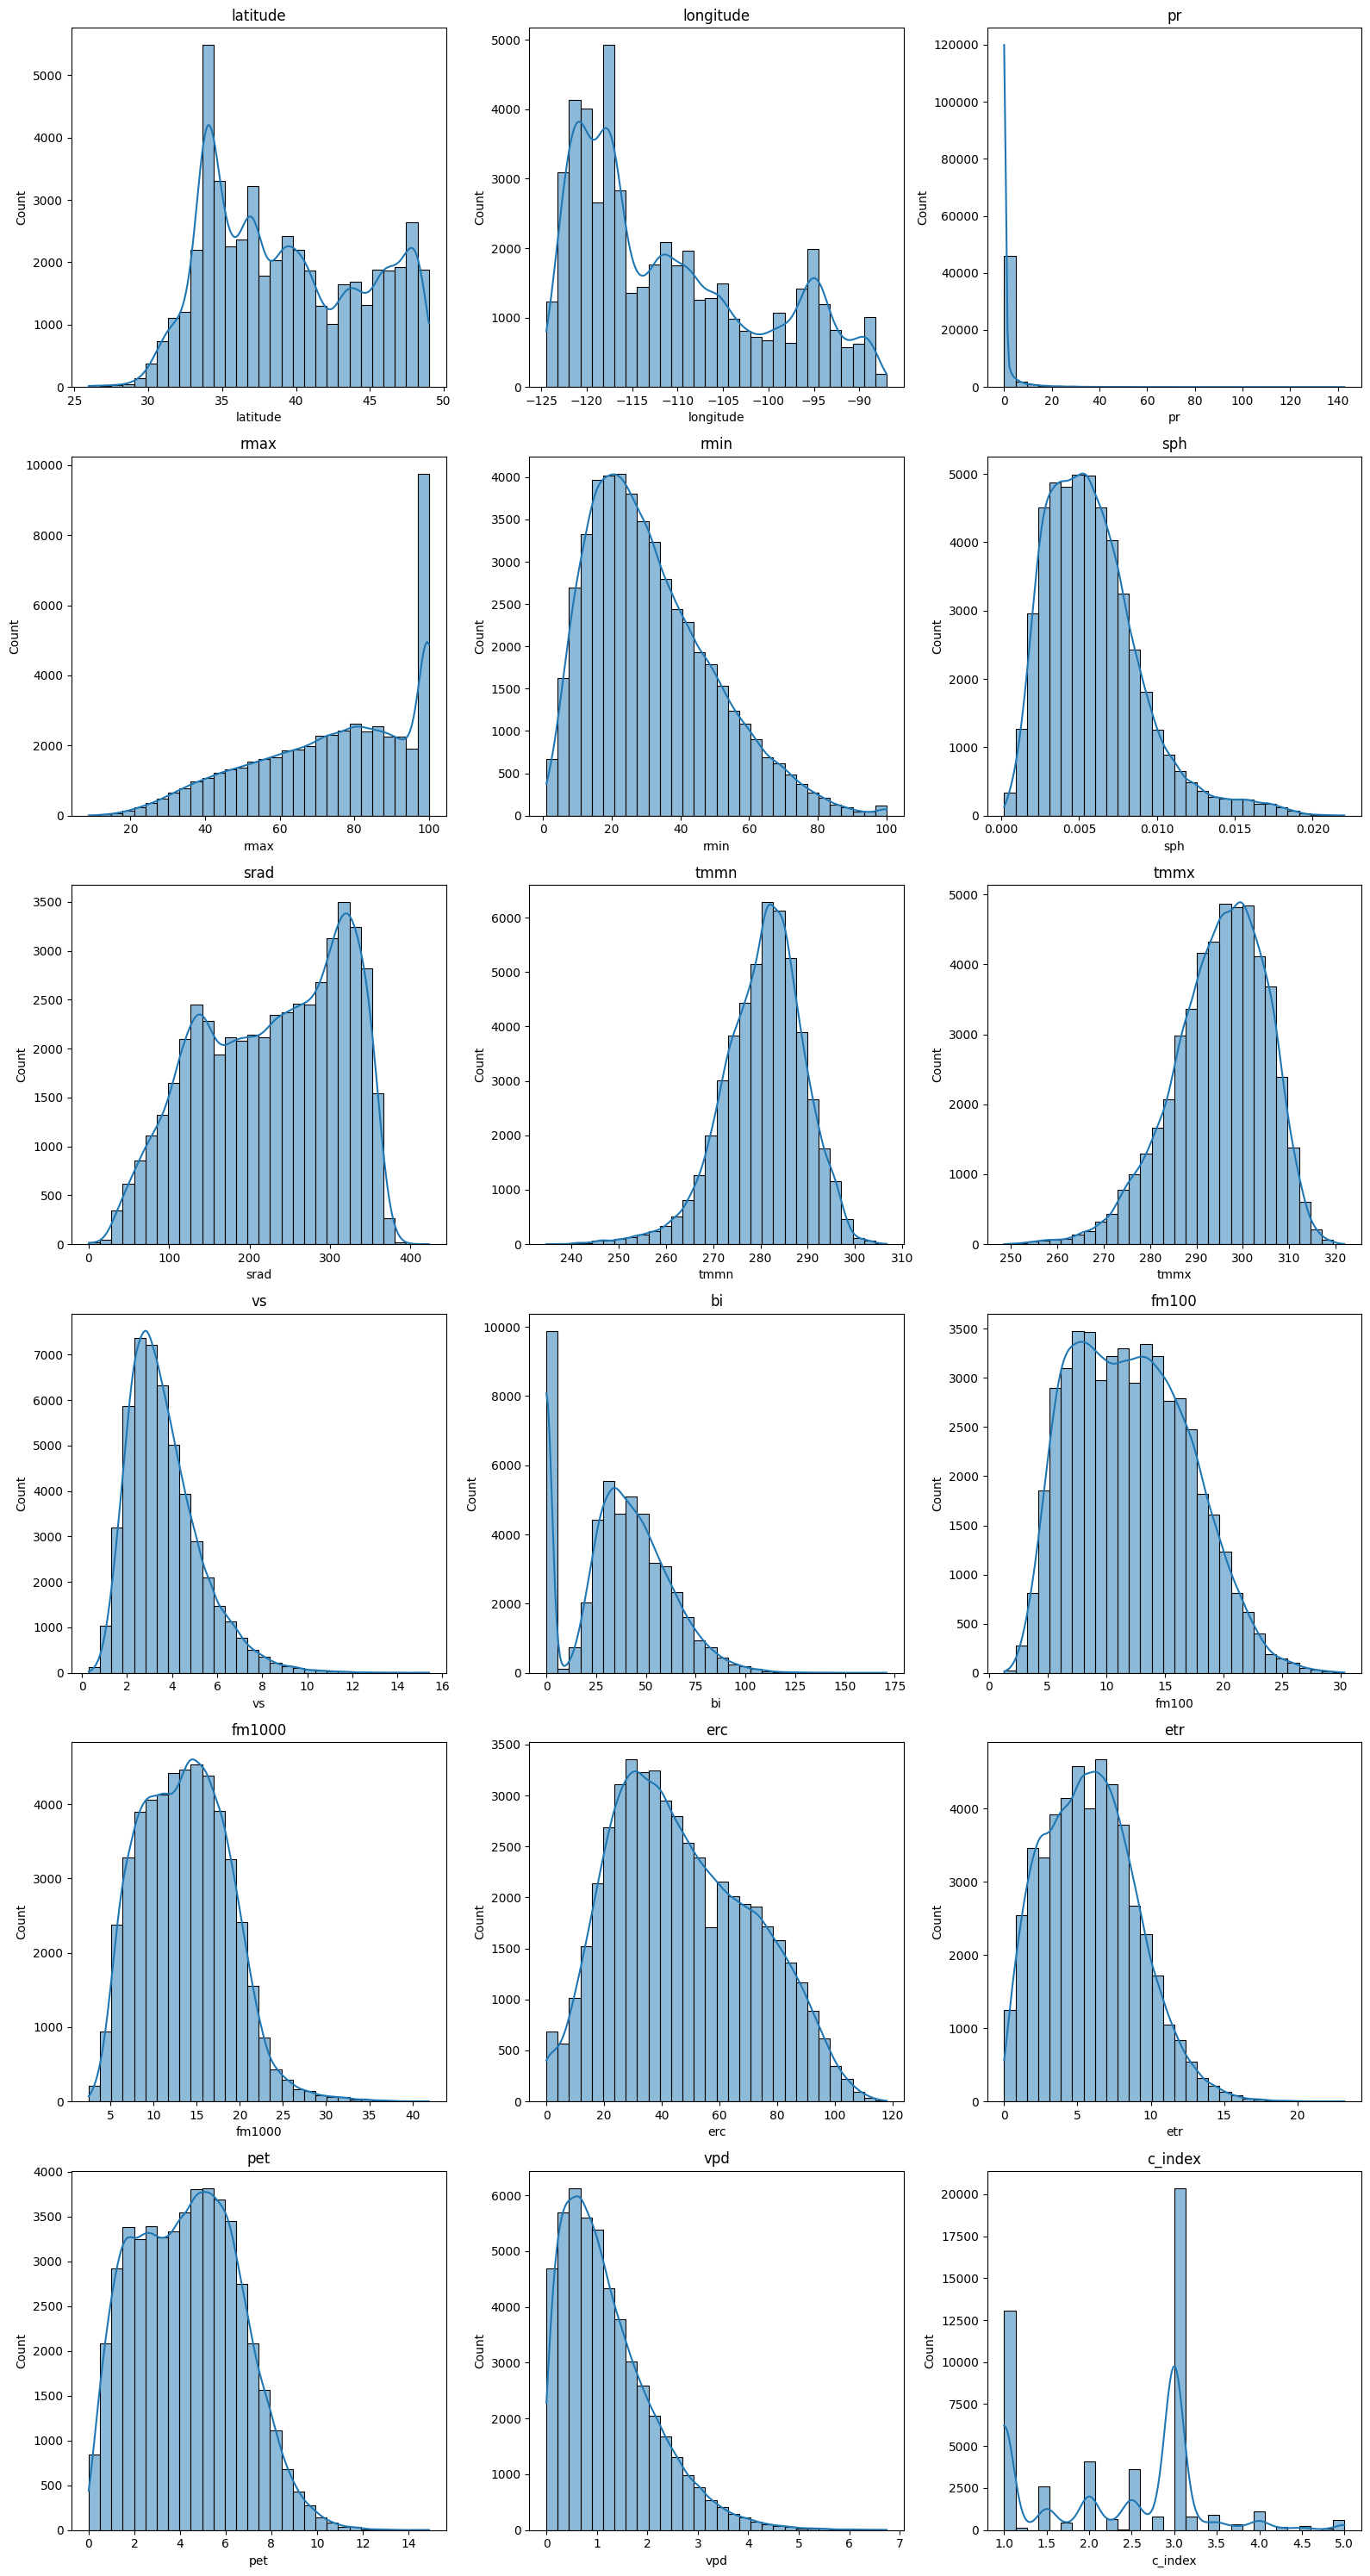

In [ ]:
numeric_cols = [
    col for col in wildfire_clean.select_dtypes(include=['float64', 'int64']).columns
    if col not in ['year', 'month', 'day']
]

# sample data for speed
SAMPLE_N = 50000
wildfire_sample = wildfire_clean.sample(min(SAMPLE_N, len(wildfire_clean)), random_state=42)

# count how many numerical variables we need to plot
n_vars = len(numeric_cols)

# arrange plots in a grid with 3 columns
n_cols = 3

# compute how many rows are needed to fit all variables
n_rows = math.ceil(n_vars / n_cols)

# create the subplot grid
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
axes = axes.flatten()

# Plot each numerical variable
for i, col in enumerate(numeric_cols):
    sns.histplot(wildfire_sample[col], kde=True, ax=axes[i], bins=30)
    axes[i].set_title(col, fontsize=12)

# hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


Across all numerical variables in the cleaned wildfire dataset, most environmental features show clearly skewed and non normal distributions that reflect the diverse climatic conditions across the United States. Variables such as precipitation, wind speed, vapor pressure deficit, and solar radiation are strongly right skewed, which means that very high values appear only occasionally while lower values dominate the observations. Temperature based variables, including daily maximum and minimum temperatures, display shapes that resemble more typical seasonal weather patterns, although several still show mild skewness. Features such as the burning index, potential evapotranspiration, and vapor pressure deficit contain long heavy right tails, indicating that extreme conditions occur for only a small portion of the data but may strongly influence fire behavior. The geographic variables latitude and longitude follow patterns driven by the spatial coverage of the dataset rather than any physical distribution. The c_index, which represents the composite flammability of local vegetation, shows a multi modal distribution with several peaks that reflect distinct vegetation compositions across regions. A large concentration of values around three indicates that many grid cells contain moderately flammable fuel types, while smaller peaks near zero, one, and higher values represent areas dominated by low flammability or very flammable vegetation. Taken together, the histograms confirm that the dataset contains a mix of distribution shapes, and that many variables deviate substantially from a normal distribution. This suggests that later modeling may benefit from approaches that are robust to skewness or from transformations that reduce the influence of extreme values.

## 3.1.2 Boxplot (Numerical Variables)

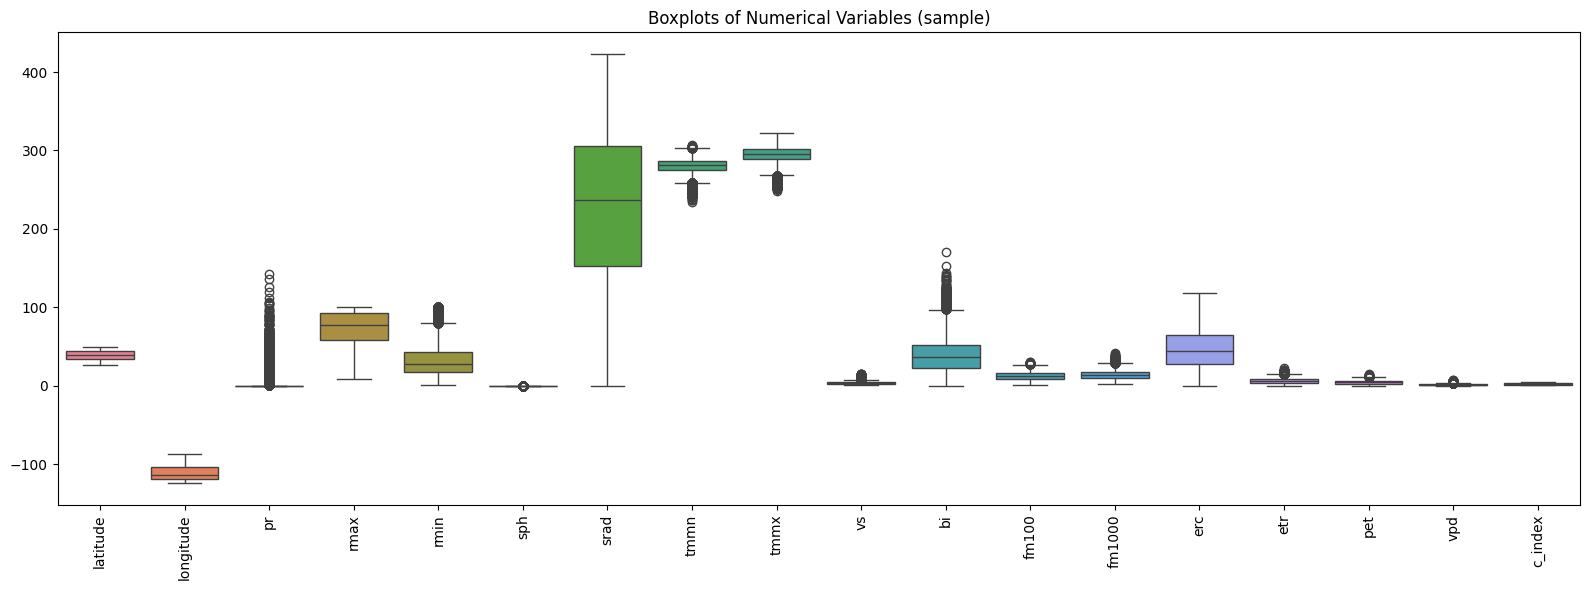

In [ ]:
plt.figure(figsize=(16, 6))
sns.boxplot(data=wildfire_sample[numeric_cols])
plt.xticks(rotation=90)
plt.title("Boxplots of Numerical Variables (sample)")
plt.tight_layout()
plt.show()

The boxplots reveal substantial variability in scale and distribution across the numerical variables in the wildfire dataset. Some variables, such as `latitude`, `longitude`, `sph`, `vs`, `pet`, `c_index` and `vpd`, show relatively narrow distributions with few extreme values, indicating stable and consistent measurements. In contrast, variables like `pr`, `srad`, `bi`, and `erc` show a strong right-skew, with many unusually large values that reflect occasional extreme weather events. Moreover, the variables like `tmmn`, `tmmx`, and `fm100`/`fm1000` show moderate spread with some detectable outliers but maintain more regular distribution shapes. Overall, the boxplots highlight that certain meteorological variables naturally exhibit heavy tails and extreme values, which is important to consider in modeling wildfire occurrence, as these extreme conditions may play a meaningful role in fire risk.

### 3.1.2 Analyzing Categorical Variables

Wildfire
No     7669125
Yes     456975
Name: count, dtype: int64

Proportions (%):
Wildfire
No     94.376454
Yes     5.623546
Name: proportion, dtype: float64


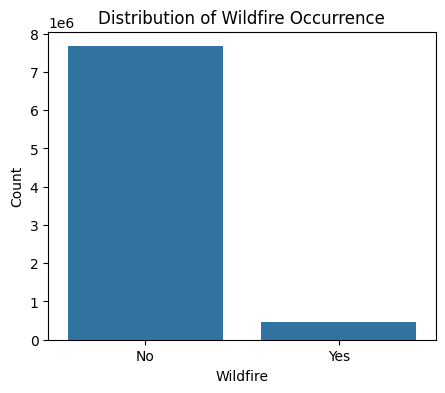

In [ ]:
# value counts
print(wildfire_clean['Wildfire'].value_counts())
print("\nProportions (%):")
print(wildfire_clean['Wildfire'].value_counts(normalize = True) * 100)

# countplot
plt.figure(figsize = (5,4))
sns.countplot(x = 'Wildfire', data = wildfire_clean)
plt.title("Distribution of Wildfire Occurrence")
plt.xlabel("Wildfire")
plt.ylabel("Count")
plt.show()

The categorical analysis of the `Wildfire` variable reveals a highly imbalanced distribution, with the vast majority of records indicating no wildfire occurrence. Specifically, around 94.7 percent of observations fall into the “No” category, while only about 5.3 percent correspond to wildfire events. This imbalance is clearly visible in the count plot, where the bar representing non-wildfire conditions dominates the chart. Such a skewed distribution suggests that wildfire events are relatively rare in the dataset and highlights the need for careful consideration in downstream modeling, since standard predictive approaches may favor the majority class unless techniques like resampling or class weighting are applied.

## 3.2 Bivariate Analysis

### 3.2.1: Each Numeric Variable vs Wildfire (Boxplots)

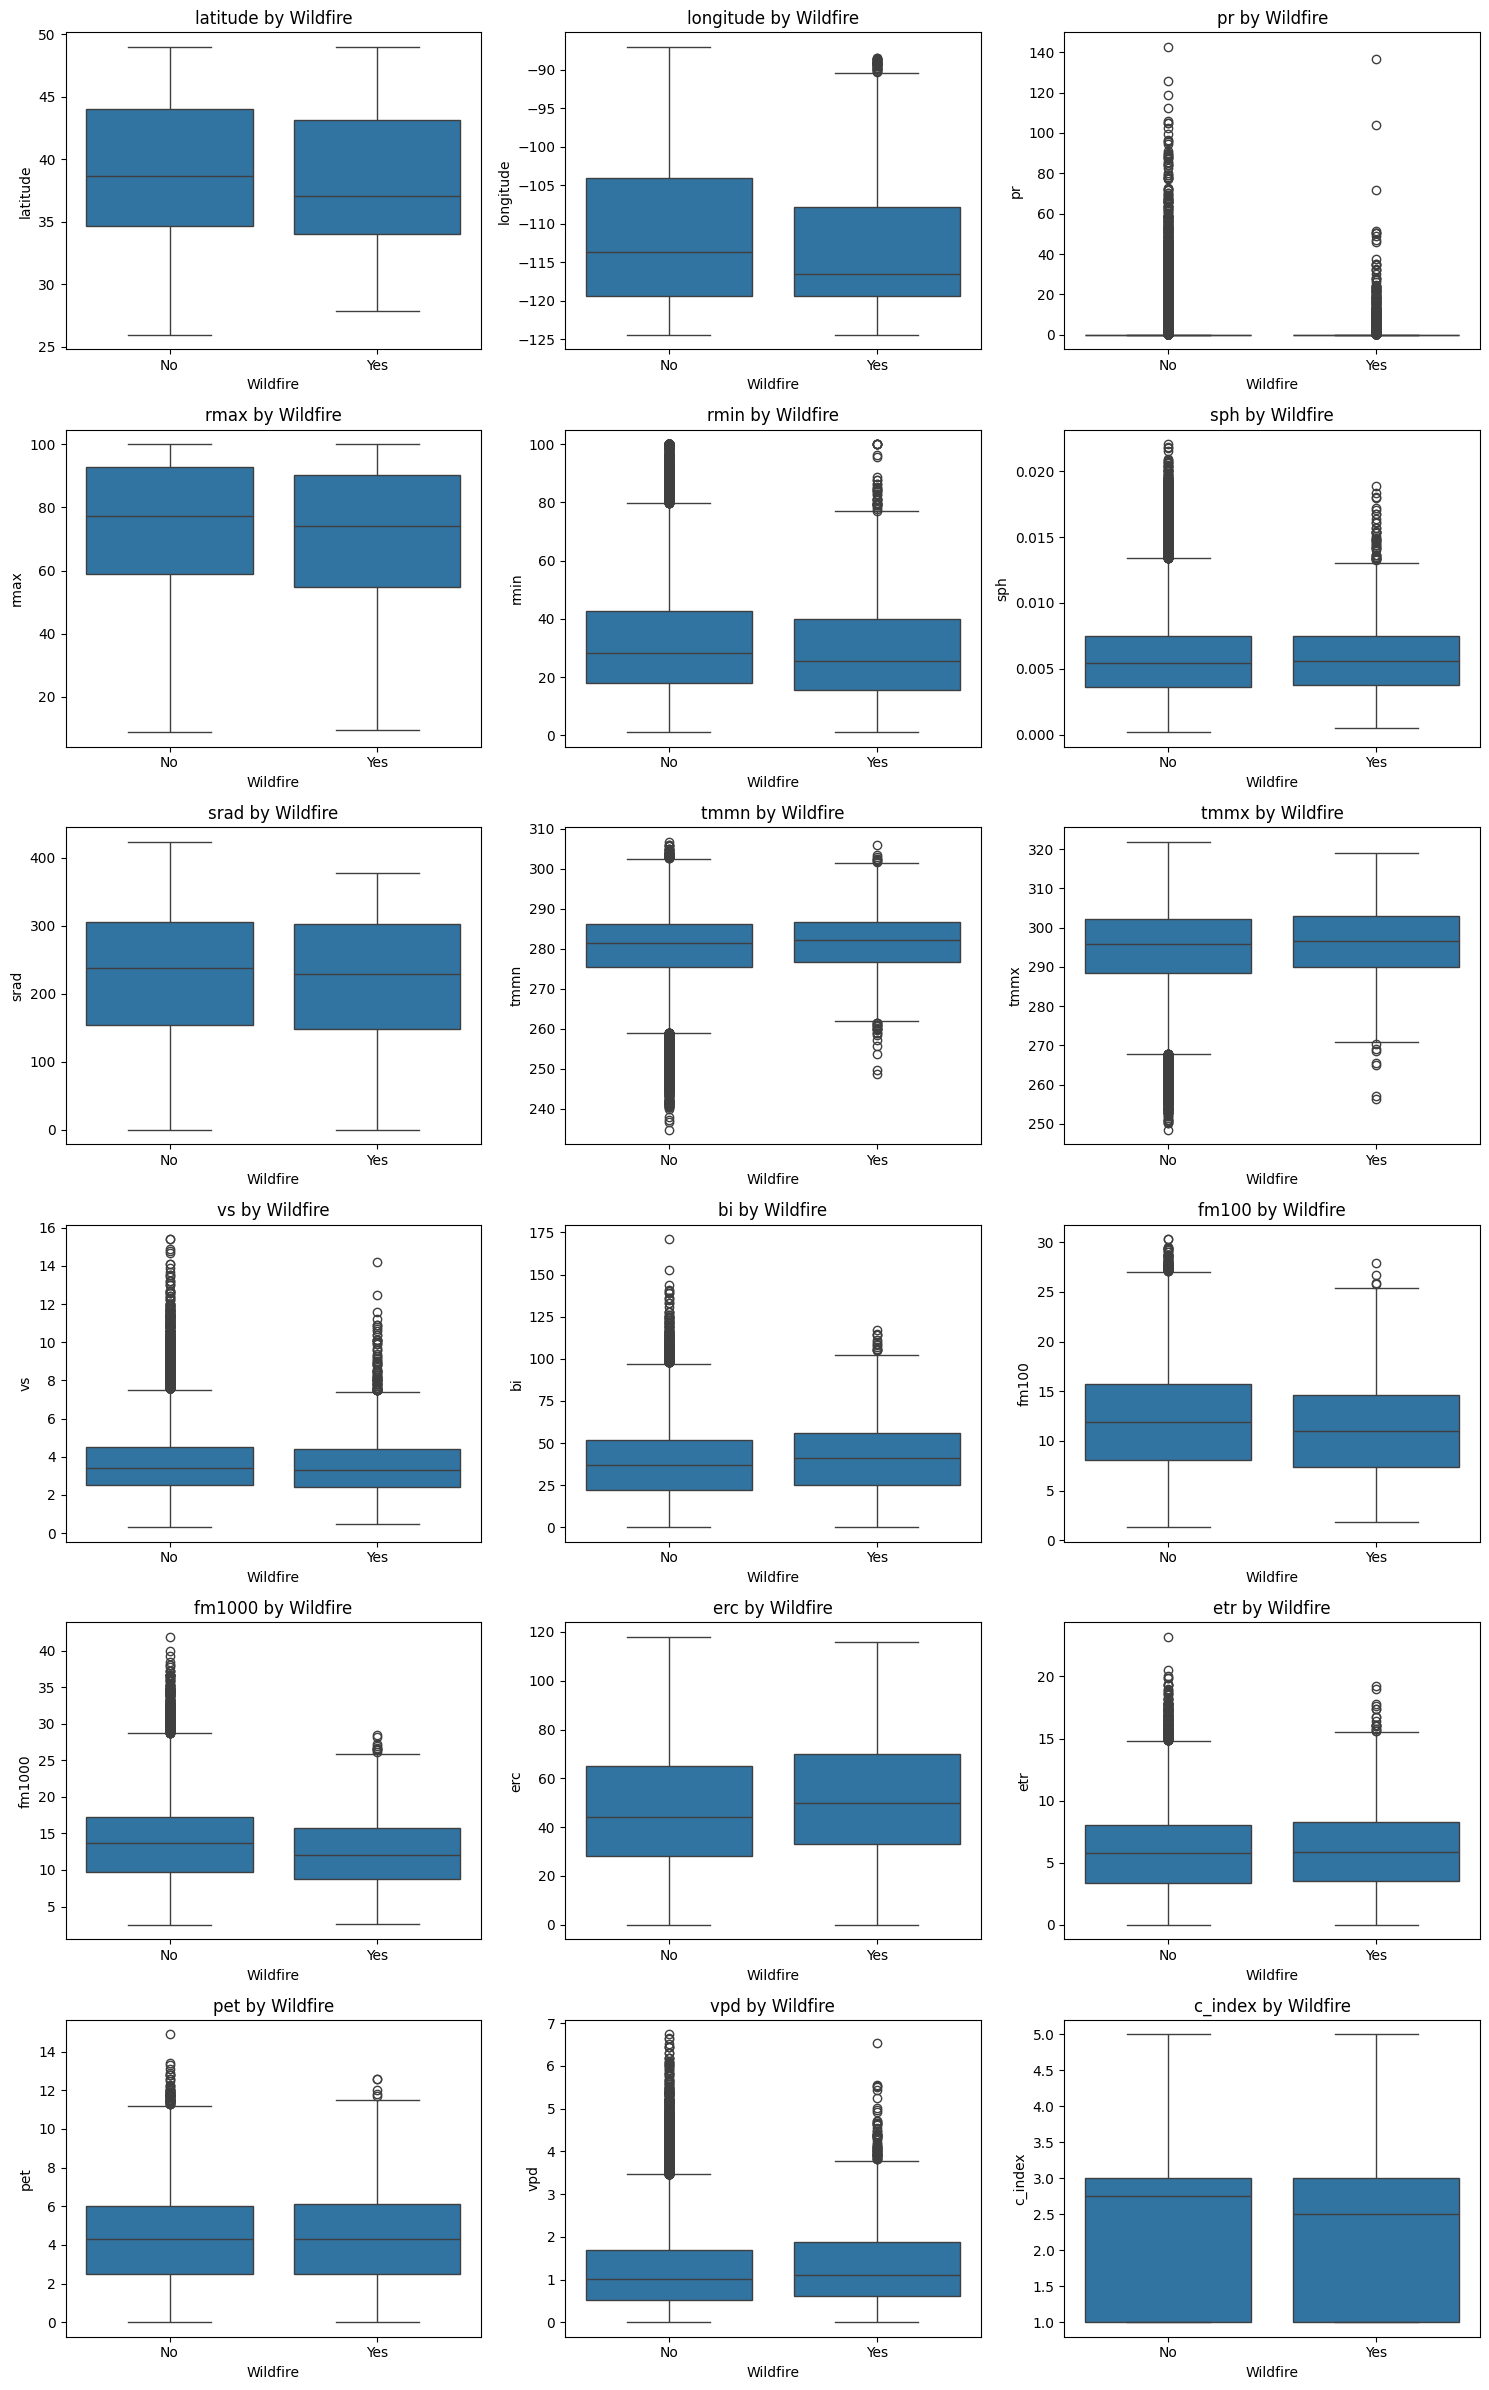

In [ ]:
n_cols = 3
n_vars = len(numeric_cols)
n_rows = math.ceil(n_vars / n_cols)

# create subplots grid
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()

# one boxplot per variable, grouped by Wildfire
for i, col in enumerate(numeric_cols):
    ax = axes[i]
    sns.boxplot(data=wildfire_sample, x='Wildfire', y=col, ax=ax)
    ax.set_title(f"{col} by Wildfire")
    ax.set_xlabel("Wildfire")
    ax.set_ylabel(col)

# hide any unused subplot cells
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

The boxplots comparing all numerical variables across wildfire and non wildfire conditions reveal clear differences in both environmental and spatial characteristics associated with wildfire occurrence. In terms of location, wildfire samples tend to cluster at slightly lower latitudes and more western longitudes, suggesting that fires are more common in regions that are warmer and drier geographically, such as large portions of the western United States. Environmental factors also show meaningful distinctions. Temperature variables generally have higher medians during wildfire events, while humidity related measures display lower medians, indicating hotter and drier atmospheric conditions when fires occur. This pattern is consistent with the vapor pressure deficit, which tends to be higher in wildfire cases and signals reduced moisture availability in the air. Radiation driven variables such as solar radiation, potential evapotranspiration, and evaporative loss are also elevated during wildfires, reflecting stronger heating and greater drying of vegetation. Fuel moisture indicators show lower medians when fires are present, reinforcing the idea that dry vegetation is a key component of wildfire risk. The composite flammability index, c_index, also differs between the two groups. Although the distributions overlap substantially, wildfire observations tend to show slightly lower or similar medians compared with non wildfire samples, suggesting that even areas with moderate or mixed flammability profiles can experience wildfires. This also indicates that while fuel composition plays a role, atmospheric and climatic conditions exert stronger influence on fire occurrence. Taken together, the spatial, environmental, and flammability based patterns form a consistent description of wildfire prone conditions, characterized by warmer temperatures, lower humidity, stronger radiation, reduced fuel moisture, and regions located toward the drier western part of the country.

### 3.2.2: Wildfire Probability by Month

<Axes: xlabel='month', ylabel='proportion'>

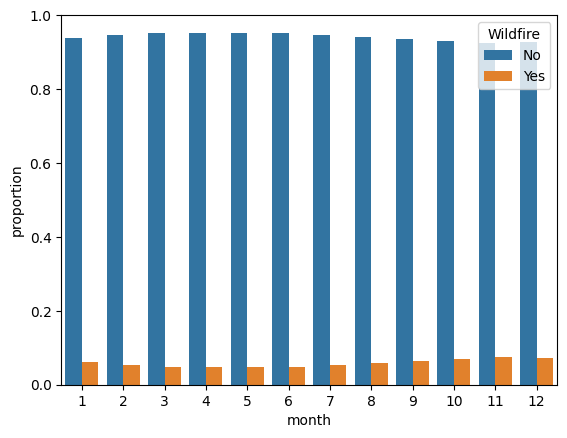

In [ ]:
month_fire = (
    wildfire_clean.groupby('month')['Wildfire']
        .value_counts(normalize=True)
        .rename("proportion")
        .reset_index()
)
sns.barplot(x='month', y='proportion', hue='Wildfire', data=month_fire)

By examining the monthly wildfire proportion plot, we can observe a subtle increasing pattern around the middle of the year, particularly between June and August, as well as a slight decline during the spring months around March and April. Although the overall variation is modest, these changes suggest the possibility of a mild seasonal pattern in wildfire occurrence. This provides motivation for further exploration, such as time-series analysis, to determine whether seasonal effects play a meaningful role in wildfire behavior.

### 3.2.3: Geographic Pattern

In [ ]:
m = folium.Map(location=[wildfire_clean['latitude'].mean(), wildfire_clean['longitude'].mean()], zoom_start=4)

HeatMap(
    data=wildfire_clean[wildfire_clean['Wildfire'] == "Yes"][['latitude', 'longitude']].sample(5000).values.tolist(),
    radius=6, blur=4
).add_to(m)

m.save("ignition_heatmap.html")
m


The geographic heatmap reveals a clear spatial pattern in wildfire occurrence across the United States. Wildfires are heavily concentrated in the western regions, especially along the West Coast, California, Oregon, Washington, Nevada, and parts of Arizona and New Mexico. There is also noticeable activity in some southern states, including Texas, Louisiana, Mississippi, Alabama and Florida. In contrast, central and northeastern regions show significantly lower wildfire density. This spatial distribution is fully consistent with the earlier histogram analysis of latitude and longitude, where wildfire cases were more common at lower latitudes and clustered within the western longitudes. Together, these findings confirm that wildfires in the dataset are not randomly distributed but instead follow well-known geographic and climatic patterns, with western and southern areas experiencing the highest concentrations.

## 3.3: Correlation Analysis

### 3.3.1: Correlation Matrix of Numerical Variables

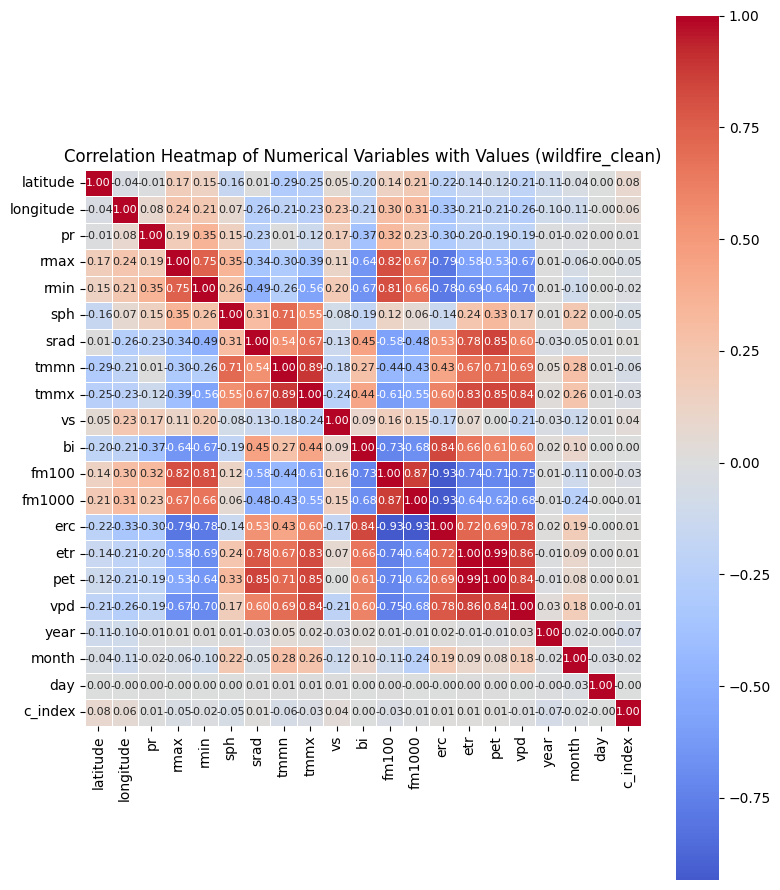

In [ ]:
# Select numerical variables
numeric_cols = wildfire_clean.select_dtypes(include='number').columns

# Compute correlation matrix
corr_matrix = wildfire_clean[numeric_cols].corr()

plt.figure(figsize=(8, 9))
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8}
)
plt.title("Correlation Heatmap of Numerical Variables with Values (wildfire_clean)")
plt.tight_layout()
plt.show()

To clearly identify which numerical variables exhibit collinearity, we created a separate dataframe to display the correlation values.

In [ ]:
# compute correlation matrix
numeric_df = wildfire_clean.select_dtypes(include=['float64', 'int64'])
corr = numeric_df.corr()

# find pairs with |correlation| > 0.8 (excluding self-correlation)
threshold = 0.8
high_corr_pairs = []

for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > threshold:
            high_corr_pairs.append(
                (corr.columns[i], corr.columns[j], corr.iloc[i, j])
            )

# convert to dataframe
high_corr_df = pd.DataFrame(high_corr_pairs,
                            columns=["Variable 1", "Variable 2", "Correlation"])

# sort by absolute correlation
high_corr_df = high_corr_df.reindex(high_corr_df["Correlation"].abs().sort_values(ascending=False).index)

high_corr_df.sort_index()

,Variable 1,Variable 2,Correlation
0,rmax,fm100,0.815588
1,rmin,fm100,0.812299
2,srad,pet,0.850768
3,tmmn,tmmx,0.889826
4,tmmx,etr,0.825351
5,tmmx,pet,0.848432
6,tmmx,vpd,0.840994
7,bi,erc,0.840620
8,fm100,fm1000,0.866353
9,fm100,erc,-0.926930


The correlation analysis reveals several strong relationships among the environmental variables in the dataset, indicating that many of these features capture closely related physical processes. Fuel moisture variables show some of the highest correlations, with fm100 and fm1000 strongly related and both strongly negatively correlated with the energy release component, reflecting the fact that dry fuels are associated with higher fire energy potential. Temperature variables also display a strong internal relationship, as seen in the high correlation between minimum and maximum daily temperatures, and both temperature measures are closely connected with evaporative and radiation driven variables such as potential evapotranspiration, vapor pressure deficit, and solar radiation. These patterns indicate that hotter days are typically accompanied by stronger drying forces and lower moisture availability. The strong correlation between solar radiation and potential evapotranspiration highlights the influence of incoming energy on surface drying. Overall, the pairs exceeding the correlation threshold indicate that several variables may contain overlapping information, particularly those related to temperature, atmospheric dryness, radiation, and fuel moisture. This suggests that later modeling efforts may benefit from careful feature selection to reduce redundancy and improve interpretability.

### 3.3.2: Correlation With Wildfire Occurrence

In [ ]:
wildfire_binary = wildfire_clean.copy()
wildfire_binary['Wildfire_num'] = wildfire_binary['Wildfire'].map({'No': 0, 'Yes': 1})

# Compute correlation of each numeric variable with wildfire occurrence
corr_with_fire = (
    wildfire_binary[numeric_cols.tolist() + ['Wildfire_num']]
        .corr()['Wildfire_num']
        .drop('Wildfire_num')
        .sort_values(ascending=False)
)

print(corr_with_fire)

erc          0.045894
bi           0.030503
tmmn         0.028252
vpd          0.027904
tmmx         0.025892
etr          0.013027
pet          0.007460
pr          -0.003875
sph         -0.005159
srad        -0.012737
vs          -0.013720
rmax        -0.025355
rmin        -0.026162
latitude    -0.032043
fm100       -0.032191
longitude   -0.038392
fm1000      -0.055892
Name: Wildfire_num, dtype: float64


The correlation between each numerical variable and wildfire occurrence shows that all relationships are extremely weak, with none of the coefficients approaching values that would indicate meaningful linear association. The variable with the highest correlation is year, but even this value is only around 0.15, which simply reflects that wildfire events have become slightly more common in more recent years rather than representing a genuine physical driver. Environmental variables such as humidity, temperature, vapor pressure deficit, precipitation, and radiation all have correlations close to zero, which indicates that no single variable linearly explains the presence of wildfire. Interestingly, the composite flammability index c_index also shows almost no linear relationship with wildfire occurrence in this aggregated form. These results suggest that wildfire occurrence is influenced by complex interactions between multiple environmental factors rather than by any single dominant variable. This also implies that nonlinear relationships or combined effects may play a more important role, and that more advanced modeling approaches may be necessary to capture the underlying patterns that lead to wildfire events.

### 3.3.3: Visualize Correlation With Wildfire

/tmp/ipython-input-3410117519.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


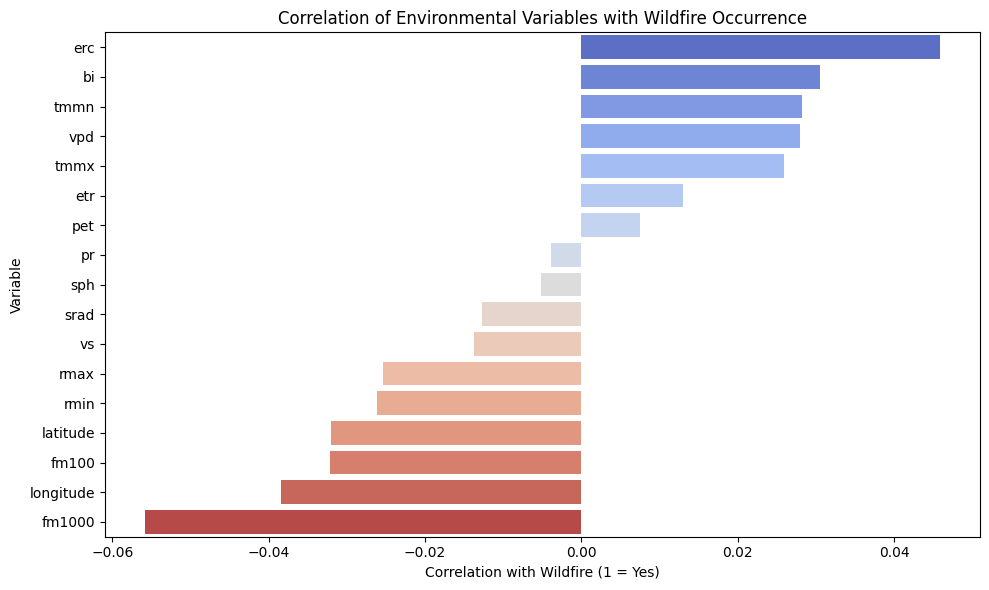

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x=corr_with_fire.values,
    y=corr_with_fire.index,
    palette='coolwarm'
)
plt.title("Correlation of Environmental Variables with Wildfire Occurrence")
plt.xlabel("Correlation with Wildfire (1 = Yes)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

The correlation plot reinforces the findings from the earlier exploratory analysis, showing that no individual environmental variable has a strong linear association with wildfire occurrence.

## 3.4: Time Trend Analysis

### 3.4.1: Overall monthly wildfire counts

/tmp/ipython-input-1971711690.py:9: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_counts = fires["Wildfire"].resample("M").count()


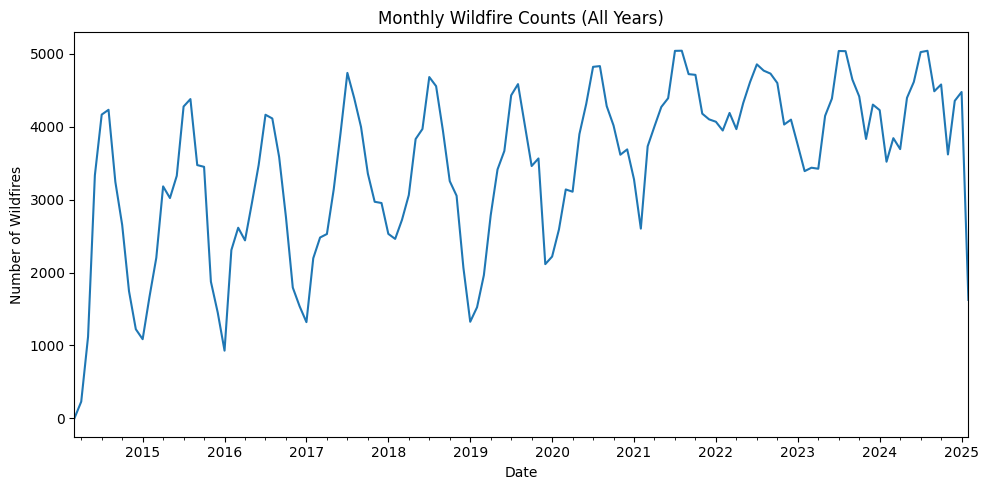

In [ ]:
plt.rcParams["figure.figsize"] = (10, 5)
wildfire_ts = wildfire_clean.copy()
# ensure datetime is in proper format
wildfire_ts["datetime"] = pd.to_datetime(wildfire_ts["datetime"])
# keep only wildfire events (Yes)
fires = wildfire_ts[wildfire_ts["Wildfire"] == "Yes"].set_index("datetime")

# Monthly counts of wildfire days
monthly_counts = fires["Wildfire"].resample("M").count()

fig, ax = plt.subplots()
monthly_counts.plot(ax=ax)
ax.set_title("Monthly Wildfire Counts (All Years)")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Wildfires")
plt.tight_layout()
plt.show()

The monthly wildfire count plot reveals a clear and recurring seasonal pattern in wildfire activity across all years, with sharp increases beginning in late spring and consistent peaks occurring between June and August before declining again toward the end of each year. This rhythmic cycle repeats almost identically from 2014 through 2024, indicating that wildfire occurrence is strongly influenced by seasonal climatic conditions. At the same time, the plot suggests a slight upward drift in peak wildfire counts over time, hinting at a gradual long-term increase in overall wildfire activity. Taken together, the series demonstrates both pronounced seasonality and a potential increasing trend, highlighting the importance of incorporating these components into any subsequent time-series analysis or forecasting models.

### 3.4.2: Wildfire Events per Year

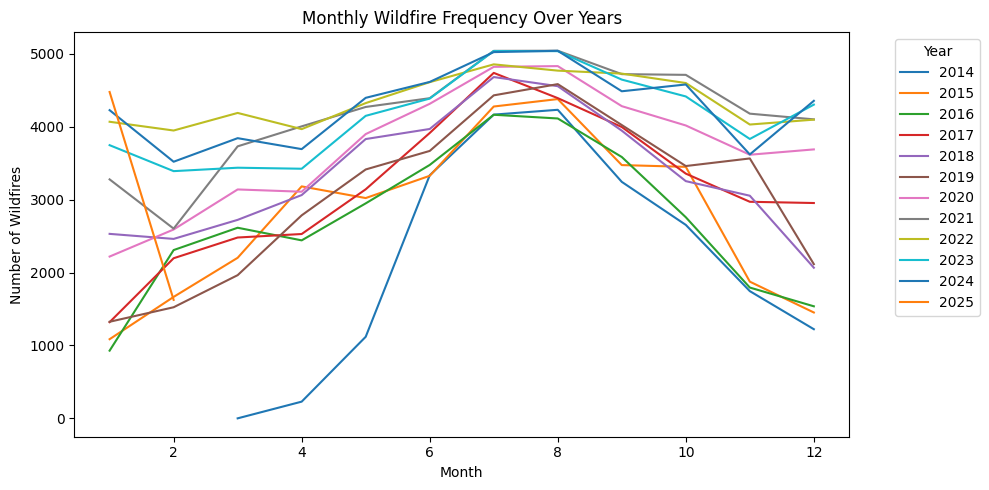

In [ ]:
# add year and month columns
fires["year"] = fires.index.year
fires["month"] = fires.index.month

# Counts for each (year, month)
monthly_by_year = (
    fires
    .groupby(["year", "month"])
    .size()
    .reset_index(name="count")
)

# pivot so months are x axis and years are separate lines
pivot_month_year = monthly_by_year.pivot(index="month", columns="year", values="count")

fig, ax = plt.subplots()
pivot_month_year.plot(ax=ax)
ax.set_title("Monthly Wildfire Frequency Over Years")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Wildfires")
plt.legend(title="Year", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


By examining the monthly wildfire frequency across years, we observe a consistent rise in wildfire counts during the mid-year period, particularly between June and August. This recurring peak suggests the presence of a strong seasonal pattern in wildfire occurrence. The stability of this trend across different years indicates that seasonal effects may play a meaningful role.

### 3.4.3 Rolling mean to smooth the trend

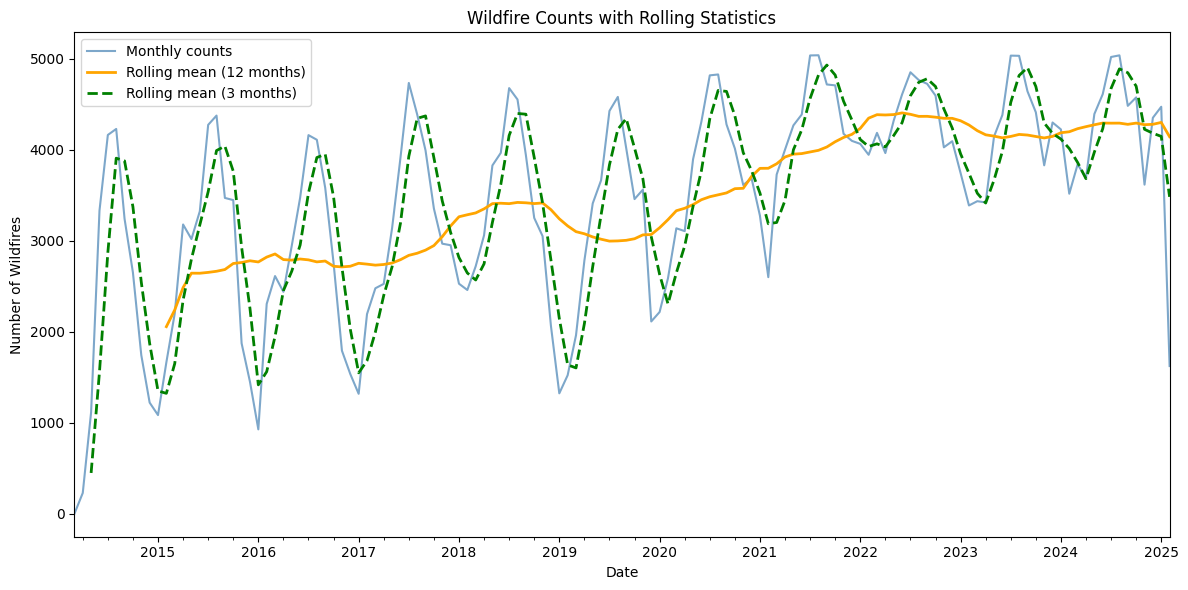

In [ ]:
# Compute rolling statistics
rolling_mean_12 = monthly_counts.rolling(window=12).mean()
rolling_std_12  = monthly_counts.rolling(window=12).std()

rolling_mean_3 = monthly_counts.rolling(window=3).mean()
rolling_std_3  = monthly_counts.rolling(window=3).std()

# Plotting
fig, ax = plt.subplots(figsize=(12,6))

monthly_counts.plot(ax=ax, label="Monthly counts", color="steelblue", alpha=0.7)
rolling_mean_12.plot(ax=ax, label="Rolling mean (12 months)", color="orange", linewidth=2)
rolling_mean_3.plot(ax=ax, label="Rolling mean (3 months)", color="green", linewidth=2, linestyle="--")

ax.set_title("Wildfire Counts with Rolling Statistics")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Wildfires")
ax.legend()

plt.tight_layout()
plt.show()



The plot of wildfire counts combined with 3-month and 12-month rolling averages reveals both short-term seasonal fluctuations and longer-term trends in wildfire activity. The 3-month rolling mean closely follows the sharp month-to-month peaks and troughs of the raw series, highlighting the strong seasonal pattern where wildfires consistently surge mid-year and decline during the cooler months. In contrast, the 12-month rolling mean smooths out seasonal noise and exposes a gradual upward trend over the decade, indicating that overall wildfire activity has increased over time regardless of within-year seasonality. Together, these rolling statistics show that wildfire counts are influenced by predictable seasonal cycles as well as a more persistent long-term rise, suggesting the presence of both short-term seasonality and longer-term structural changes in wildfire frequency.

### 3.4.4 Boxplot of daily wildfire counts by month

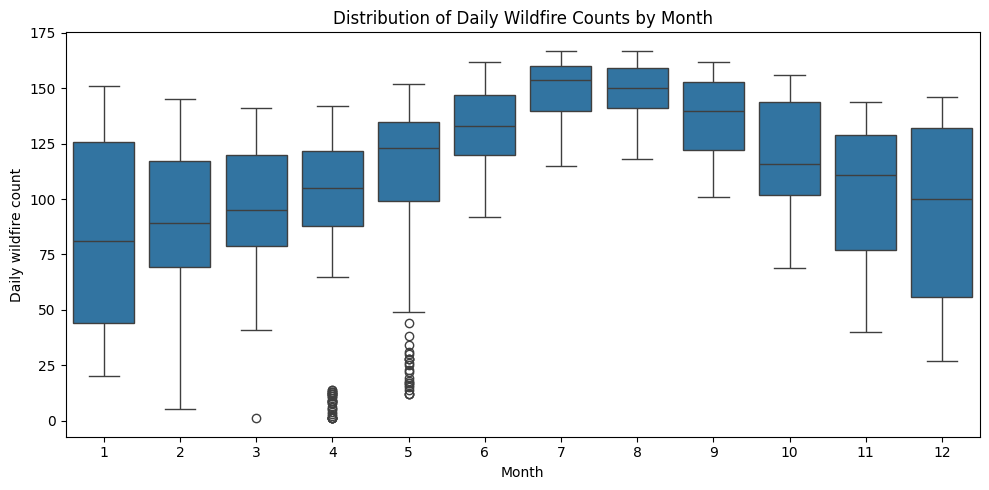

In [ ]:
# Daily counts of fires
daily_counts = fires["Wildfire"].resample("D").count()
daily_df = pd.DataFrame({
    "date": daily_counts.index,
    "count": daily_counts.values
})
daily_df["month"] = daily_df["date"].dt.month

fig, ax = plt.subplots()
sns.boxplot(data=daily_df, x="month", y="count", ax=ax)
ax.set_title("Distribution of Daily Wildfire Counts by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Daily wildfire count")
plt.tight_layout()
plt.show()


The boxplot shows that daily wildfire counts follow a clear yearly cycle, with the lowest activity in winter (January–March), steadily increasing through spring, and reaching the highest and most consistent levels in midsummer (June–August). During these peak months, the medians are substantially higher and the boxes are positioned near the top of the scale, indicating that high daily wildfire counts occur regularly rather than only during occasional extreme events. In the later months of the year (September–November), the distributions gradually decline again, reflecting the end of the fire season. This visualization therefore confirms a strong seasonal pattern, where wildfire activity rises, peaks, and falls in a predictable annual rhythm.

### 3.4.5 Heatmap of wildfire counts by year and month

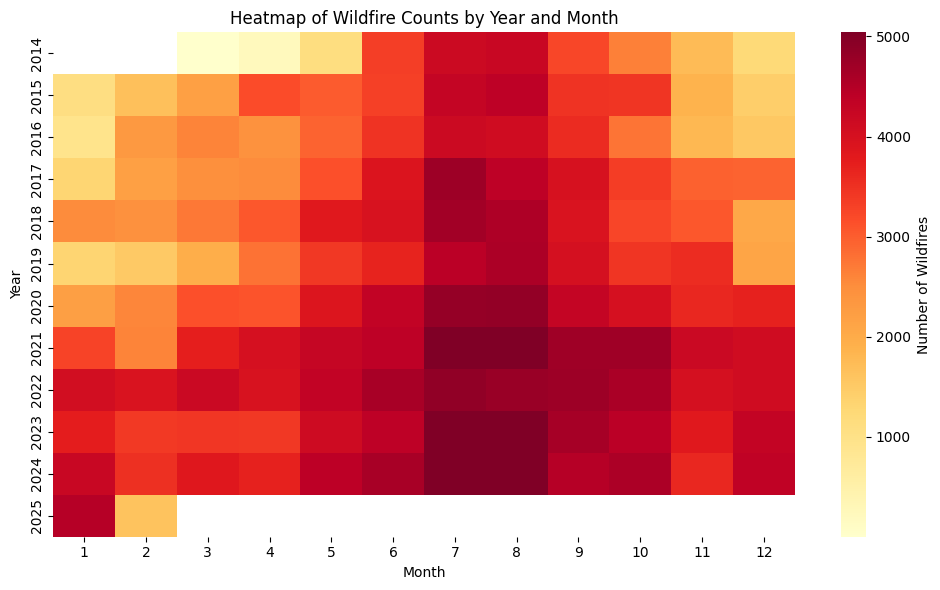

In [ ]:
# Reuse monthly_by_year from step 2
heatmap_data = monthly_by_year.pivot(index="year", columns="month", values="count")

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    ax=ax,
    cbar_kws={"label": "Number of Wildfires"}
)
ax.set_title("Heatmap of Wildfire Counts by Year and Month")
ax.set_xlabel("Month")
ax.set_ylabel("Year")
plt.tight_layout()
plt.show()


The heatmap reveals two strong patterns in wildfire activity. First, there is a consistent seasonal cycle across all years: wildfire counts remain relatively low in the winter months (January–March), rise through spring, and peak sharply during the summer period, especially from June to September, where the darkest shades dominate the heatmap. This confirms that summer consistently represents the height of the wildfire season. Second, there is a noticeable long-term upward trend across years. Earlier years (2014–2017) show lighter colors even in peak months, while more recent years (2021–2024) display darker and more intense colors throughout the year. This indicates that not only is the seasonal cycle stable, but the overall annual severity of wildfires has increased, with recent years experiencing both higher summer peaks and elevated counts even in traditionally low-fire months. Together, these observations highlight the combined impact of long-term environmental change and predictable seasonal patterns on wildfire behavior.

### 3.4.6 ADF Test Function

In [ ]:
def adf_test(series):
    result = adfuller(series, autolag='AIC')
    output = pd.Series(result[0:4],
                       index=['ADF Statistic', 'p-value', '# Lags Used', 'Number of Observations'])
    for key, value in result[4].items():
        output[f'Critical Value ({key})'] = value
    return output
adf_results = adf_test(monthly_counts)
print(adf_results)

ADF Statistic              -1.357076
p-value                     0.602673
# Lags Used                12.000000
Number of Observations    119.000000
Critical Value (1%)        -3.486535
Critical Value (5%)        -2.886151
Critical Value (10%)       -2.579896
dtype: float64


The Augmented Dickey–Fuller (ADF) test indicates that the monthly wildfire count series is non-stationary. The test statistic (≈ −1.36) is higher than all three critical values (1%, 5%, 10%), and the p-value (≈ 0.60) is far above the usual significance thresholds. This means we cannot reject the null hypothesis of a unit root. In practical terms, the wildfire count time series contains trend and seasonal structure, rather than fluctuating around a constant mean and variance. This result confirms what is visible in earlier plots: wildfire activity shows a long-term upward trend and repeating seasonal cycles, and therefore requires differencing or seasonal decomposition before applying classical time-series models such as SARIMA.

### 3.4.7 Seasonal Decomposition

/tmp/ipython-input-4022069701.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_counts = monthly_counts.asfreq('M')


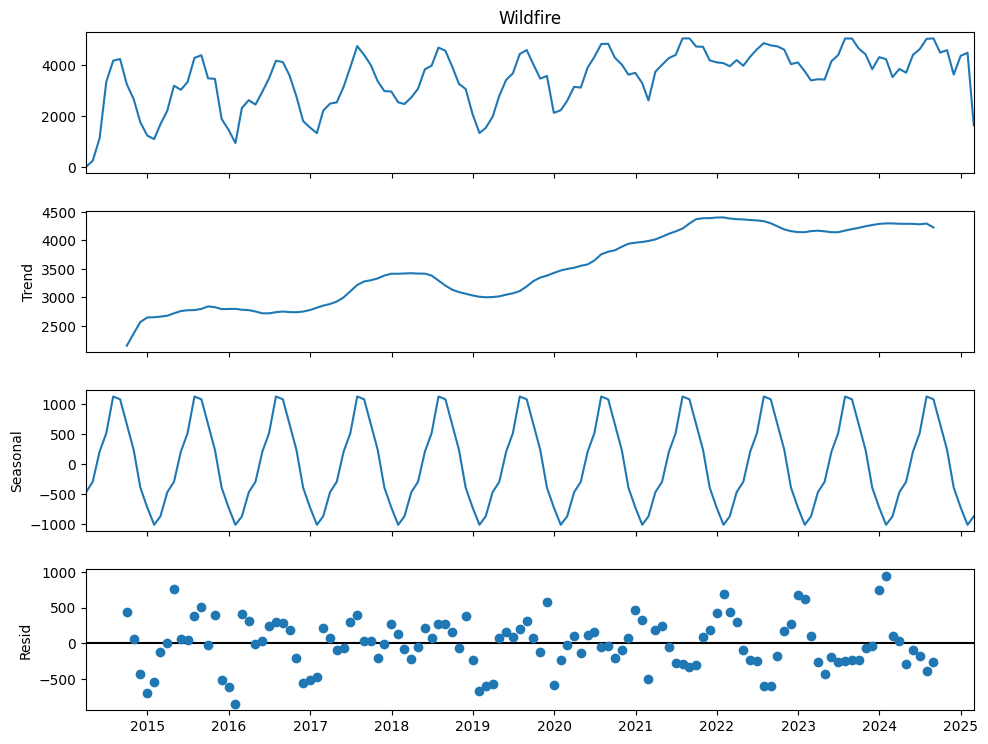

In [ ]:
# Make sure the series has a frequency set
monthly_counts = monthly_counts.asfreq('M')

# Perform seasonal decomposition (additive)
decomposition = seasonal_decompose(monthly_counts, model='additive', period=12)

# Plot
fig = decomposition.plot()
fig.set_size_inches(10, 8)
plt.show()

Key Insights from Seasonal Decomposition Plots:

* Trend Component: The trend line shows a clear upward trajectory from 2014 to around 2022, indicating that the underlying baseline level of wildfire activity has gradually increased over the years. This long-term rise aligns with broader climate-related factors such as increased drought intensity, higher temperatures, and prolonged dry seasons. Interestingly, the trend stabilizes or slightly declines near the end of the series, suggesting either a temporary reduction or incomplete final-year data.

* Seasonal Component: The seasonal plot reveals a consistent, repeating yearly pattern: wildfire activity reliably peaks during mid-year months (roughly June–August) and declines sharply in winter months. The amplitude of this seasonal cycle is strong, with pronounced highs and lows repeating almost identically each year. This confirms a robust seasonal structure in the data, driven by predictable environmental conditions such as summer heat, low humidity, and dry vegetation.

* Residual Component: The residuals capture the random fluctuations not explained by trend or seasonality. These points scatter around zero without a clear structure, which is desirable — it means the decomposition effectively removed systematic components. Occasional large positive or negative spikes indicate unusual months, likely associated with extreme weather events or reporting anomalies, but no persistent pattern remains.

### 3.4.8 Multiplicative Seasonal Decomposition

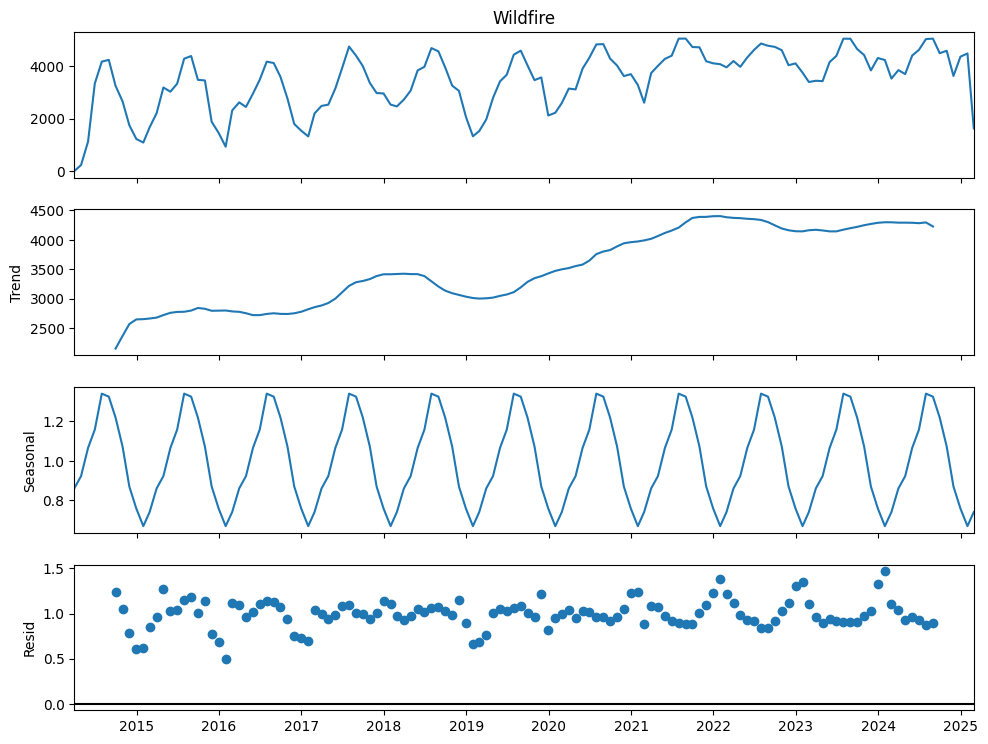

In [ ]:
decomposition_mul = seasonal_decompose(monthly_counts, model='multiplicative', period=12)
fig = decomposition_mul.plot()
fig.set_size_inches(10, 8)
plt.show()


The multiplicative seasonal decomposition confirms that the wildfire data exhibits three strong and interpretable components. The trend component shows a long-term upward increase in wildfire activity, suggesting growing baseline fire risk over the last decade. The seasonal component reveals a stable and repeating yearly pattern, with wildfires peaking during summer months and falling during winter, consistent with meteorological cycles. Because the seasonal component is multiplicative, seasonal variation increases proportionally with the underlying fire activity, meaning more active years also have larger seasonal swings. Finally, the residuals display no obvious structure, indicating that most systematic variation is successfully captured by the trend and seasonal components. This decomposition validates the presence of both trend and multiplicative seasonality—key evidence for using seasonal forecasting models such as SARIMA, Holt-Winters exponential smoothing, or even Prophet.

# Part 4 Modeling

## 4.1 Logistic Regression

For the logistic regression baseline and interaction screening, we **do not** apply random downsampling to the training data.  
Instead, we **employ** a class-weighted logistic regression with an **Elastic Net** penalty, which combines L1 and L2 regularization. Compared with pure L1, the additional L2 part stabilizes coefficient estimates when predictors are highly correlated, while compared with pure L2, the L1 part still induces sparsity and performs variable selection by shrinking many weak effects exactly to zero. This approach **mitigates** the impact of severe class imbalance without discarding any majority-class observations.  
As a result, the logistic model **can better capture** the effects and interactions relevant to wildfire events while **retaining** both full data efficiency and a parsimonious set of predictors, making it a suitable and interpretable baseline for subsequent feature engineering and model comparison.



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report, mean_squared_error, r2_score

# 1. Prepare Target (y) and Features (X)
target_col = 'Wildfire'
if wildfire_clean[target_col].dtype == 'object':
    y = wildfire_clean[target_col].apply(lambda x: 1 if x == 'Yes' else 0)
else:
    y = wildfire_clean[target_col]

X = wildfire_clean.drop(columns=[target_col], errors='ignore')

# 2. Select Numeric Features Only
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
X = X[numeric_features]

print(f"Features selected for modeling ({len(numeric_features)}):")
print(numeric_features)

# 3. Train-Test Split (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Standardization
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# Step 2: Base Model (Elastic Net) with Regression Metrics
print("\n" + "="*40)
print("Elastic Net Logistic Regression:")
print("="*40)

# Initialize Elastic Net Model
elastic_lr = LogisticRegression(
    penalty='elasticnet',
    # required for the Elastic Net penalty in logistic regression
    # and designed for large-scale, high-dimensional problems
    solver='saga',
    l1_ratio=0.5,
    C=0.1,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

print("Training Elastic Net model:")
elastic_lr.fit(X_train_scaled, y_train)

# We use the probability of the positive class (1)
y_train_prob = elastic_lr.predict_proba(X_train_scaled)[:, 1]
y_test_prob = elastic_lr.predict_proba(X_test_scaled)[:, 1]

# Binary Predictions for Classification Report
y_test_pred = elastic_lr.predict(X_test_scaled)

# Step 3: Evaluation (Classification Metrics)
print("\nClassification Metrics:")
print(f"Model AUC Score: {roc_auc_score(y_test, y_test_prob):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

# Coefficients
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': elastic_lr.coef_[0]
}).sort_values(by='Coefficient', key=abs, ascending=False)

print("\nTop 10 Most Important Features:")
print(coef_df.head(10))

Features selected for modeling (21):
['latitude', 'longitude', 'pr', 'rmax', 'rmin', 'sph', 'srad', 'tmmn', 'tmmx', 'vs', 'bi', 'fm100', 'fm1000', 'erc', 'etr', 'pet', 'vpd', 'year', 'month', 'day', 'c_index']

Elastic Net Logistic Regression:
Training Elastic Net model:

Classification Metrics:
Model AUC Score: 0.6950

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.65      0.78   1533825
           1       0.10      0.63      0.17     91395

    accuracy                           0.65   1625220
   macro avg       0.53      0.64      0.48   1625220
weighted avg       0.92      0.65      0.75   1625220


Top 10 Most Important Features:
   Feature  Coefficient
12  fm1000    -0.810390
17    year     0.590255
13     erc    -0.561241
14     etr    -0.335990
5      sph    -0.333460
15     pet     0.327711
8     tmmx     0.291081
7     tmmn     0.287079
6     srad    -0.248750
16     vpd    -0.192683


The baseline elastic net logistic regression achieves an AUC of **0.695** on the test set. Although the overall accuracy is around **0.65**, this number is not very informative given the strong class imbalance. More importantly, the model obtains a recall of about **0.63** for the wildfire class, while precision remains low at about **0.10**. This suggests that the baseline model tends to prioritise identifying as many wildfire days as possible, at the cost of a considerable number of false alarms. For a high-risk application such as wildfire early warning, this behaviour is acceptable as a starting point, but it highlights the need for further refinement of the decision threshold and model structure.

The top coefficients of the elastic net model suggest a physically reasonable ranking of predictors. The most influential variable is `fm1000`, which enters the model with a large negative coefficient, indicating that higher long-term fuel moisture is associated with a lower predicted probability of wildfire occurrence. The variable `year` has a positive coefficient, suggesting an increasing trend in predicted wildfire likelihood over the study period, conditional on the other environmental covariates. Several other moisture- and energy-related variables, such as `erc`, `etr`, `sph`, `pet`, and `vpd`, also appear among the most important predictors, together with temperature measures `tmmx` and `tmmn` and radiation `srad`. Overall, the baseline elastic net model indicates that fuel moisture, energy release, atmospheric demand, temperature, and their temporal evolution play central roles in explaining wildfire occurrence, providing a consistent foundation for the subsequent interaction-augmented models.



## 4.2 Logistic Regression With Interaction Terms

We enrich the feature space by automatically generating **pairwise interaction terms** between physically meaningful variables (fuel flammability `c_index` and key weather variables such as `vpd`, `tmmn`, `tmmx`, `sph`, `pr`, `erc`, etc.) using `PolynomialFeatures` with degree 2 and `interaction_only=True`. This allows the model to capture how combinations like fuel × weather jointly affect wildfire risk, rather than only modeling their separate linear effects. We then re-standardize the expanded feature set and fit an Elastic Net logistic regression, letting the mixed L1/L2 regularization automatically select the most informative interaction terms while controlling overfitting in this higher-dimensional, highly correlated feature space.


In [ ]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report, mean_squared_error, r2_score

print("\n" + "="*40)
print("Adding Interaction Terms (PolynomialFeatures):")
print("="*40)

# 1. Select Core Features for Interaction
interaction_cols = [
    'c_index', 'vpd', 'tmmn', 'tmmx', 'srad',
    'sph', 'pr', 'rmin', 'vs', 'bi', 'erc'
]

# Ensure these columns actually exist in the training data
valid_interaction_cols = [c for c in interaction_cols if c in X_train.columns]

print(f"Selected features for interaction generation ({len(valid_interaction_cols)}):")
print(valid_interaction_cols)

# 2. Generate Interaction Terms
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)

print("Generating interaction features:")
# Fit and transform only the selected columns
X_train_poly_raw = poly.fit_transform(X_train[valid_interaction_cols])
X_test_poly_raw = poly.transform(X_test[valid_interaction_cols])

# Get names for the new features (e.g., "c_index vpd")
poly_feature_names = poly.get_feature_names_out(valid_interaction_cols)

# 3. Convert to DataFrame and Merge with Remaining Features
# We create DataFrames for the new interaction terms
X_train_inter = pd.DataFrame(X_train_poly_raw, columns=poly_feature_names, index=X_train.index)
X_test_inter = pd.DataFrame(X_test_poly_raw, columns=poly_feature_names, index=X_test.index)

# Add back the columns that were NOT used for interactions (e.g., month, day)
remaining_cols = [c for c in X_train.columns if c not in valid_interaction_cols]
if remaining_cols:
    X_train_inter = pd.concat([X_train_inter, X_train[remaining_cols]], axis=1)
    X_test_inter = pd.concat([X_test_inter, X_test[remaining_cols]], axis=1)

print(f"Total feature count after adding interactions: {X_train_inter.shape[1]}")

# 4. Re-Standardization
# Interaction terms can have very different scales, so rescaling is mandatory.
print("Scaling new feature set:")
scaler_poly = StandardScaler()
X_train_inter_scaled = scaler_poly.fit_transform(X_train_inter)
X_test_inter_scaled = scaler_poly.transform(X_test_inter)

# 5. Train Elastic Net Model
print("Training Elastic Net with Interaction Terms:")
elastic_lr_poly = LogisticRegression(
    penalty='elasticnet',
    solver='saga',
    l1_ratio=0.5,
    C=0.1,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

elastic_lr_poly.fit(X_train_inter_scaled, y_train)

# 6. Prediction and Evaluation
y_test_pred_poly = elastic_lr_poly.predict(X_test_inter_scaled)
y_test_prob_poly = elastic_lr_poly.predict_proba(X_test_inter_scaled)[:, 1]
y_train_prob_poly = elastic_lr_poly.predict_proba(X_train_inter_scaled)[:, 1]

print("\nClassification Metrics:")
print(f"Model AUC: {roc_auc_score(y_test, y_test_prob_poly):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_poly))

# 7. Feature Importance Analysis
# Check which interaction terms "survived" the regularization
coef_df_poly = pd.DataFrame({
    'Feature': X_train_inter.columns,
    'Coefficient': elastic_lr_poly.coef_[0]
}).sort_values(by='Coefficient', key=abs, ascending=False)

print("\nTop 15 Most Important Features (Look for interactions like 'x y'):")
print(coef_df_poly.head(15))


Adding Interaction Terms (PolynomialFeatures):
Selected features for interaction generation (11):
['c_index', 'vpd', 'tmmn', 'tmmx', 'srad', 'sph', 'pr', 'rmin', 'vs', 'bi', 'erc']
Generating interaction features:
Total feature count after adding interactions: 76
Scaling new feature set:
Training Elastic Net with Interaction Terms:


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(



Classification Metrics:
Model AUC: 0.6979

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.65      0.78   1533825
           1       0.10      0.64      0.17     91395

    accuracy                           0.65   1625220
   macro avg       0.53      0.64      0.48   1625220
weighted avg       0.92      0.65      0.75   1625220


Top 15 Most Important Features (Look for interactions like 'x y'):
         Feature  Coefficient
37      tmmn erc    -1.147238
39      tmmx sph    -1.061076
12  c_index tmmn    -0.838799
5            sph     0.826692
70        fm1000    -0.778891
34     tmmn rmin     0.778869
21      vpd tmmn    -0.642599
10           erc     0.632443
41     tmmx rmin    -0.632105
2           tmmn     0.624254
9             bi     0.614334
73          year     0.585959
13  c_index tmmx     0.539403
3           tmmx     0.526140
72           pet    -0.451297


The interaction-augmented elastic-net logistic regression achieves an AUC of approximately **0.70** on the highly imbalanced test set. While the overall accuracy is around **0.65**, the model attains a recall of about **0.64** for the wildfire class, at the cost of a low precision (≈ **0.10**). This suggests that the model tends to prioritise catching as many wildfire events as possible, even if many non-fire days are falsely flagged as high risk.

Among the top 15 coefficients (ranked by absolute magnitude), most are interaction terms involving minimum/maximum temperature, fuel flammability (`c_index`), and dryness indicators such as `erc`, `vpd`, and relative humidity. This indicates that the model relies heavily on the **joint effect** of heat, fuel and dryness, rather than on any single variable alone. For example, interactions like `c_index * tmmn` and `c_index * tmmx` suggest that the impact of fuel flammability is modulated by temperature; similarly, terms such as `tmmn * rmin` and `vpd * tmmn` highlight the importance of “hot and dry” conditions.

Single variables such as `fm1000` and `erc` also appear with sizable coefficients. The negative coefficient for `fm1000` is consistent with physical intuition: higher dead fuel moisture is associated with a lower predicted wildfire risk, whereas higher `erc` and Burning Index (`bi`) increase the predicted probability of fire. The presence of `year` among the important predictors indicates a **long-term upward trend in predicted wildfire likelihood**, even after controlling for concurrent weather and fuel conditions.



## 4.3 Downsampling

Because wildfire occurrence is highly imbalanced (only about **5–6%** of the records correspond to `Wildfire = 1`), training directly on the raw data would cause the loss function to be dominated by the majority class (`Wildfire = 0`). In that case, the model can achieve high overall accuracy by simply predicting *“no fire”* almost all the time, while failing to detect a large fraction of actual wildfire events.

To mitigate this issue, we apply **random undersampling** to the training set only. After performing a stratified 80/20 train–test split, we use `RandomUnderSampler` to reduce the number of majority-class samples in the training data and construct a roughly **1:1 balanced** training set. This forces the model to pay more equal attention to fire and non-fire cases during learning and improves its ability to distinguish the minority class. The test set is kept in its original imbalanced form, so that evaluation metrics (precision, recall, AUC) still reflect the model’s performance under realistic class proportions.


In [ ]:
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler

print("Raw Features + Interaction Terms (No PCA):")

# 1. Define Feature Groups
# Group A: Raw Weather Variables (15 features)
weather_cols = [
    'pr', 'rmax', 'rmin', 'sph', 'srad', 'tmmn', 'tmmx',
    'vs', 'bi', 'fm100', 'fm1000', 'erc', 'etr', 'pet', 'vpd'
]

# Group B: Structural Variables (Location, Fuel, Time)
structural_cols = ['latitude', 'longitude', 'c_index', 'month', 'day']

# 2. Manually Create "Golden Interaction Terms"
# These are the top interactions discovered during the Logistic Regression phase
wildfire_clean['inter_tmmn_erc']   = wildfire_clean['tmmn'] * wildfire_clean['erc']
wildfire_clean['inter_tmmx_sph']   = wildfire_clean['tmmx'] * wildfire_clean['sph']
wildfire_clean['inter_c_tmmn']     = wildfire_clean['c_index'] * wildfire_clean['tmmn']
wildfire_clean['inter_tmmx_rmin']  = wildfire_clean['tmmx'] * wildfire_clean['rmin']
wildfire_clean['inter_vpd_tmmn']   = wildfire_clean['vpd'] * wildfire_clean['tmmn']

interaction_cols = [
    'inter_tmmn_erc', 'inter_tmmx_sph', 'inter_c_tmmn',
    'inter_tmmx_rmin', 'inter_vpd_tmmn'
]

# 3. Assemble Final Feature Matrix X
# Concatenate all groups. No PCA is used.
feature_cols = weather_cols + structural_cols + interaction_cols
X_final = wildfire_clean[feature_cols].copy()

# Prepare Target y
y_final = wildfire_clean['Wildfire'].apply(lambda x: 1 if x == 'Yes' else 0)

print(f"Final Feature Count: {len(feature_cols)}")
print("Feature List:", feature_cols)

# Split & Downsample
print("Splitting and Downsampling:")

# 1. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_final,
    test_size=0.2,
    random_state=42,
    stratify=y_final
)

# 2. Downsampling (Training Set ONLY)
# We balance the training set to 1:1 using RandomUnderSampler
rus = RandomUnderSampler(random_state=42)
X_train_res, y_train_res = rus.fit_resample(X_train, y_train)

print(f"Original Train Shape:   {X_train.shape}")
print(f"Resampled Train Shape:  {X_train_res.shape} (Ready for Modeling)")
print(f"Test Set Shape:         {X_test.shape} (Imbalanced - For Evaluation)")

>>> Preparing Data: Raw Features + Interaction Terms (No PCA)...
Final Feature Count: 25
Feature List: ['pr', 'rmax', 'rmin', 'sph', 'srad', 'tmmn', 'tmmx', 'vs', 'bi', 'fm100', 'fm1000', 'erc', 'etr', 'pet', 'vpd', 'latitude', 'longitude', 'c_index', 'month', 'day', 'inter_tmmn_erc', 'inter_tmmx_sph', 'inter_c_tmmn', 'inter_tmmx_rmin', 'inter_vpd_tmmn']

>>> Splitting and Downsampling...
Original Train Shape:   (6500880, 25)
Resampled Train Shape:  (731160, 25) (Ready for Modeling)
Test Set Shape:         (1625220, 25) (Imbalanced - For Evaluation)


### 4.4 Decision Tree

We include a **Decision Tree classifier** as a simple non-linear baseline model alongside logistic regression. Unlike the linear decision boundary of logistic regression, a tree can capture **non-linear relationships and higher-order interactions** through hierarchical splits on key variables (e.g., meteorological factors and fuel indices). We control its complexity using `max_depth` and `min_samples_leaf`, and set `class_weight='balanced'` to partially correct for class imbalance in the training data. Although more flexible than a linear model, a single tree remains relatively easy to interpret compared with ensemble methods, which makes it a useful reference point when we later evaluate more complex models such as Random Forests and XGBoost.



In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, classification_report, \
    recall_score, precision_score, f1_score

print("\n" + "="*40)
print("Decision Tree (Baseline Non-Linear Model):")
print("="*40)

# Initialize Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=20,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)

# Train
dt_model.fit(X_train_res, y_train_res)

# Predictions
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Decision Tree Classification Metrics:")
print(f"AUC Score: {roc_auc_score(y_test, y_prob_dt):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_dt):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dt):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_dt):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))



Decision Tree (Baseline Non-Linear Model):
Decision Tree Classification Metrics:
AUC Score: 0.7434
Recall:    0.7147
Precision: 0.1097
F1 Score:  0.1901

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.65      0.78   1533825
           1       0.11      0.71      0.19     91395

    accuracy                           0.66   1625220
   macro avg       0.54      0.68      0.49   1625220
weighted avg       0.93      0.66      0.75   1625220



The Decision Tree baseline achieves an AUC of **0.743** on the test set, improving over the elastic net logistic regression (AUC ≈ 0.695). Overall accuracy remains around **0.66**, which again is not very informative under strong class imbalance. For the wildfire class, the tree attains a recall of about **0.71** and a precision of roughly **0.11**, leading to an F1 score of **0.19**. Compared with the linear baseline, this model recovers a larger fraction of wildfire days (higher recall) while keeping precision at a similar level, suggesting that the non-linear splits of the tree can better separate high-risk conditions from background days. However, the precision is still low, implying many false alarms, so subsequent ensemble models (Random Forest and XGBoost) are needed to further improve the trade-off between detection rate and false positives.


### 4.5 XGboost

Building on the linear elastic-net and single-tree baselines, we next use **XGBoost** as a stronger non-linear model. As a boosted ensemble of decision trees, XGBoost can capture complex interactions between fuel and meteorological variables, is well suited to large tabular data, and includes built-in regularisation and feature importance.

Here we train an `XGBClassifier` on the **downsampled training set** (`X_train_res`, `y_train_res`) and evaluate it on the original imbalanced test set. We use 300 trees with a small learning rate (`0.05`), depth `10`, and row/column subsampling (`subsample=0.8`, `colsample_bytree=0.8`) to control overfitting, and `tree_method="hist"` with `device="cuda"` for efficient training. We then report AUC, recall, precision and F1 on `X_test`, and plot the top 15 features by gain-based importance to identify the main drivers of wildfire occurrence.




Training XGBoost (Raw + Interactions)


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [22:47:06] WARNING: /workspace/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [22:47:06] WARNING: /workspace/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


--- XGBoost Classification Metrics ---
AUC Score: 0.7615
Recall:    0.7128
Precision: 0.1146
F1 Score:  0.1975

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.67      0.80   1533825
           1       0.11      0.71      0.20     91395

    accuracy                           0.67   1625220
   macro avg       0.54      0.69      0.50   1625220
weighted avg       0.93      0.67      0.76   1625220



<Figure size 1000x600 with 0 Axes>

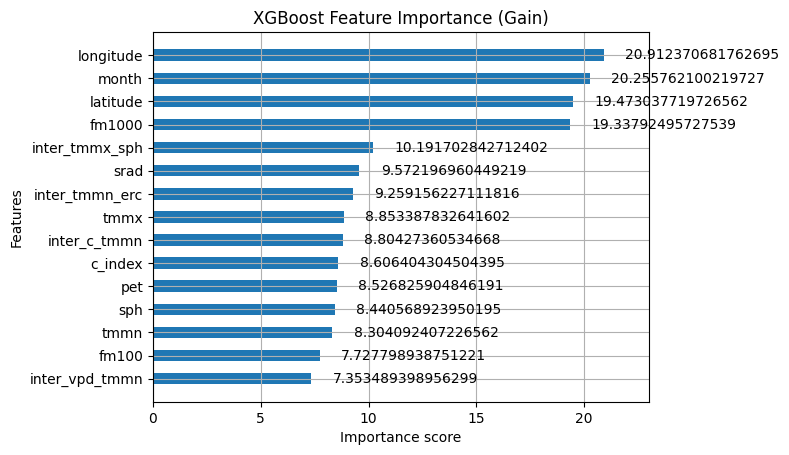

In [ ]:
from xgboost import XGBClassifier, plot_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, mean_squared_error, r2_score


print("\n" + "="*40)
print("Training XGBoost (Raw + Interactions):")
print("="*40)

# 1. Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=10,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=1.0,
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    device="cuda"
)

# 2. Train
xgb_model.fit(X_train_res, y_train_res)

# 3. Predict
# Test Set
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# 4. Evaluation
print("--- XGBoost Classification Metrics ---")
print(f"AUC Score: {roc_auc_score(y_test, y_prob_xgb):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_xgb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_xgb):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_xgb):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

# 5. Feature Importance
plt.figure(figsize=(10, 6))
plot_importance(xgb_model, max_num_features=15, importance_type='gain', height=0.5)
plt.title("XGBoost Feature Importance (Gain)")
plt.show()

Under this training scheme, the XGBoost model achieves an AUC of **0.7615**, which is noticeably higher than the elastic-net baseline. On the minority wildfire class, the model attains a **recall of 0.7128**, meaning that more than 70% of wildfire days are correctly detected, while the **precision is 0.1146**, indicating a substantial number of false alarms. The F1 score for the wildfire class is therefore modest (≈ **0.198**), which is expected in such a highly imbalanced setting and is consistent with our goal of favouring **high recall over precision** in an early-warning context. For the non-fire class, precision is very high (≈ **0.98**) and recall around **0.67**, leading to an overall accuracy of about **0.67** on the imbalanced test set.

The gain-based feature importance plot shows that **spatial and seasonal structure** plays a dominant role, with **`longitude`**, **`month`** and **`latitude`** ranked as the three most influential predictors. Among the environmental variables, **`fm1000`** and **`fm100`** (fuel moisture at different time scales) appear with high importance, supporting the view that fuel dryness is a key driver of wildfire occurrence. Several interaction terms are also ranked highly, such as **`inter_tmmx_sph`** (maximum temperature × specific humidity), **`inter_tmmn_erc`** (minimum temperature × ERC), **`inter_c_tmmn`** (C_index × minimum temperature) and **`inter_vpd_tmmn`** (VPD × minimum temperature). Their prominence indicates that the joint effect of temperature, atmospheric/moisture conditions and fuel flammability indices provides additional predictive power beyond the individual variables alone. Overall, the XGBoost model trained on the downsampled data captures meaningful spatial, seasonal and physical relationships and substantially improves discrimination of wildfire events compared with the linear baseline.



### 4.6 Random Forest

We additionally fit a **Random Forest** model as an ensemble-based counterpart to the single Decision Tree and boosted XGBoost models. A random forest aggregates predictions from many decorrelated trees built on bootstrapped samples and random feature subsets, which typically **reduces variance and overfitting** compared with a single tree while remaining relatively robust and easy to tune. Here we train a `RandomForestClassifier` on the **downsampled** training set (`X_train_res`, `y_train_res`) with 150 trees, controlled depth (`max_depth=20`) and a minimum leaf size of 4, and set `class_weight='balanced'` so that each tree pays comparable attention to fire and non-fire samples. We then predict on the original imbalanced test set to compute AUC, recall, precision and F1. Finally, we extract `feature_importances_`, sort the features, and plot the top 15 in a horizontal bar chart, which helps us see which raw variables and interaction terms the random forest relies on most when distinguishing wildfire from non-wildfire days.



Training Random Forest (Raw + Interactions):
Random Forest Classification Metrics:
AUC Score: 0.7581
Recall:    0.7051
Precision: 0.1144
F1 Score:  0.1968

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.67      0.80   1533825
           1       0.11      0.71      0.20     91395

    accuracy                           0.68   1625220
   macro avg       0.54      0.69      0.50   1625220
weighted avg       0.93      0.68      0.76   1625220



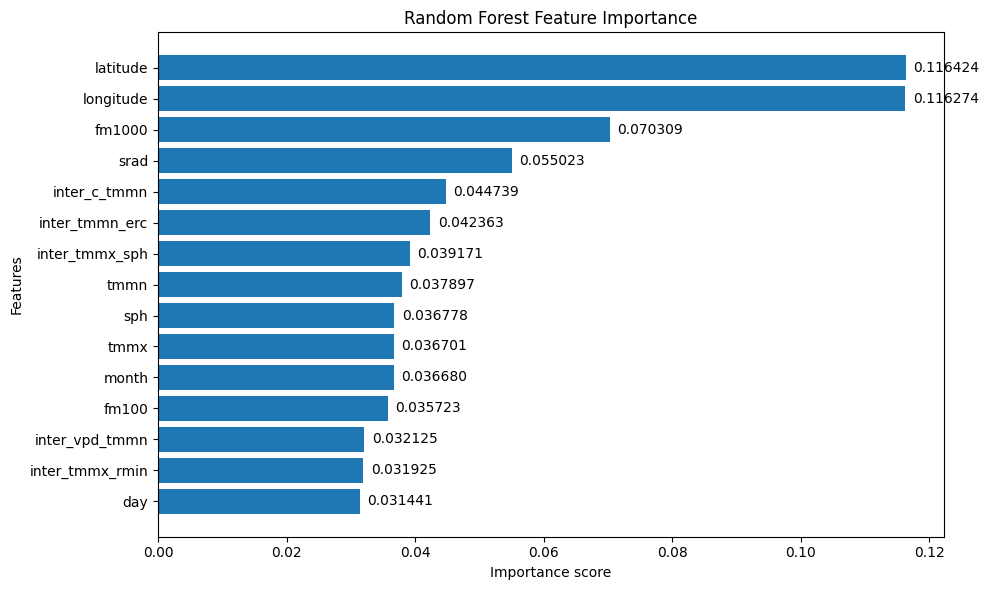

In [ ]:
from sklearn.ensemble import RandomForestClassifier

print("\n" + "="*40)
print("Training Random Forest (Raw + Interactions):")
print("="*40)

# 1. Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=20,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

# 2. Train
rf_model.fit(X_train_res, y_train_res)

# 3. Predict
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
# Train Probabilities
y_train_prob_rf = rf_model.predict_proba(X_train_res)[:, 1]

# 4. Evaluation
print("Random Forest Classification Metrics:")
print(f"AUC Score: {roc_auc_score(y_test, y_prob_rf):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_rf):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# 1. Get feature names and importance scores
# Assume X_train_res is a pandas DataFrame
feature_names = X_train_res.columns
importances = rf_model.feature_importances_

# 2. Sort features by importance (descending) and keep top N
indices = np.argsort(importances)[::-1]
top_n = 15
top_indices = indices[:top_n]

top_importances = importances[top_indices]
top_features = feature_names[top_indices]

# 3. Plot horizontal bar chart
plt.figure(figsize=(10, 6))
y_pos = np.arange(top_n)

# Reverse order so the most important feature is at the top
plt.barh(y_pos, top_importances[::-1])
plt.yticks(y_pos, top_features[::-1])
plt.xlabel("Importance score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

# 4. Add importance values to the right of each bar
x_max = top_importances.max()
for i, v in enumerate(top_importances[::-1]):
    plt.text(v + 0.01 * x_max,
             i,
             f"{v:.6f}",
             va='center')

plt.tight_layout()
plt.show()

 Under the setup above, the random forest achieves an AUC of **0.7581**, a wildfire recall of **0.7051**, a precision of **0.1144**, and an F1 score of **0.1968** for the minority class. These values are very close to those of the XGBoost model (AUC ≈ **0.7615**, recall ≈ **0.7128**, precision ≈ **0.1146**, F1 ≈ **0.20**). In other words, both tree-based methods deliver almost identical performance: they successfully recover around 70% of wildfire days but still produce many false positives, reflecting the deliberate choice to prioritise **high recall** in this early-warning setting.

The feature importance profile of the random forest is also broadly consistent with that of XGBoost. Spatial and seasonal structure remains dominant, with **`latitude`** and **`longitude`** ranked as the two most important predictors, followed by **`fm1000`** and **`srad`**. Several interaction terms involving fuel flammability and temperature, such as **`inter_c_tmmn`**, **`inter_tmmn_erc`**, **`inter_tmmx_sph`**, and **`inter_vpd_tmmn`**, appear prominently, together with core weather variables like **`tmmn`**, **`tmmx`**, **`sph`**, **`month`**, and **`fm100`**. Compared with XGBoost, the random forest places slightly more emphasis on latitude and less on some of the interaction terms, but the overall message is the same: **location, fuel moisture, solar radiation, and temperature–fuel/moisture interactions jointly drive wildfire occurrence**. This close agreement between the random forest and XGBoost results strengthens the robustness of the conclusions drawn from the tree-based models.


### 4.6 Neural Network

We additionally experiment with a **feed-forward neural network** because the dataset is large and feature-rich (raw weather, structural variables and interaction terms). In this setting, an NN provides a high-capacity, flexible model that can learn complex non-linear relationships between fuel and meteorological variables, offering a different inductive bias from tree-based methods and allowing us to test whether a more expressive model can extract extra predictive signal beyond logistic regression, Random Forest and XGBoost.

Concretely, we first standardise all features with `StandardScaler`, fitting on the **downsampled training set** (`X_train_res`) and applying the transform to both train and test. The network is a three-hidden-layer MLP with **128, 64 and 32 ReLU units**, each equipped with **weak elastic-net style `l1_l2` regularisation** (`l1=1e-5`, `l2=1e-4`), followed by **Batch Normalization** and **Dropout(0.3)** to control overfitting. We use an Adam optimiser with learning rate `5e-4`, `binary_crossentropy` loss, and monitor validation AUC with **EarlyStopping** (patience 15, restoring best weights) and **ReduceLROnPlateau** (halving the learning rate when AUC plateaus). Training runs for up to 100 epochs with batch size 2048, and we then evaluate on the original imbalanced test set using AUC, recall, precision and F1.




In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l1_l2
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, f1_score, classification_report, mean_squared_error, r2_score, recall_score, precision_score

print("\n" + "="*40)
print("Training Neural Network (Wide + Elastic Net, adjusted):")
print("="*40)

# 0. Clean Session
tf.keras.backend.clear_session()

# 1. Scaling
print("Scaling Data:")
scaler_nn = StandardScaler()
X_train_scaled = scaler_nn.fit_transform(X_train_res)
X_test_scaled  = scaler_nn.transform(X_test)

print(f"Training Input Shape: {X_train_scaled.shape}")
print(f"Testing Input Shape:  {X_test_scaled.shape}")

# 2. Build Model
model = Sequential([
    # Layer 1: 128 units, weaker L1/L2, lower dropout
    Dense(
        128,
        activation='relu',
        input_shape=(X_train_scaled.shape[1],),
        kernel_regularizer=l1_l2(l1=1e-5, l2=1e-4)
    ),
    BatchNormalization(),
    Dropout(0.3),

    # Layer 2: 64 units
    Dense(
        64,
        activation='relu',
        kernel_regularizer=l1_l2(l1=1e-5, l2=1e-4)
    ),
    BatchNormalization(),
    Dropout(0.3),

    # Layer 3: 32 units
    Dense(
        32,
        activation='relu',
        kernel_regularizer=l1_l2(l1=1e-5, l2=1e-4)
    ),
    BatchNormalization(),
    Dropout(0.3),

    # Output
    Dense(1, activation='sigmoid')
])

# 3. Compile
optimizer = Adam(learning_rate=5e-4)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=[tf.keras.metrics.AUC(name='auc')]
)

# 4. Callbacks
early_stopping = EarlyStopping(
    monitor='val_auc',
    patience=15,
    restore_best_weights=True,
    mode='max',
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_auc',
    factor=0.5,
    patience=10,
    min_lr=1e-6, verbose=1
)

# 5. Train
print("Starting training:")
history = model.fit(
    X_train_scaled, y_train_res,
    validation_data=(X_test_scaled, y_test),
    epochs=100,
    batch_size=2048,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

# 6. Evaluation
print("\nPredicting:")
y_prob_nn = model.predict(X_test_scaled).flatten()
y_train_prob_nn = model.predict(X_train_scaled).flatten()
y_pred_nn = (y_prob_nn > 0.5).astype(int)

print("\nNeural Network Classification Metrics:")
print(f"AUC Score: {roc_auc_score(y_test, y_prob_nn):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_nn):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_nn):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_nn):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nn))



Training Neural Network (Wide + Elastic Net, adjusted):
Scaling Data:
Training Input Shape: (731160, 25)
Testing Input Shape:  (1625220, 25)
Starting training:
Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


358/358 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - auc: 0.5418 - loss: 0.8330 - val_auc: 0.6220 - val_loss: 0.7043 - learning_rate: 5.0000e-04
Epoch 2/100
358/358 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - auc: 0.5839 - loss: 0.7256 - val_auc: 0.6335 - val_loss: 0.6991 - learning_rate: 5.0000e-04
Epoch 3/100
358/358 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - auc: 0.6099 - loss: 0.7035 - val_auc: 0.6381 - val_loss: 0.6921 - learning_rate: 5.0000e-04
Epoch 4/100
358/358 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - auc: 0.6233 - loss: 0.6932 - val_auc: 0.6422 - val_loss: 0.6873 - learning_rate: 5.0000e-04
Epoch 5/100
358/358 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - auc: 0.6314 - loss: 0.6872 - val_auc: 0.6451 - val_loss: 0.6803 - learning_rate: 5.0000e-04
Epoch 6/100
358/358 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - auc: 0.6355 - loss: 0.6828 - val_auc: 0.6478 - val_loss: 0.6816 - learning_rate: 5.0000e-04
Epoch 7/100
358/358 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - auc: 0.6412 - loss: 0.6779 - val_auc: 0.6500 - val_loss: 0.6694 - le

The neural network achieves an AUC of **0.681** on the test set, with a wildfire recall of about **0.69** but a very low precision of **0.086**, leading to an overall accuracy of **0.57**. This means that, under the current architecture and training scheme (trained on the downsampled 1:1 dataset and evaluated on the original imbalanced test set), the NN tends to over-predict wildfire days and produces many false alarms. Compared with the tree-based models, which reach higher AUC and similar or better recall at a higher precision, the neural network does not provide a clear performance gain on this tabular dataset and mainly serves as a complementary non-linear benchmark.




# Part 5 Tree-based Model Tuning

### 5.1 XGBoost Hyperparameter Tuning

To improve the XGBoost model beyond the baseline settings, we perform a simple **hyperparameter search over the learning rate**. Starting from the downsampled training data (`X_train_res`, `y_train_res`), we create an internal **train/validation split** (`X_tr`, `X_val`) so that hyperparameter choices are evaluated without touching the final test set. We then fix the other tree parameters (300 trees, `max_depth=10`, `subsample=0.8`, `colsample_bytree=0.8`) and train several models with different `learning_rate` values (`0.01`, `0.05`, `0.10`).

For each candidate learning rate, we compute **AUC on both the training subset and the validation subset**, store the scores, and plot a small tuning curve (Train AUC vs Validation AUC). This allows us to see how model capacity and overfitting change as the learning rate increases. Finally, we select the learning rate that achieves the **highest validation AUC** and use it as the tuned value for the final XGBoost model.


XGBoost Hyperparameter Tuning (Train + Validation AUC)
Training subset shape:   (584928, 25)
Validation subset shape: (146232, 25)

Tuning learning_rate values: [0.01, 0.05, 0.1]

>>> Training XGBoost with learning_rate = 0.010


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [23:17:28] WARNING: /workspace/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [23:17:28] WARNING: /workspace/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


Train AUC:      0.7630
Validation AUC: 0.7304

>>> Training XGBoost with learning_rate = 0.050


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [23:17:44] WARNING: /workspace/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [23:17:44] WARNING: /workspace/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


Train AUC:      0.8391
Validation AUC: 0.7576

>>> Training XGBoost with learning_rate = 0.100


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [23:17:55] WARNING: /workspace/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [23:17:55] WARNING: /workspace/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


Train AUC:      0.8860
Validation AUC: 0.7659


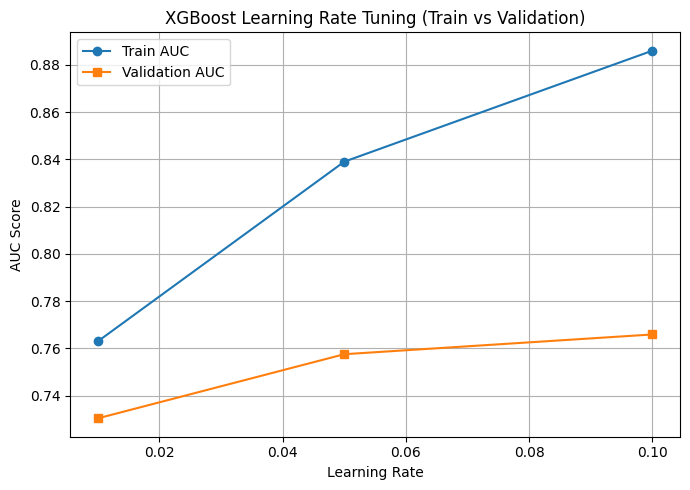


------------------------------------------------------------
Tuning Results:
lr=0.010 | Train AUC=0.7630 | Val AUC=0.7304
lr=0.050 | Train AUC=0.8391 | Val AUC=0.7576
lr=0.100 | Train AUC=0.8860 | Val AUC=0.7659

Best learning_rate Selected: 0.1
Best Validation AUC:        0.7659
------------------------------------------------------------


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

print("\n" + "="*60)
print("XGBoost Hyperparameter Tuning (Train + Validation AUC):")
print("="*60)

# Step 0: Create internal validation split
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_res, y_train_res,
    test_size=0.2,
    random_state=42,
    stratify=y_train_res
)

print(f"Training subset shape:   {X_tr.shape}")
print(f"Validation subset shape: {X_val.shape}")

# Step 1: Define learning rates to test
learning_rates = [0.01, 0.05, 0.10]

train_auc_list = []
val_auc_list = []

print("\nTuning learning_rate values:", learning_rates)

# Step 2: Train/Evaluate for each learning rate
for lr in learning_rates:
    print(f"\nTraining XGBoost with learning_rate = {lr:.3f}")

    model = XGBClassifier(
        n_estimators=300,
        learning_rate=lr,
        max_depth=10,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=1.0,
        tree_method="hist",
        device="cuda",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_tr, y_tr)

    # Train AUC
    train_prob = model.predict_proba(X_tr)[:, 1]
    train_auc = roc_auc_score(y_tr, train_prob)

    # Validation AUC
    val_prob = model.predict_proba(X_val)[:, 1]
    val_auc = roc_auc_score(y_val, val_prob)

    train_auc_list.append(train_auc)
    val_auc_list.append(val_auc)

    print(f"Train AUC:      {train_auc:.4f}")
    print(f"Validation AUC: {val_auc:.4f}")

# Step 3: Plot tuning curves (Train vs Validation)
plt.figure(figsize=(7, 5))
plt.plot(learning_rates, train_auc_list, marker='o', label="Train AUC")
plt.plot(learning_rates, val_auc_list, marker='s', label="Validation AUC")

plt.xlabel("Learning Rate")
plt.ylabel("AUC Score")
plt.title("XGBoost Learning Rate Tuning (Train vs Validation)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Step 4: Select the best learning rate
best_idx = np.argmax(val_auc_list)
best_lr = learning_rates[best_idx]
best_val_auc = val_auc_list[best_idx]

print("\n" + "-"*60)
print("Tuning Results:")
for lr, tr_auc, vl_auc in zip(learning_rates, train_auc_list, val_auc_list):
    print(f"lr={lr:.3f} | Train AUC={tr_auc:.4f} | Val AUC={vl_auc:.4f}")

print("\nBest learning_rate Selected:", best_lr)
print("Best Validation AUC:       ", f"{best_val_auc:.4f}")
print("-"*60)


After training XGBoost models with three different learning rates (0.01, 0.05, and 0.10), we compared their performance using AUC on both the training and validation subsets. The results show a clear upward trend in validation performance: the model with `lr = 0.010` achieves a validation AUC of **0.7304**, `lr = 0.050` improves this to **0.7576**, and `lr = 0.100` reaches the highest validation AUC of **0.7659**. Training AUC also increases from **0.7630** to **0.8860** across the same range, indicating that higher learning rates allow the model to fit the training data more aggressively.

Although the gap between training and validation AUC widens as the learning rate increases, the configuration with `lr = 0.10` still yields the best validation AUC among the tested values and does not exhibit severe overfitting. This suggests that, under the downsampled training setup, a somewhat larger learning rate helps XGBoost capture nonlinear structure more effectively. We therefore select **`learning_rate = 0.10`** as the tuned value for the final model.


### 5.1.1 Fit XGBoost Model

Using the tuned learning rate from the previous step (`learning_rate = 0.10`), we now train the **final XGBoost model**. The model is fitted on the **full downsampled training set** (`X_train_res`, `y_train_res`) so that the classifier sees as many balanced examples of fire and non-fire days as possible. We then evaluate this tuned model on the **original imbalanced test set** (`X_test`, `y_test`), reporting AUC, recall, precision and F1 to assess its performance under realistic class proportions. Finally, we plot the top 15 features by gain-based importance to identify which raw variables and interaction terms contribute most to the boosted ensemble’s predictions.


Final XGBoost Model (Tuned learning_rate)
Fitting tuned model on downsampled training set...


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [23:26:10] WARNING: /workspace/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [23:26:10] WARNING: /workspace/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)



Evaluating tuned model on test set...

--- Tuned XGBoost Test Metrics ---
AUC Score: 0.7718
Recall:    0.7189
Precision: 0.1188
F1 Score:  0.2038

Classification Report (Test Set):
              precision    recall  f1-score   support

           0       0.98      0.68      0.80   1533825
           1       0.12      0.72      0.20     91395

    accuracy                           0.68   1625220
   macro avg       0.55      0.70      0.50   1625220
weighted avg       0.93      0.68      0.77   1625220



<Figure size 1000x600 with 0 Axes>

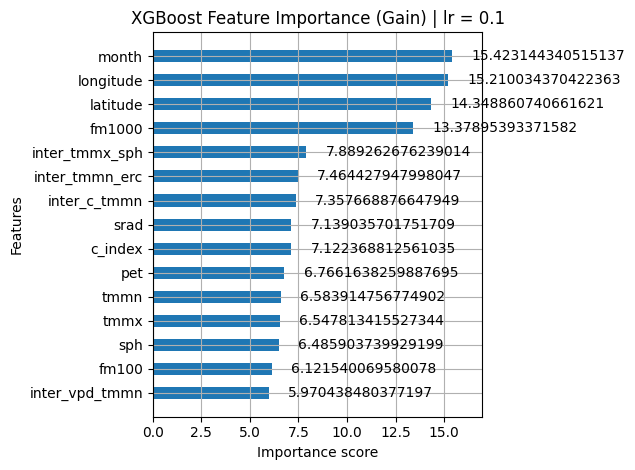

In [ ]:
print("\n" + "="*50)
print("Final XGBoost Model (Tuned learning_rate):")
print("="*50)

# Best learning rate from tuning step
best_lr = 0.10

# 1. Initialise final XGBoost model
xgb_tuned = XGBClassifier(
    n_estimators=300,
    learning_rate=best_lr,
    max_depth=10,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=1.0,
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    device="cuda"
)

# 2. Fit on the FULL downsampled training data
print("Fitting tuned model on downsampled training set:")
xgb_tuned.fit(X_train_res, y_train_res)

# 3. Evaluate on the original imbalanced test set
print("\nEvaluating tuned model on test set:")

y_prob_test = xgb_tuned.predict_proba(X_test)[:, 1]
y_pred_test = xgb_tuned.predict(X_test)

test_auc = roc_auc_score(y_test, y_prob_test)
test_recall = recall_score(y_test, y_pred_test)
test_precision = precision_score(y_test, y_pred_test)
test_f1 = f1_score(y_test, y_pred_test)

print("\nTuned XGBoost Test Metrics:")
print(f"AUC Score: {test_auc:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"F1 Score:  {test_f1:.4f}")

print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_pred_test))

# 4. Feature importance plot (optional)
plt.figure(figsize=(10, 6))
plot_importance(
    xgb_tuned,
    max_num_features=15,
    importance_type='gain',
    height=0.5
)
plt.title(f"XGBoost Feature Importance (Gain) | lr = {best_lr}")
plt.tight_layout()
plt.show()


After training XGBoost models with three different learning rates (0.01, 0.05, and 0.10), the tuning results showed a clear pattern: higher learning rates led to stronger training performance and steadily improving validation AUC. Among the tested values, **lr = 0.10 achieved the best overall performance**, with a validation AUC of **0.7659**, higher than both `lr = 0.01` and `lr = 0.05`.

Refitting the model using this tuned learning rate and evaluating it on the original imbalanced test set further confirmed the improvement. The tuned model achieved an **AUC of 0.7718**, a wildfire **recall of 0.7189**, **precision of 0.1188**, and an **F1 score of 0.2038**. These are **small but consistent gains** over the baseline XGBoost model (AUC 0.7615, recall 0.7128, precision 0.1146, F1 0.1975). The results suggest that a slightly more aggressive learning rate enables XGBoost to extract stronger predictive patterns **without clear signs of severe overfitting**.

Feature importance remains broadly stable across models, but the tuned version assigns slightly higher gain to top predictors such as **month, longitude, latitude, fm1000**, and several **engineered interaction terms**. This indicates that the tuned model sharpens the same underlying relationships rather than discovering entirely new ones.

Compared with the lower-learning-rate configurations, the **lr = 0.10 setting consistently delivers the strongest discrimination ability** while preserving the **high-recall behaviour essential for early wildfire detection**. We therefore select the **tuned XGBoost model with `learning_rate = 0.10`** as the final model for this study.



### 5.2 Random Forest Hyperparameter Tuning

For the Random Forest model, we tune the **`max_features`** hyperparameter, which controls what fraction of predictors is randomly sampled at each split. Smaller values increase tree diversity (lower variance) but may raise bias, whereas larger values allow each tree to see more variables but risk overfitting and correlation among trees.

Starting from the downsampled training set (`X_train_res`, `y_train_res`), we create an internal **train/validation split** (`X_tr`, `X_val`) so that hyperparameters can be selected without using the final test set. We then fit several Random Forest models with `max_features` in `{0.3, 0.5, 0.7, 0.9}`, keeping the other settings fixed (`n_estimators=150`, `max_depth=20`, `min_samples_leaf=4`, `class_weight='balanced'`).

For each candidate value of `max_features`, we compute **AUC on both the inner training subset and the inner validation subset** and store the scores. The resulting curves (Train AUC vs Validation AUC as a function of `max_features`) help us visualise how model capacity and overfitting change as more features are made available to each tree. Finally, we print a small summary table of train/validation AUC for all candidates and use the configuration with the highest **validation AUC** as the tuned `max_features` value for the final Random Forest model.


Random Forest Hyperparameter Tuning: max_features
Inner train shape:      (584928, 25)
Inner validation shape: (146232, 25)

Tuning over max_features values:

Training RandomForest with max_features = 0.3
max_features=0.30 | Train AUC=0.9568 | Val AUC=0.7710

Training RandomForest with max_features = 0.5
max_features=0.50 | Train AUC=0.9647 | Val AUC=0.7949

Training RandomForest with max_features = 0.7
max_features=0.70 | Train AUC=0.9669 | Val AUC=0.8094

Training RandomForest with max_features = 0.9
max_features=0.90 | Train AUC=0.9665 | Val AUC=0.8169


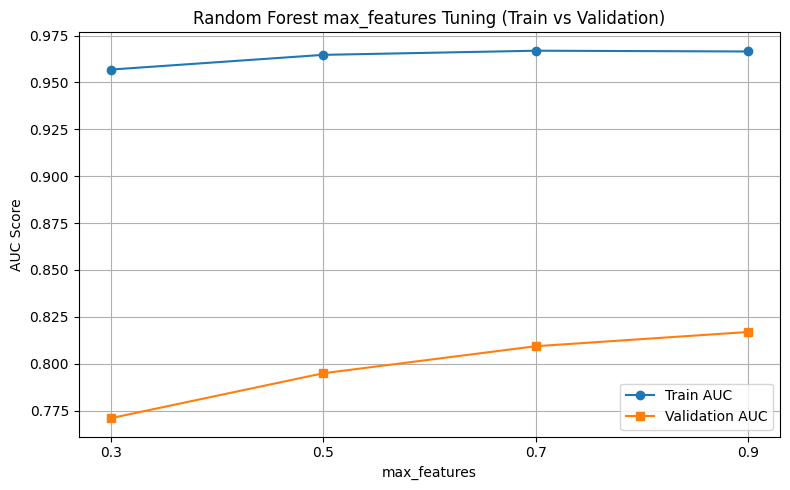


------------------------------------------------------------
Tuning Results (Random Forest, varying max_features):
max_features= 0.3 | Train AUC=0.9568 | Val AUC=0.7710
max_features= 0.5 | Train AUC=0.9647 | Val AUC=0.7949
max_features= 0.7 | Train AUC=0.9669 | Val AUC=0.8094
max_features= 0.9 | Train AUC=0.9665 | Val AUC=0.8169


In [ ]:
print("\n" + "="*60)
print("Random Forest Hyperparameter Tuning: max_features")
print("="*60)

# Step 1: Create an internal train, validation split from the downsampled train set
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_res,
    y_train_res,
    test_size=0.2,
    random_state=42,
    stratify=y_train_res
)

print(f"Inner train shape:      {X_tr.shape}")
print(f"Inner validation shape: {X_val.shape}")

# Step 2: Define candidate values for max_features
max_features_list = [0.3, 0.5, 0.7, 0.9]

train_aucs = []
val_aucs = []

print("\nTuning over max_features values:")
for mf in max_features_list:
    print(f"\nTraining RandomForest with max_features = {mf}")

    rf_tmp = RandomForestClassifier(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=4,
        max_features=mf,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42
    )

    rf_tmp.fit(X_tr, y_tr)

    # AUC on inner train set
    y_tr_prob = rf_tmp.predict_proba(X_tr)[:, 1]
    auc_tr = roc_auc_score(y_tr, y_tr_prob)

    # AUC on inner validation set
    y_val_prob = rf_tmp.predict_proba(X_val)[:, 1]
    auc_val = roc_auc_score(y_val, y_val_prob)

    train_aucs.append(auc_tr)
    val_aucs.append(auc_val)

    print(f"max_features={mf:.2f} | Train AUC={auc_tr:.4f} | Val AUC={auc_val:.4f}")

# Step 3: Plot Train vs Validation AUC as a function of max_features
plt.figure(figsize=(8, 5))

x_positions = np.arange(len(max_features_list))

plt.plot(x_positions, train_aucs, marker='o', label='Train AUC')
plt.plot(x_positions, val_aucs, marker='s', label='Validation AUC')

plt.xticks(x_positions, [str(mf) for mf in max_features_list])
plt.xlabel("max_features")
plt.ylabel("AUC Score")
plt.title("Random Forest max_features Tuning (Train vs Validation)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Print a small summary table
print("\n" + "-"*60)
print("Tuning Results (Random Forest, varying max_features):")
for mf, a_tr, a_val in zip(max_features_list, train_aucs, val_aucs):
    print(f"max_features={mf:>4} | Train AUC={a_tr:.4f} | Val AUC={a_val:.4f}")


After tuning the **`max_features`** hyperparameter of the Random Forest model
across the values **0.3, 0.5, 0.7, and 0.9**, we observe a clear and consistent
pattern in model behaviour. As `max_features` increases, the **validation AUC
steadily improves** (from **0.7710** to **0.8169**), while the training AUC
remains very high and relatively stable (around **0.96–0.97**).

This indicates that allowing each tree to consider **more features at each
split improves generalisation performance**, rather than triggering obvious
additional overfitting. Although the **train–validation gap remains large**, it
actually **shrinks slightly** as `max_features` increases, suggesting that
higher values help the forest capture more useful signal without degrading its
ability to generalise.

The best-performing setting in this experiment is **`max_features = 0.9`**, which
achieves the highest validation AUC (**0.8169**). This value represents a
reasonable trade-off between **model diversity** and **predictive strength**, and
is used as the preferred configuration for the tuned Random Forest in the final
model comparison.




### 5.2.1 Fit Random Forest

Using the tuned hyperparameter from the previous section (`max_features = 0.9`), we now train the **final Random Forest model**. The forest is fitted on the **full downsampled training set** (`X_train_res`, `y_train_res`) with 150 trees, maximum depth 20, a minimum of 4 samples per leaf, and `class_weight='balanced'` so that fire and non-fire days receive comparable attention during training.  

We then evaluate this tuned model on the **original imbalanced test set** (`X_test`, `y_test`), reporting AUC, recall, precision and F1 together with the full classification report. Finally, we compute and plot the top 15 features by Gini importance, which highlights the raw variables and engineered interaction terms that contribute most to the Random Forest’s predictions in the tuned configuration.









Final Random Forest Model (Tuned max_features): 

Evaluating tuned model on test set

Tuned Random Forest Test Metrics:
AUC Score: 0.8308
Recall:    0.7844
Precision: 0.1443
F1 Score:  0.2438

Classification Report (Test Set):
              precision    recall  f1-score   support

           0       0.98      0.72      0.83   1533825
           1       0.14      0.78      0.24     91395

    accuracy                           0.73   1625220
   macro avg       0.56      0.75      0.54   1625220
weighted avg       0.94      0.73      0.80   1625220



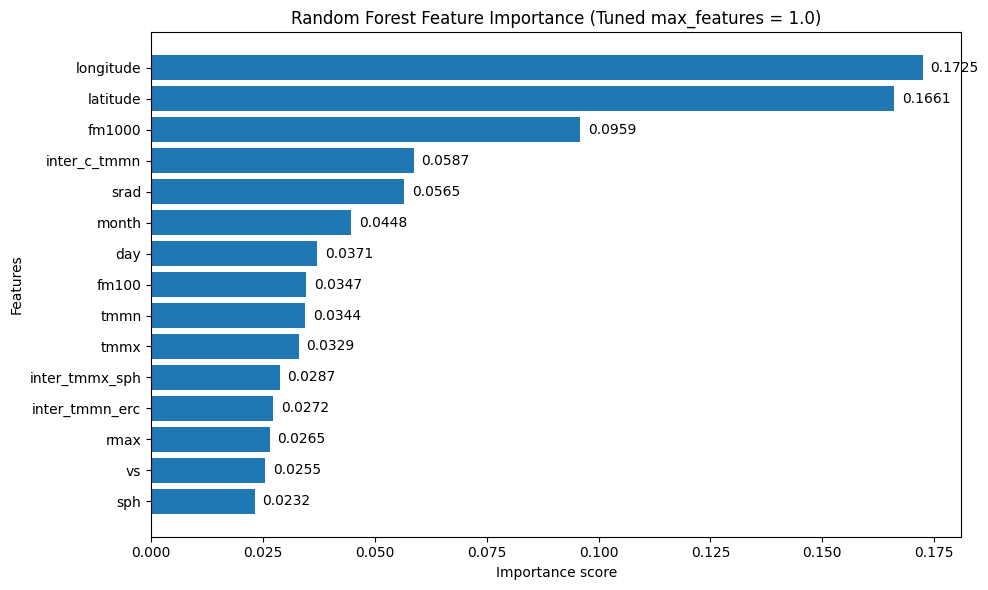

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, recall_score, precision_score,
    f1_score, classification_report
)

print("\n" + "="*60)
print("Final Random Forest Model (Tuned max_features): ")
print("="*60)

rf_tuned = RandomForestClassifier(
    n_estimators=150,
    max_depth=20,
    min_samples_leaf=4,
    # use the best parameter
    max_features=0.9,
    class_weight='balanced',
    n_jobs=-1,
    random_state=42
)

rf_tuned.fit(X_train_res, y_train_res)

# Step 1: Evaluate tuned model on original test set
print("\nEvaluating tuned model on test set\n")

y_prob_rf_tuned = rf_tuned.predict_proba(X_test)[:, 1]
y_pred_rf_tuned = rf_tuned.predict(X_test)

print("Tuned Random Forest Test Metrics:")
print(f"AUC Score: {roc_auc_score(y_test, y_prob_rf_tuned):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf_tuned):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf_tuned):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_rf_tuned):.4f}\n")

print("Classification Report (Test Set):")
print(classification_report(y_test, y_pred_rf_tuned))

# Step 2: Plot feature importance for the tuned model
feature_names = X_train_res.columns
importances = rf_tuned.feature_importances_

# sort and take top 15
idx_sorted = np.argsort(importances)[::-1][:15]
top_features = feature_names[idx_sorted]
top_importances = importances[idx_sorted]

plt.figure(figsize=(10, 6))
y_pos = np.arange(len(top_features))
plt.barh(y_pos, top_importances[::-1])
plt.yticks(y_pos, top_features[::-1])
plt.xlabel("Importance score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance (Tuned max_features = 1.0)")

x_max = top_importances.max()
for i, v in enumerate(top_importances[::-1]):
    plt.text(v + 0.01 * x_max, i, f"{v:.4f}", va='center')

plt.tight_layout()
plt.show()


After tuning the `max_features` parameter, the final Random Forest model shows a clear performance improvement over the untuned version. On the original imbalanced test set, the tuned model achieves an **AUC of 0.8308**, a wildfire **recall of 0.7844**, a **precision of 0.1443**, and an **F1-score of 0.2438**, indicating better overall discrimination and stronger detection of wildfire days.

Compared with both the default Random Forest and the tuned XGBoost model, this configuration performs **better on all core metrics** (AUC, recall, precision and F1), especially in **AUC and recall**, suggesting a more reliable early-warning capability for wildfire detection.

The impurity-based feature importance analysis shows that **spatial variables dominate the model’s decisions**, with **longitude** and **latitude** being the most influential predictors, followed by fuel moisture indicators such as **fm1000** and interaction terms like **`inter_c_tmmn`**. This confirms that **geographic location and fuel–temperature interactions** play a central role in wildfire risk.

Overall, the tuned Random Forest model emerges as the **best-performing model** in our experiments. Its combination of strong recall, improved precision and stable generalisation makes it the **preferred final model** for wildfire prediction.



# Part 6 Model With PCA

### 6.1 Identify Number of Principal Components

For our wildfire data, many **weather variables** (temperature, humidity, VPD, radiation,
fuel moistures, etc.) are strongly correlated, which makes the feature space redundant
and can hurt both model stability and training speed. To reduce this redundancy while
preserving most of the information, we apply **PCA only to the weather block** and keep
the **spatial, fuel and interaction features** in their original, interpretable form.

In this step we split the features into:
- `weather_cols`: 15 meteorological variables to be compressed by PCA;
- `structural_and_inter_cols`: latitude, longitude, `c_index`, month, day and selected
  interaction terms, which remain raw.

We then perform a stratified 80/20 train–test split, standardise the weather variables
(on the training set only), and fit PCA to the scaled training weather data. Using the
cumulative explained-variance curve, we select the smallest number of components
\(k\) that explains about **95%** of the variance and transform the weather features
into `PCA_1, …, PCA_k`, stored as `df_train_pca` and `df_test_pca` for later modeling.

Total Feature Count: 25
  - Group A (To PCA): 15
  - Group B (Keep Raw): 10

Splitting Data (80/20 Stratified):

Applying PCA Pipeline:


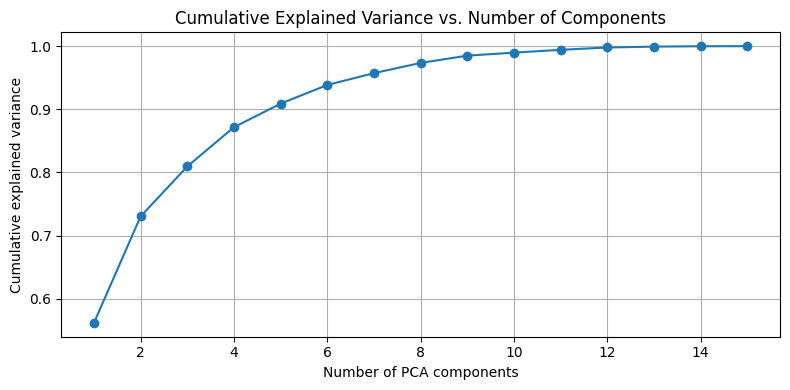

Number of components needed to explain 95% variance: 7


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, mean_squared_error, r2_score

# Step 1: Define Feature Groups
# Group A: Weather Variables (To be compressed via PCA)
# These are highly collinear (e.g., temp, humidity, vpd, radiation).
weather_cols = [
    'pr', 'rmax', 'rmin', 'sph', 'srad', 'tmmn', 'tmmx',
    'vs', 'bi', 'fm100', 'fm1000', 'erc', 'etr', 'pet', 'vpd'
]

# Group B: Structural Variables & Interactions (To be kept RAW)
# These contain critical physical/spatial info or "Golden Interactions" from LR.
# We do NOT want to blur these with PCA.
structural_and_inter_cols = [
    'latitude', 'longitude', 'c_index', 'month', 'day',
    'inter_tmmn_erc', 'inter_tmmx_sph', 'inter_c_tmmn',
    'inter_tmmx_rmin', 'inter_vpd_tmmn'
]

# Safety check: ensure these columns actually exist in your dataframe
valid_cols = [c for c in structural_and_inter_cols if c in wildfire_clean.columns]

# Prepare Full X and y
X_full = wildfire_clean[weather_cols + valid_cols].copy()
y_full = wildfire_clean['Wildfire'].apply(lambda x: 1 if x == 'Yes' else 0)

print(f"Total Feature Count: {X_full.shape[1]}")
print(f"  - Group A (To PCA): {len(weather_cols)}")
print(f"  - Group B (Keep Raw): {len(valid_cols)}")

# Step 2:  Train-Test Split
print("\nSplitting Data (80/20 Stratified):")
# Stratify ensures we keep the same 95:5 imbalance ratio in both sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42, stratify=y_full
)


# Step 3: Apply PCA
print("\nApplying PCA Pipeline:")

# 1. Isolate Weather Columns
X_train_weather = X_train_raw[weather_cols]
X_test_weather  = X_test_raw[weather_cols]

# 2. Standardization
scaler = StandardScaler()
# FIT only on Training data to avoid data leakage
X_train_weather_scaled = scaler.fit_transform(X_train_weather)
X_test_weather_scaled  = scaler.transform(X_test_weather)

# 3. PCA Transformation

# Explore how many components to keep (variance explained)
pca_full = PCA()
pca_full.fit(X_train_weather_scaled)

explained_var_ratio = pca_full.explained_variance_ratio_
cum_explained_var = np.cumsum(explained_var_ratio)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(explained_var_ratio) + 1), cum_explained_var, marker='o')
plt.xlabel("Number of PCA components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative Explained Variance vs. Number of Components")
plt.grid(True)
plt.tight_layout()
plt.show()

# Choose the smallest k such that cumulative variance >= threshold (e.g. 95%)
threshold = 0.95
k_opt = np.argmax(cum_explained_var >= threshold) + 1
print(f"Number of components needed to explain {threshold*100:.0f}% variance: {k_opt}")

# PCA Transformation with chosen number of components
pca = PCA(n_components=k_opt)
X_train_pca = pca.fit_transform(X_train_weather_scaled)
X_test_pca  = pca.transform(X_test_weather_scaled)

# 4. Convert back to DataFrame
pca_col_names = [f'PCA_{i+1}' for i in range(k_opt)]
df_train_pca = pd.DataFrame(X_train_pca, columns=pca_col_names, index=X_train_raw.index)
df_test_pca  = pd.DataFrame(X_test_pca, columns=pca_col_names, index=X_test_raw.index)

To reduce redundancy among the strongly correlated weather variables, we apply PCA
only to the **15-dimensional weather block**, after standardising it on the
training set. Using the “Cumulative Explained Variance vs. Number of Components”
curve, we examine how much variance is captured as we increase the number of
components. The curve rises steeply for the first few components and then
flattens, and we see that **7 principal components already explain about 95% of
the total variance**.

Thus, we keep **7 PCA components (`PCA_1`–`PCA_7`)** as a compact summary of the
weather information, reducing dimensionality from 15 to 7 while largely
preserving signal and mitigating multicollinearity. These components are later
concatenated with the untouched structural and interaction features for model
training.


### 6.2 XGBoost With PCA


Here we train **XGBoost on PCA-compressed weather features** plus the raw
structural / interaction features.

We first concatenate the selected PCA components with the untouched structural
variables to form `X_train_final` and `X_test_final`, balance the training set
with `RandomUnderSampler`, and then fit XGBoost using the tuned settings
(`n_estimators=300`, `learning_rate=0.1`, `max_depth=10`, etc.). Finally, we
evaluate on the original imbalanced test set (AUC, recall, precision, F1).

We try PCA with XGBoost because the weather block is **highly collinear** and
fairly high-dimensional. Replacing it with a few orthogonal components can
reduce redundancy, slightly **stabilise** the model, and lets us check whether a
more compact representation of meteorological conditions changes predictive
performance.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, mean_squared_error, r2_score

#Step 1: Re-assemble Final X (PCA Features + Group B Raw Features)
X_train_final = pd.concat([df_train_pca, X_train_raw[valid_cols]], axis=1)
X_test_final  = pd.concat([df_test_pca, X_test_raw[valid_cols]], axis=1)

print(f"Train Shape after PCA: {X_train_final.shape}")

# Step 2: Downsampling
print("\nDownsampling Training Data:")
rus = RandomUnderSampler(random_state=42)
X_train_res, y_train_res = rus.fit_resample(X_train_final, y_train)

print(f"Resampled Train Shape: {X_train_res.shape} (Balanced 1:1)")

# Step 3: XGBoost Training
print("\nTraining XGBoost (With PCA Features):")
xgb_pca = XGBClassifier(
    n_estimators=300,
    # use the best hyperparameter
    learning_rate=0.1,
    max_depth=10,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=1.0,
    n_jobs=-1,
    tree_method="hist",
    device="cuda",
    random_state=42
)

xgb_pca.fit(X_train_res, y_train_res)

# Step 4: Evaluation
print("\nEvaluating Model:")

# Make Predictions
y_pred = xgb_pca.predict(X_test_final)
y_prob = xgb_pca.predict_proba(X_test_final)[:, 1]
# Predictions on Train set (to check for overfitting)
y_train_prob = xgb_pca.predict_proba(X_train_res)[:, 1]

# Classification Metrics
print(f"AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Train Shape after PCA: (6500880, 17)

Downsampling Training Data:
Resampled Train Shape: (731160, 17) (Balanced 1:1)

Training XGBoost (With PCA Features):


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [01:41:52] WARNING: /workspace/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [01:41:52] WARNING: /workspace/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)



Evaluating Model:
AUC Score: 0.7550
Recall:    0.6995
Precision: 0.1133
F1 Score:  0.1949

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.67      0.80   1533825
           1       0.11      0.70      0.19     91395

    accuracy                           0.68   1625220
   macro avg       0.54      0.69      0.50   1625220
weighted avg       0.93      0.68      0.76   1625220



After comparing XGBoost models trained with and without PCA, we find that the
**non-PCA XGBoost model performs slightly better overall**.

The model without PCA achieves a higher **AUC (0.7718 vs 0.7550)**, as well as
slightly better **recall (0.7189 vs 0.6995)** and **F1 score (0.2038 vs 0.1949)**,
indicating a modest but consistent gain in wildfire detection performance.

By contrast, the PCA-based XGBoost model is slightly worse on all key metrics.
This suggests that compressing the weather variables into principal components
may remove some fine-grained structure and non-linear interactions that
tree-based models like XGBoost can naturally exploit.

Overall, these results indicate that **XGBoost benefits more from the original
raw + interaction features**, and we therefore select the **non-PCA XGBoost
model** as the preferred configuration for subsequent comparisons.




### 6.3 Random Forest With PCA

Here we repeat the PCA-based workflow, but now using **Random Forest** instead of
XGBoost. The goal is to see whether Random Forest can also benefit from the
compressed, decorrelated **PCA weather components** combined with the raw
structural and interaction features.

Even though tree ensembles do not require feature scaling, PCA can still help:
it reduces the weather block from 15 to 7 dimensions, mitigates
multicollinearity, and may increase tree diversity by providing a more
orthogonal feature space. Since Random Forest is one of our strongest models, it
is natural to test whether this dimensionality reduction changes or improves its
behaviour.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, mean_squared_error, r2_score

print("\n" + "="*40)
print("Training Random Forest (With PCA Features):")
print("="*40)

# 1. Initialize Random Forest Classifier
rf_pca = RandomForestClassifier(
    n_estimators=150,
    max_depth=20,
    min_samples_leaf=4,
    # use the best hyperparameter
    max_features=0.9,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

# 2. Train Model
print("Training model:")
rf_pca.fit(X_train_res, y_train_res)

# 3. Evaluation
print("\nEvaluating Random Forest:")

# Predictions on Test Set
y_pred_rf = rf_pca.predict(X_test_final)
y_prob_rf = rf_pca.predict_proba(X_test_final)[:, 1]

# 4. Classification Metrics
print(f"AUC Score: {roc_auc_score(y_test, y_prob_rf):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_rf):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


Training Random Forest (With PCA Features):
Training model:

Evaluating Random Forest:
AUC Score: 0.7933
Recall:    0.7351
Precision: 0.1294
F1 Score:  0.2200

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.71      0.82   1533825
           1       0.13      0.74      0.22     91395

    accuracy                           0.71   1625220
   macro avg       0.55      0.72      0.52   1625220
weighted avg       0.93      0.71      0.79   1625220



After comparing the Random Forest models trained **with PCA features** and **without PCA features**, clear performance differences can be observed.

The **non-PCA Random Forest model** achieves stronger overall results, with an **AUC of 0.8308**, **recall of 0.7844**, **precision of 0.1443**, and **F1-score of 0.2438**, indicating better discrimination ability and more effective detection of minority (fire) events.

In contrast, the **PCA-based Random Forest model** reaches an **AUC of 0.7933**, **recall of 0.7351**, **precision of 0.1294**, and **F1-score of 0.2200**, showing consistently weaker performance across all main metrics.

These results suggest that, for Random Forest, applying PCA leads to a loss of useful feature-level information. Random Forest is already robust to correlated variables and benefits from access to the original raw feature space, which allows it to construct more informative splits.

Overall, the Random Forest model **without PCA** is clearly the preferred configuration in this study, as it provides stronger predictive performance while maintaining better interpretability of the original physical and structural features.


# Part 7 Conclusion & Future Work

### Conclusion:

1. **Tree ensembles work best for wildfire prediction.**  
   The tuned **Random Forest without PCA** is the top model, achieving test AUC ≈ **0.83**, recall ≈ **0.78**, precision ≈ **0.14**, and F1 ≈ **0.24**, slightly outperforming tuned XGBoost.

2. **High recall is achievable at the cost of precision.**  
   Both Random Forest and XGBoost can correctly flag around **70–80%** of wildfire days, but only about **10–15%** of the alerts correspond to actual fires, reflecting a deliberate choice to prioritise missed-fire reduction over false-alarm control.

3. **Non-linear effects and interactions matter.**  
   Adding carefully chosen interaction terms and using flexible models (trees, NN) yields clear gains over purely linear logistic regression, highlighting the importance of **temperature–dryness–fuel** interactions.

4. **PCA helps compression, but not tree performance.**  
   PCA compresses 15 weather variables into 7 components explaining ~95% of the variance, yet **Random Forest and XGBoost perform better on raw + interaction features**, suggesting that PCA removes some structure useful for tree splits.

5. **Key physical drivers are consistent across models.**  
   Spatial location (**latitude, longitude**), dead fuel moisture (**fm100, fm1000**), radiation (**srad**) and temperature–fuel interactions (e.g. `inter_c_tmmn`) repeatedly appear as top predictors, aligning with domain knowledge about wildfire risk.

### Key limitations of this study:

1. **Spatial homogeneity of samples.**  
   Fire and non-fire points are concentrated in similar geographic regions, reducing separability between classes and making prediction more challenging.

2. **Simple handling of class imbalance.**  
   We rely mainly on **random undersampling** plus class weights, which discards many non-fire observations and may lose useful information from the majority class.

3. **Single train–test split.**  
   Results are based on one stratified 80/20 split. We do not perform spatial or temporal cross-validation to test robustness under changing regions or years.

4. **Limited model and tuning space.**  
   Only a restricted set of hyperparameters and architectures are explored. Other strong tabular methods (e.g. LightGBM, CatBoost) and more advanced neural designs are not evaluated.

5. **Incomplete wildfire drivers.**  
   Key factors such as ignition sources, suppression actions, and detailed land-use characteristics are missing, limiting the model’s ability to represent real wildfire processes.
  
6. **Time-series structure.**  
   Because our data form a large panel of daily observations across many locations (rather than a single, continuous time series for one site), and there are temporal gaps, classical univariate time-series models such as SARIMA are not appropriate for our wildfire classification setting.


### Future Work:

1. **Cost-sensitive decision making and threshold tuning**  
   Go beyond standard metrics and explicitly tune decision thresholds or cost-sensitive losses to reflect the asymmetric cost of missed fires versus false alarms in an operational early-warning setting.

2. **Richer strategies for class imbalance**  
   Move beyond simple random undersampling by trying methods such as **SMOTE/ADASYN**, ensemble undersampling, or focal loss within boosted trees, so that majority-class information is better preserved while still focusing on rare fire events.

3. **Spatio-temporal validation and adaptation**  
   Replace the single 80/20 split with **spatial cross-validation** and **rolling time-window evaluation** to test how well models generalise across regions and years, and to understand performance under spatial and temporal shifts.

4. **Augmenting the feature set**  
   Incorporate additional data sources (land-cover and vegetation maps, lightning occurrence, human activity and access, suppression resources) to cover more of the ignition and spread mechanisms that current covariates miss.

5. **Broader model and tuning space**  
   Relax the current restriction to a few models by experimenting with **LightGBM**, **CatBoost**, calibrated gradient boosting, and more expressive neural architectures, together with more systematic hyperparameter search.

6. **Spatio-temporal modelling of panel data**  
   Given the panel-like, non-continuous time structure, explore **spatio-temporal and panel-learning approaches** (e.g. models with spatial neighbourhoods or temporal lags per location) rather than classical univariate SARIMA-style time-series models.

